In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv


In [2]:
# Cell 1: Import libraries and set random seeds

import os
import random
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef
)

from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import BorderlineSMOTE

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully.")
print("Random seed:", SEED)

Libraries imported successfully.
Random seed: 42


In [3]:
# Cell 2: Load and clean the WDBC dataset

# Load dataset
file_path = "/kaggle/input/datasets/uciml/breast-cancer-wisconsin-data/data.csv"
df = pd.read_csv(file_path)

# Remove unnecessary columns
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Convert diagnosis labels: B = 0, M = 1
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})

# Validate target labels
if df["diagnosis"].isna().any():
    raise ValueError("Unexpected or missing diagnosis labels found.")

# Separate features and target
X = df.drop(columns=["diagnosis"]).copy()
y = df["diagnosis"].astype(int).copy()

# Check missing values before splitting
print("Dataset shape:", df.shape)
print("Feature matrix shape:", X.shape)
print("\nClass distribution:")
print(y.value_counts().sort_index().rename(index={0: "Benign", 1: "Malignant"}))
print("\nMissing feature values:", int(X.isna().sum().sum()))

# Stop if missing values need to be handled
if X.isna().any().any():
    raise ValueError(
        "Missing feature values detected. Handle imputation inside each "
        "training fold; do not impute using the complete dataset."
    )

# Split BEFORE scaling, feature selection, or resampling
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())
print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Dataset shape: (569, 31)
Feature matrix shape: (569, 30)

Class distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64

Missing feature values: 0

Training samples: 455
Testing samples: 114

Training class distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing class distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import StratifiedKFold

# Outer 5-fold CV: performance evaluation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Inner 5-fold CV: hyperparameter tuning
inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Number of outer folds:", outer_cv.get_n_splits(X_train, y_train))
print("Number of inner folds:", inner_cv.get_n_splits(X_train, y_train))

Number of outer folds: 5
Number of inner folds: 5


In [5]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold

# Outer 5-fold CV
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store all outer and inner fold data
nested_fold_data = []

# Iterate through all 5 Outer folds
for outer_fold, (outer_train_idx, outer_val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):
    X_fold_train = X_train.iloc[outer_train_idx].copy()
    X_fold_val = X_train.iloc[outer_val_idx].copy()

    y_fold_train = y_train.iloc[outer_train_idx].copy()
    y_fold_val = y_train.iloc[outer_val_idx].copy()

    # Inner 5-fold CV within the current Outer training fold
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + outer_fold
    )

    inner_fold_data = []

    for inner_fold, (inner_train_idx, inner_val_idx) in enumerate(
        inner_cv.split(X_fold_train, y_fold_train), start=1
    ):
        inner_fold_data.append({
            "inner_fold": inner_fold,
            "X_train": X_fold_train.iloc[inner_train_idx].copy(),
            "X_val": X_fold_train.iloc[inner_val_idx].copy(),
            "y_train": y_fold_train.iloc[inner_train_idx].copy(),
            "y_val": y_fold_train.iloc[inner_val_idx].copy()
        })

    nested_fold_data.append({
        "outer_fold": outer_fold,
        "X_train": X_fold_train,
        "X_val": X_fold_val,
        "y_train": y_fold_train,
        "y_val": y_fold_val,
        "inner_folds": inner_fold_data
    })

    print(
        f"Outer Fold {outer_fold}: "
        f"Training = {X_fold_train.shape}, "
        f"Validation = {X_fold_val.shape}, "
        f"Inner folds = {len(inner_fold_data)}"
    )

print("\nAll Outer and Inner folds created successfully.")

Outer Fold 1: Training = (364, 30), Validation = (91, 30), Inner folds = 5
Outer Fold 2: Training = (364, 30), Validation = (91, 30), Inner folds = 5
Outer Fold 3: Training = (364, 30), Validation = (91, 30), Inner folds = 5
Outer Fold 4: Training = (364, 30), Validation = (91, 30), Inner folds = 5
Outer Fold 5: Training = (364, 30), Validation = (91, 30), Inner folds = 5

All Outer and Inner folds created successfully.


In [6]:
from sklearn.preprocessing import StandardScaler
import pandas as pd

scaled_nested_fold_data = []

# Process all 5 outer folds
for outer_data in nested_fold_data:

    inner_fold_data = []

    # Process inner folds within this outer training fold
    for inner_data in outer_data["inner_folds"]:

        X_inner_train = inner_data["X_train"]
        X_inner_val = inner_data["X_val"]

        y_inner_train = inner_data["y_train"]
        y_inner_val = inner_data["y_val"]

        # Fit scaler ONLY on inner training data
        scaler = StandardScaler()

        X_inner_train_scaled = pd.DataFrame(
            scaler.fit_transform(X_inner_train),
            columns=X_inner_train.columns,
            index=X_inner_train.index
        )

        # Transform validation data using the same scaler
        X_inner_val_scaled = pd.DataFrame(
            scaler.transform(X_inner_val),
            columns=X_inner_val.columns,
            index=X_inner_val.index
        )

        inner_fold_data.append({
            "inner_fold": inner_data["inner_fold"],
            "X_train_scaled": X_inner_train_scaled,
            "X_val_scaled": X_inner_val_scaled,
            "y_train": y_inner_train,
            "y_val": y_inner_val,
            "scaler": scaler
        })

    scaled_nested_fold_data.append({
        "outer_fold": outer_data["outer_fold"],
        "X_outer_train": outer_data["X_train"],
        "X_outer_val": outer_data["X_val"],
        "y_outer_train": outer_data["y_train"],
        "y_outer_val": outer_data["y_val"],
        "inner_folds": inner_fold_data
    })

    print(
        f"Outer Fold {outer_data['outer_fold']}: "
        f"{len(inner_fold_data)} inner folds scaled"
    )

print("Scaling completed for all outer and inner folds.")

Outer Fold 1: 5 inner folds scaled
Outer Fold 2: 5 inner folds scaled
Outer Fold 3: 5 inner folds scaled
Outer Fold 4: 5 inner folds scaled
Outer Fold 5: 5 inner folds scaled
Scaling completed for all outer and inner folds.


In [7]:
# ============================================================
# STEP 1: GAUSSIAN NEUTROSOPHIC TRANSFORMATION (T, I, F)
# Fit parameters on training data only
# ============================================================

import numpy as np
import pandas as pd


def fit_neutrosophic_transform(
    X_train,
    y_train,
    malignant_label=1,
    benign_label=0,
    eps=1e-8
):
    X_train = pd.DataFrame(X_train).copy()
    y_train = np.asarray(y_train).ravel()

    if len(X_train) != len(y_train):
        raise ValueError("X_train and y_train must have equal rows.")

    if not X_train.index.is_unique:
        raise ValueError("X_train must have a unique index.")

    if set(np.unique(y_train)) != {benign_label, malignant_label}:
        raise ValueError("Both classes must be present in training data.")

    X_values = X_train.to_numpy(dtype=float)

    if not np.isfinite(X_values).all():
        raise ValueError("Training data contains missing or infinite values.")

    malignant_mask = y_train == malignant_label
    benign_mask = y_train == benign_label

    params = {}

    for col in X_train.columns:
        X_mal = X_train.loc[malignant_mask, col]
        X_ben = X_train.loc[benign_mask, col]

        params[col] = {
            "mu_M": X_mal.mean(),
            "sigma_M": max(X_mal.std(ddof=0), eps),
            "mu_B": X_ben.mean(),
            "sigma_B": max(X_ben.std(ddof=0), eps)
        }

    return params


def apply_neutrosophic_transform(X, params):
    X = pd.DataFrame(X).copy()

    if list(X.columns) != list(params.keys()):
        raise ValueError(
            "Input feature columns must match the fitted training columns."
        )

    X_values = X.to_numpy(dtype=float)

    if not np.isfinite(X_values).all():
        raise ValueError("Input contains missing or infinite values.")

    T = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)
    F = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)

    for col in X.columns:
        p = params[col]

        T[col] = np.exp(
            -((X[col] - p["mu_M"]) ** 2)
            / (2 * p["sigma_M"] ** 2)
        )

        F[col] = np.exp(
            -((X[col] - p["mu_B"]) ** 2)
            / (2 * p["sigma_B"] ** 2)
        )

    I = 1.0 - (T - F).abs()

    return T, I, F

In [8]:
# ============================================================
# STEP 2: APPLY TRAINING-FITTED PARAMETERS TO VALIDATION/TEST
# ============================================================

def neutrosophic_transform_apply(X, params):
    """
    Apply Gaussian parameters fitted on training data only.
    Validation/test labels are not required.
    """

    X = pd.DataFrame(X).copy()

    # Ensure the input has exactly the features used during fitting
    expected_features = list(params.keys())

    missing_features = set(expected_features) - set(X.columns)
    extra_features = set(X.columns) - set(expected_features)

    if missing_features or extra_features:
        raise ValueError(
            f"Feature mismatch. Missing: {missing_features}; "
            f"Unexpected: {extra_features}"
        )

    # Maintain the original training feature order
    X = X[expected_features]

    # Validate numerical values
    X_values = X.to_numpy(dtype=float)

    if not np.isfinite(X_values).all():
        raise ValueError("X contains missing or infinite values.")

    T = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)
    F = pd.DataFrame(index=X.index, columns=X.columns, dtype=float)

    for col in X.columns:
        p = params[col]

        # Validate fitted parameters
        sigma_M = p["sigma_M"]
        sigma_B = p["sigma_B"]

        if (
            not np.isfinite(sigma_M)
            or not np.isfinite(sigma_B)
            or sigma_M <= 0
            or sigma_B <= 0
        ):
            raise ValueError(
                f"Invalid Gaussian standard deviation for feature: {col}"
            )

        # Truth membership: malignant-class Gaussian
        T[col] = np.exp(
            -((X[col] - p["mu_M"]) ** 2)
            / (2.0 * sigma_M ** 2)
        )

        # Falsity membership: benign-class Gaussian
        F[col] = np.exp(
            -((X[col] - p["mu_B"]) ** 2)
            / (2.0 * sigma_B ** 2)
        )

    # Indeterminacy membership
    I = 1.0 - (T - F).abs()

    return T, I, F


# ============================================================
# STEP 3: REVISED CRISP NEUTROSOPHIC SCORE
# ============================================================

def neutrosophic_score(T, I, F):
    """
    Revised score:
    S = (1 + T - F) / 2

    I is retained in the function for consistency with
    the neutrosophic representation, but is not directly
    used in the revised scalar aggregation.
    """

    if not (T.index.equals(I.index) and T.index.equals(F.index)):
        raise ValueError("T, I, and F must have matching row indices.")

    if not (T.columns.equals(I.columns) and T.columns.equals(F.columns)):
        raise ValueError("T, I, and F must have matching feature columns.")

    S = S = (1.0 + 2*(T - F)) / 3.0


    return S

In [9]:
# ============================================================
# NEUTROSOPHIC DANGER SAMPLE DETECTION
# ============================================================

import numpy as np

def neutrosophic_danger_samples(
    I_row_mean,
    y,
    minority_label=1,
    indeterminacy_threshold=None,
    top_fraction=0.5
):

    I_values = np.asarray(I_row_mean, dtype=float).ravel()
    y_values = np.asarray(y).ravel()

    if len(I_values) != len(y_values):
        raise ValueError("Input lengths must be equal.")

    if len(I_values) == 0:
        raise ValueError("Input data must not be empty.")

    if not np.isfinite(I_values).all():
        raise ValueError("Invalid indeterminacy values.")

    if np.any((I_values < 0) | (I_values > 1)):
        raise ValueError("Indeterminacy must lie in [0, 1].")

    if not 0 < top_fraction <= 1:
        raise ValueError("top_fraction must be in (0, 1].")

    minority_idx = np.flatnonzero(
        y_values == minority_label
    )

    if len(minority_idx) == 0:
        raise ValueError("Minority class not found.")

    minority_I = I_values[minority_idx]

    if indeterminacy_threshold is None:
        cutoff = np.quantile(
            minority_I,
            1.0 - top_fraction
        )
    else:
        if (
            not np.isfinite(indeterminacy_threshold)
            or not 0 <= indeterminacy_threshold <= 1
        ):
            raise ValueError("Invalid indeterminacy threshold.")

        cutoff = indeterminacy_threshold

    danger_mask = np.zeros(len(y_values), dtype=bool)

    danger_mask[minority_idx] = minority_I >= cutoff

    return danger_mask

In [10]:
params = fit_neutrosophic_transform(
    X_train=X_train,
    y_train=y_train,
    malignant_label=1,
    benign_label=0,
    eps=1e-8
)

In [11]:
T_train, I_train, F_train = apply_neutrosophic_transform(
    X_train,
    params
)

In [12]:
# Mean indeterminacy for each training sample
I_row_mean = I_train.mean(axis=1).to_numpy()

# Identify high-indeterminacy malignant samples
danger_mask = neutrosophic_danger_samples(
    I_row_mean=I_row_mean,
    y=y_train,
    minority_label=1,
    top_fraction=0.5
)

print("Total training samples:", len(y_train))
print("Total malignant samples:", np.sum(np.asarray(y_train) == 1))
print("Neutrosophic borderline samples:", danger_mask.sum())

Total training samples: 455
Total malignant samples: 170
Neutrosophic borderline samples: 85


In [13]:
borderline_indices = np.flatnonzero(danger_mask)

print("Borderline sample positions:")
print(borderline_indices)

print("Mean indeterminacy threshold:",
      np.quantile(
          I_row_mean[np.asarray(y_train) == 1],
          0.50
      ))

Borderline sample positions:
[  3   5   7   8   9  11  24  26  29  32  37  43  45  52  53  55  56  58
  60  65  85  95 108 110 120 130 131 136 141 142 144 146 152 170 178 180
 183 191 193 207 209 212 214 217 221 223 229 230 233 235 237 246 251 268
 281 283 286 288 290 292 294 301 308 310 312 314 315 316 337 346 362 367
 368 369 376 382 390 393 395 400 408 411 412 421 444]
Mean indeterminacy threshold: 0.5526306202397568


In [14]:
# Mean indeterminacy for each sample
I_row_mean = I_train.mean(axis=1).to_numpy()

# Identify high-indeterminacy malignant samples
danger_mask = neutrosophic_danger_samples(
    I_row_mean=I_row_mean,
    y=y_train,
    minority_label=1,
    top_fraction=0.5
)

print("Total training samples:", len(y_train))
print("Total malignant samples:", np.sum(np.asarray(y_train) == 1))
print("Neutrosophic borderline samples:", danger_mask.sum())

Total training samples: 455
Total malignant samples: 170
Neutrosophic borderline samples: 85


In [15]:
!pip install -q imbalanced-learn

import numpy as np
from collections import Counter
from imblearn.over_sampling import BorderlineSMOTE

In [16]:
# ============================================================
# BORDERLINE-SMOTE — SYNTHETIC SAMPLE GENERATION
# ============================================================

# Original training data
X_train_original = np.asarray(X_train)
y_train_original = np.asarray(y_train)

# Check original class distribution
print("Original training distribution:",
      Counter(y_train_original))

# Apply Borderline-SMOTE ONLY to training data
borderline_smote = BorderlineSMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5,
    m_neighbors=10,
    kind='borderline-1'
)

X_train_smote, y_train_smote = borderline_smote.fit_resample(
    X_train_original,
    y_train_original
)

# Check resampled distribution
print("\nAfter Borderline-SMOTE:",
      Counter(y_train_smote))

print("\nOriginal training shape:", X_train_original.shape)
print("Resampled training shape:", X_train_smote.shape)

# Number of generated synthetic samples
synthetic_count = len(y_train_smote) - len(y_train_original)

print("\nSynthetic samples generated:", synthetic_count)

Original training distribution: Counter({np.int64(0): 285, np.int64(1): 170})

After Borderline-SMOTE: Counter({np.int64(1): 285, np.int64(0): 285})

Original training shape: (455, 30)
Resampled training shape: (570, 30)

Synthetic samples generated: 115


In [17]:
# ============================================================
# COUNT NEUTROSOPHIC DANGER SAMPLES IN EACH INNER TRAINING FOLD
# ============================================================

import numpy as np

for outer_data in scaled_nested_fold_data:

    outer_fold = outer_data["outer_fold"]

    for fold_data in outer_data["inner_folds"]:

        inner_fold = fold_data["inner_fold"]

        # Inner training data only
        X_inner_train = fold_data["X_train_scaled"]
        y_inner_train = fold_data["y_train"]

        # Fit neutrosophic parameters using training data only
        params = fit_neutrosophic_transform(
            X_inner_train,
            y_inner_train
        )

        # Calculate T, I, F using training-fitted parameters
        T_train, I_train, F_train = neutrosophic_transform_apply(
            X_inner_train,
            params
        )

        # Mean indeterminacy for each training sample
        I_row_mean_train = I_train.mean(axis=1).to_numpy()

        # Detect minority-class danger samples
        danger_mask = neutrosophic_danger_samples(
            I_row_mean=I_row_mean_train,
            y=y_inner_train,
            minority_label=1,
            top_fraction=0.5
        )

        # Store results for subsequent processing
        fold_data["I_train"] = I_train
        fold_data["danger_mask_train"] = danger_mask
        fold_data["neutrosophic_params"] = params

        # Count samples
        y_train_array = np.asarray(y_inner_train).ravel()

        n_total = len(y_train_array)
        n_minority = np.sum(y_train_array == 1)
        n_danger = np.sum(danger_mask)

        print(
            f"\nOuter Fold {outer_fold}, "
            f"Inner Fold {inner_fold}"
        )
        print("Total training samples:", n_total)
        print("Malignant samples:", n_minority)
        print("Danger samples:", n_danger)

        if n_minority > 0:
            print(
                "Percentage of malignant samples selected:",
                round(100 * n_danger / n_minority, 2),
                "%"
            )

print("\nDanger-sample detection completed.")


Outer Fold 1, Inner Fold 1
Total training samples: 291
Malignant samples: 108
Danger samples: 54
Percentage of malignant samples selected: 50.0 %

Outer Fold 1, Inner Fold 2
Total training samples: 291
Malignant samples: 109
Danger samples: 55
Percentage of malignant samples selected: 50.46 %

Outer Fold 1, Inner Fold 3
Total training samples: 291
Malignant samples: 109
Danger samples: 55
Percentage of malignant samples selected: 50.46 %

Outer Fold 1, Inner Fold 4
Total training samples: 291
Malignant samples: 109
Danger samples: 55
Percentage of malignant samples selected: 50.46 %

Outer Fold 1, Inner Fold 5
Total training samples: 292
Malignant samples: 109
Danger samples: 55
Percentage of malignant samples selected: 50.46 %

Outer Fold 2, Inner Fold 1
Total training samples: 291
Malignant samples: 108
Danger samples: 54
Percentage of malignant samples selected: 50.0 %

Outer Fold 2, Inner Fold 2
Total training samples: 291
Malignant samples: 109
Danger samples: 55
Percentage of ma

In [18]:
# ============================================================
# DISPLAY NEUTROSOPHIC MEMBERSHIPS — INNER TRAINING DATA
# ============================================================

for outer_data in scaled_nested_fold_data:

    outer_fold = outer_data["outer_fold"]

    for fold_data in outer_data["inner_folds"]:

        inner_fold = fold_data["inner_fold"]

        # Get the training data and its fitted parameters
        X_inner_train = fold_data["X_train_scaled"]
        params = fold_data["neutrosophic_params"]

        # Apply the same training-fitted parameters
        T_inner_train, I_inner_train, F_inner_train = (
            neutrosophic_transform_apply(
                X_inner_train,
                params
            )
        )

        # Store memberships for later steps
        fold_data["T_train"] = T_inner_train
        fold_data["I_train"] = I_inner_train
        fold_data["F_train"] = F_inner_train

        print(
            f"\n========== OUTER FOLD {outer_fold}, "
            f"INNER FOLD {inner_fold} =========="
        )

        print("\nTruth Membership (Training)")
        print(T_inner_train.head())

        print("\nIndeterminacy Membership (Training)")
        print(I_inner_train.head())

        print("\nFalsity Membership (Training)")
        print(F_inner_train.head())

print("\nMembership display completed for all inner training folds.")


========== OUTER FOLD 1, INNER FOLD 1 ==========

Truth Membership (Training)
     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
10      0.875147      0.928331        0.815717   0.857757         0.263677   
170     0.275084      0.030839        0.252734   0.371444         0.992062   
27      0.970031      0.904709        0.981798   0.979495         0.762491   
84      0.235366      0.224170        0.220130   0.344163         0.868572   
36      0.583502      0.999282        0.590598   0.621433         0.900341   

     compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
10           0.362833        0.259593             0.297333       0.391515   
170          0.390430        0.296392             0.345622       0.999356   
27           0.753110        0.970183             0.926645       0.715410   
84           0.407154        0.305599             0.151114       0.912795   
36           0.783110        0.902947             0.633732       0.

In [19]:
import numpy as np

def neutrosophic_relevance(T, I, F, y):
    """
    Relevance = absolute Pearson correlation between
    the revised crisp neutrosophic score S and class label y.

    Revised score:
        S = (1 + T - F) / 2
    """

    T = np.asarray(T, dtype=float).ravel()
    I = np.asarray(I, dtype=float).ravel()
    F = np.asarray(F, dtype=float).ravel()
    y = np.asarray(y, dtype=float).ravel()

    # Validate input lengths
    if not (len(T) == len(I) == len(F) == len(y)):
        raise ValueError("Input lengths do not match.")

    if len(T) == 0:
        raise ValueError("Inputs must not be empty.")

    # Validate inputs
    if not (
        np.isfinite(T).all()
        and np.isfinite(I).all()
        and np.isfinite(F).all()
        and np.isfinite(y).all()
    ):
        raise ValueError("Inputs contain NaN or infinite values.")

    # Validate membership ranges
    if (
        np.any((T < 0) | (T > 1))
        or np.any((I < 0) | (I > 1))
        or np.any((F < 0) | (F > 1))
    ):
        raise ValueError("Membership values must lie in [0, 1].")

    # Revised crisp neutrosophic score
    S = (1.0 + T - F) / 2.0

    # Check for constant values
    if np.std(S) == 0 or np.std(y) == 0:
        return 0.0

    # Absolute Pearson correlation
    relevance = abs(np.corrcoef(S, y)[0, 1])

    return float(relevance)

In [20]:

# ============================================================
# STEP 3: NEUTROSOPHIC RELEVANCE WITHIN NESTED 5-FOLD CV
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. FIT NEUTROSOPHIC TRANSFORMATION ON TRAINING DATA
# ------------------------------------------------------------

def neutrosophic_transform(X_train, y_train):

    X_train = pd.DataFrame(X_train).copy()

    y_train = pd.Series(
        np.asarray(y_train),
        index=X_train.index
    )

    if len(X_train) != len(y_train):
        raise ValueError("X_train and y_train lengths do not match.")

    if set(y_train.unique()) != {0, 1}:
        raise ValueError(
            "Expected labels: 0 = Benign, 1 = Malignant."
        )

    params = {}

    for col in X_train.columns:

        X_M = X_train.loc[y_train == 1, col]
        X_B = X_train.loc[y_train == 0, col]

        mu_M = X_M.mean()
        sigma_M = X_M.std(ddof=0)

        mu_B = X_B.mean()
        sigma_B = X_B.std(ddof=0)

        if (
            not np.isfinite([mu_M, sigma_M, mu_B, sigma_B]).all()
            or sigma_M <= 0
            or sigma_B <= 0
        ):
            raise ValueError(
                f"Invalid Gaussian parameters for {col}"
            )

        params[col] = {
            "mu_M": mu_M,
            "sigma_M": sigma_M,
            "mu_B": mu_B,
            "sigma_B": sigma_B
        }

    T, I, F = neutrosophic_transform_apply(
        X_train, params
    )

    return T, I, F, params


# ------------------------------------------------------------
# 2. CHECK REQUIRED FUNCTIONS AND INPUTS
# ------------------------------------------------------------

if not callable(neutrosophic_transform_apply):
    raise NameError("Define neutrosophic_transform_apply first.")

if not callable(neutrosophic_relevance):
    raise NameError("Define neutrosophic_relevance first.")

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

if not isinstance(y_train, (pd.Series, pd.DataFrame)):
    y_train = pd.Series(y_train, index=X_train.index)

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

# ------------------------------------------------------------
# 3. NESTED 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

nested_relevance_results = {}

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for outer_fold, (outer_train_idx, outer_val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):

    print("\n" + "=" * 60)
    print(f"OUTER FOLD {outer_fold}")
    print("=" * 60)

    X_outer_train = X_train.iloc[outer_train_idx].copy()
    y_outer_train = y_train.iloc[outer_train_idx].copy()

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + outer_fold
    )

    inner_relevance_results = {}

    for inner_fold, (train_idx, val_idx) in enumerate(
        inner_cv.split(X_outer_train, y_outer_train), start=1
    ):

        print(
            f"\nOuter Fold {outer_fold}, "
            f"Inner Fold {inner_fold}"
        )

        # 1. Split inner training and validation data
        X_inner_train = X_outer_train.iloc[train_idx].copy()
        X_inner_val = X_outer_train.iloc[val_idx].copy()

        y_inner_train = y_outer_train.iloc[train_idx].copy()

        # 2. Scale using inner training data only
        scaler_inner = StandardScaler()

        X_inner_train_scaled = pd.DataFrame(
            scaler_inner.fit_transform(X_inner_train),
            columns=X_inner_train.columns,
            index=X_inner_train.index
        )

        X_inner_val_scaled = pd.DataFrame(
            scaler_inner.transform(X_inner_val),
            columns=X_inner_val.columns,
            index=X_inner_val.index
        )

        # 3. Fit neutrosophic parameters on inner training data
        (
            T_inner_train,
            I_inner_train,
            F_inner_train,
            ns_params_inner
        ) = neutrosophic_transform(
            X_inner_train_scaled,
            y_inner_train
        )

        # 4. Apply the same parameters to inner validation data
        T_inner_val, I_inner_val, F_inner_val = (
            neutrosophic_transform_apply(
                X_inner_val_scaled,
                ns_params_inner
            )
        )

        # 5. Calculate relevance using inner training data only
        relevance_scores = {
            feature: neutrosophic_relevance(
                T_inner_train[feature].to_numpy(),
                I_inner_train[feature].to_numpy(),
                F_inner_train[feature].to_numpy(),
                y_inner_train
            )
            for feature in X_inner_train_scaled.columns
        }

        relevance_df = pd.DataFrame(
            list(relevance_scores.items()),
            columns=[
                "Feature",
                "Neutrosophic Relevance"
            ]
        ).sort_values(
            "Neutrosophic Relevance",
            ascending=False
        ).reset_index(drop=True)

        inner_relevance_results[inner_fold] = {
            "ranking": relevance_df,
            "params": ns_params_inner,
            "scaler": scaler_inner,
            "T_train": T_inner_train,
            "I_train": I_inner_train,
            "F_train": F_inner_train,
            "T_val": T_inner_val,
            "I_val": I_inner_val,
            "F_val": F_inner_val
        }

        print("\nTop 5 relevant features:")
        print(relevance_df.head(5).to_string(index=False))

        print("\nMembership shapes:")
        print("Training T/I/F:",
              T_inner_train.shape,
              I_inner_train.shape,
              F_inner_train.shape)

        print("Validation T/I/F:",
              T_inner_val.shape,
              I_inner_val.shape,
              F_inner_val.shape)

    nested_relevance_results[outer_fold] = (
        inner_relevance_results
    )

print("\nNeutrosophic relevance calculation completed.")
print("Outer folds:", len(nested_relevance_results))
print("Inner folds per outer fold:",
      [len(v) for v in nested_relevance_results.values()])



OUTER FOLD 1

Outer Fold 1, Inner Fold 1

Top 5 relevant features:
             Feature  Neutrosophic Relevance
     perimeter_worst                0.800889
        radius_worst                0.792665
          area_worst                0.785752
concave points_worst                0.785341
 concave points_mean                0.781547

Membership shapes:
Training T/I/F: (291, 30) (291, 30) (291, 30)
Validation T/I/F: (73, 30) (73, 30) (73, 30)

Outer Fold 1, Inner Fold 2

Top 5 relevant features:
            Feature  Neutrosophic Relevance
       radius_worst                0.826258
    perimeter_worst                0.824247
         area_worst                0.822269
concave points_mean                0.762063
     perimeter_mean                0.759315

Membership shapes:
Training T/I/F: (291, 30) (291, 30) (291, 30)
Validation T/I/F: (73, 30) (73, 30) (73, 30)

Outer Fold 1, Inner Fold 3

Top 5 relevant features:
             Feature  Neutrosophic Relevance
     perimeter_worst   

In [21]:
# ============================================================
# STEP 3: NEUTROSOPHIC RELEVANCE WITHIN NESTED 5-FOLD CV
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler

# Store relevance rankings for each Outer and Inner fold
nested_relevance_results = {}

# Outer 5-fold CV
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for outer_fold, (outer_train_idx, outer_val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):

    print(f"\n{'=' * 60}")
    print(f"OUTER FOLD {outer_fold}")
    print(f"{'=' * 60}")

    # Outer training and validation partitions
    X_outer_train = X_train.iloc[outer_train_idx].copy()
    X_outer_val = X_train.iloc[outer_val_idx].copy()

    y_outer_train = y_train.iloc[outer_train_idx].copy()
    y_outer_val = y_train.iloc[outer_val_idx].copy()

    # Inner CV must use OUTER TRAINING DATA ONLY
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + outer_fold
    )

    inner_relevance_results = {}

    for inner_fold, (train_idx, val_idx) in enumerate(
        inner_cv.split(X_outer_train, y_outer_train), start=1
    ):

        print(f"\nOuter Fold {outer_fold}, Inner Fold {inner_fold}")

        # ----------------------------------------------------
        # 1. Split the current Outer training partition
        # ----------------------------------------------------
        X_inner_train = X_outer_train.iloc[train_idx].copy()
        X_inner_val = X_outer_train.iloc[val_idx].copy()

        y_inner_train = y_outer_train.iloc[train_idx].copy()
        y_inner_val = y_outer_train.iloc[val_idx].copy()

        # ----------------------------------------------------
        # 2. Standardization: fit on Inner training data only
        # ----------------------------------------------------
        scaler_inner = StandardScaler()

        X_inner_train_scaled = pd.DataFrame(
            scaler_inner.fit_transform(X_inner_train),
            columns=X_inner_train.columns,
            index=X_inner_train.index
        )

        X_inner_val_scaled = pd.DataFrame(
            scaler_inner.transform(X_inner_val),
            columns=X_inner_val.columns,
            index=X_inner_val.index
        )

        # ----------------------------------------------------
        # 3. Fit neutrosophic transformation on Inner training
        #    Uses your original function returning T, I, F, params
        # ----------------------------------------------------
        (
            T_inner_train,
            I_inner_train,
            F_inner_train,
            ns_params_inner
        ) = neutrosophic_transform(
            X_inner_train_scaled,
            y_inner_train
        )

        # ----------------------------------------------------
        # 4. Apply training-fitted parameters to Inner validation
        # ----------------------------------------------------
        T_inner_val, I_inner_val, F_inner_val = (
            neutrosophic_transform_apply(
                X_inner_val_scaled,
                ns_params_inner
            )
        )

        # ----------------------------------------------------
        # 5. Calculate feature relevance using Inner TRAINING
        #    data and labels only
        # ----------------------------------------------------
        relevance_scores = {
            feature: neutrosophic_relevance(
                T_inner_train[feature].to_numpy(),
                I_inner_train[feature].to_numpy(),
                F_inner_train[feature].to_numpy(),
                y_inner_train
            )
            for feature in X_inner_train_scaled.columns
        }

        relevance_df = (
            pd.DataFrame(
                relevance_scores.items(),
                columns=[
                    "Feature",
                    "Neutrosophic Relevance"
                ]
            )
            .sort_values(
                "Neutrosophic Relevance",
                ascending=False
            )
            .reset_index(drop=True)
        )

        # Store results separately for each Inner fold
        inner_relevance_results[inner_fold] = relevance_df

        print("\nTop 5 relevant features:")
        print(relevance_df.to_string(index=False))

        print("\nTraining membership shapes:")
        print("T:", T_inner_train.shape)
        print("I:", I_inner_train.shape)
        print("F:", F_inner_train.shape)

        print("\nValidation membership shapes:")
        print("T:", T_inner_val.shape)
        print("I:", I_inner_val.shape)
        print("F:", F_inner_val.shape)

    # Store all Inner-fold rankings for this Outer fold
    nested_relevance_results[outer_fold] = inner_relevance_results

print("\nNeutrosophic relevance calculation completed.")
print("Outer folds:", len(nested_relevance_results))


OUTER FOLD 1

Outer Fold 1, Inner Fold 1

Top 5 relevant features:
                Feature  Neutrosophic Relevance
        perimeter_worst                0.800889
           radius_worst                0.792665
             area_worst                0.785752
   concave points_worst                0.785341
    concave points_mean                0.781547
         concavity_mean                0.775525
        concavity_worst                0.744365
         perimeter_mean                0.740550
              area_mean                0.726765
            radius_mean                0.721203
                area_se                0.711262
              radius_se                0.602728
      compactness_worst                0.599674
           perimeter_se                0.597397
       compactness_mean                0.596433
           concavity_se                0.504820
           texture_mean                0.500063
          texture_worst                0.498397
      concave points

In [22]:
import numpy as np
import pandas as pd

# Collect relevance scores from all outer and inner folds
all_results = []

for outer_fold, inner_results in nested_relevance_results.items():

    for inner_fold, relevance_df in inner_results.items():

        temp = relevance_df.copy()

        # Rankings are already sorted from highest to lowest score
        temp["Rank"] = np.arange(1, len(temp) + 1)

        temp["Outer_Fold"] = outer_fold
        temp["Inner_Fold"] = inner_fold

        all_results.append(temp)

# Combine all 25 inner-fold results
all_scores = pd.concat(all_results, ignore_index=True)

n_folds = len(all_results)

# Summarize each feature across folds
summary_table = (
    all_scores.groupby("Feature")
    .agg(
        Mean_Relevance=("Neutrosophic Relevance", "mean"),
        SD_Relevance=("Neutrosophic Relevance", "std"),
        Mean_Rank=("Rank", "mean"),
        Top5_Count=("Rank", lambda r: (r <= 5).sum())
    )
    .reset_index()
)

summary_table["Top5_Frequency_Percent"] = (
    100 * summary_table["Top5_Count"] / n_folds
)

# Sort by average relevance
summary_table = summary_table.sort_values(
    "Mean_Relevance",
    ascending=False
).reset_index(drop=True)

# Format for display
print(summary_table.round(4).to_string(index=False))

# Save the single summary table
summary_table.to_csv(
    "neutrosophic_relevance_summary.csv",
    index=False
)

print("\nSummary table saved successfully.")

                Feature  Mean_Relevance  SD_Relevance  Mean_Rank  Top5_Count  Top5_Frequency_Percent
        perimeter_worst          0.8109        0.0159       1.20          25                   100.0
           radius_worst          0.8034        0.0168       2.40          25                   100.0
             area_worst          0.7971        0.0178       3.56          24                    96.0
   concave points_worst          0.7826        0.0224       4.08          23                    92.0
    concave points_mean          0.7811        0.0205       4.08          24                    96.0
         concavity_mean          0.7621        0.0193       6.28           2                     8.0
         perimeter_mean          0.7452        0.0168       6.92           2                     8.0
              area_mean          0.7286        0.0183       8.60           0                     0.0
            radius_mean          0.7271        0.0180       9.12           0               

In [23]:
# ============================================================
# STEP 3: NEUTROSOPHIC mRMR FOR NESTED CROSS-VALIDATION
# ============================================================

import numpy as np
import pandas as pd


def neutrosophic_relevance(T_col, I_col, F_col, y):
    """
    Absolute Pearson correlation between crisp neutrosophic
    scores and binary class labels.
    """

    T_col = np.asarray(T_col, dtype=float).ravel()
    I_col = np.asarray(I_col, dtype=float).ravel()
    F_col = np.asarray(F_col, dtype=float).ravel()
    y_arr = np.asarray(y, dtype=float).ravel()

    if not (
        len(T_col) == len(I_col) == len(F_col) == len(y_arr)
    ):
        raise ValueError("T, I, F and y must have equal lengths.")

    if len(y_arr) == 0:
        raise ValueError("Input data must not be empty.")

    if not all(
        np.isfinite(arr).all()
        for arr in (T_col, I_col, F_col, y_arr)
    ):
        raise ValueError("Inputs must contain only finite values.")

    for name, arr in [("T", T_col), ("I", I_col), ("F", F_col)]:
        if np.any((arr < 0) | (arr > 1)):
            raise ValueError(f"{name} values must lie in [0, 1].")

    if not np.isin(np.unique(y_arr), [0, 1]).all():
        raise ValueError("Class labels must be encoded as 0 and 1.")

    # Crisp neutrosophic score
    score = (1.0 + T_col - F_col) / 2.0

    # Handle constant scores or labels
    if np.std(score) < 1e-12 or np.std(y_arr) < 1e-12:
        return 0.0

    corr = np.corrcoef(score, y_arr)[0, 1]

    return abs(float(corr)) if np.isfinite(corr) else 0.0


def neutrosophic_redundancy(Ti, Ii, Fi, Tj, Ij, Fj):
    """
    Distance-based similarity between two neutrosophic features.
    Higher values indicate greater similarity.
    """

    arrays = [
        np.asarray(v, dtype=float).ravel()
        for v in (Ti, Ii, Fi, Tj, Ij, Fj)
    ]

    if len(arrays[0]) == 0:
        raise ValueError("Input arrays must not be empty.")

    if len({len(arr) for arr in arrays}) != 1:
        raise ValueError("All neutrosophic arrays must have equal lengths.")

    if not all(np.isfinite(arr).all() for arr in arrays):
        raise ValueError("Neutrosophic arrays must contain finite values.")

    if any(np.any((arr < 0) | (arr > 1)) for arr in arrays):
        raise ValueError("Membership values must lie in [0, 1].")

    Ti, Ii, Fi, Tj, Ij, Fj = arrays

     
    # Revised truth-falsity distance
    d = np.sqrt(
        np.mean(
            (Ti - Tj) ** 2
            + (Fi - Fj) ** 2
        )
    )

    # Normalized redundancy
    return float(1.0 - d / np.sqrt(2.0))


In [24]:

 def neutrosophic_mrmr(X, y, T, I, F, T_select=10):
    """
    Greedy neutrosophic feature selection.

    IMPORTANT:
    Call this function separately using each training fold only.
    """

    if not isinstance(X, pd.DataFrame):
        raise TypeError("X must be a pandas DataFrame.")

    if not X.columns.is_unique:
        raise ValueError("Feature names must be unique.")

    features = list(X.columns)

    if len(features) == 0:
        raise ValueError("X contains no features.")

    if (
        isinstance(T_select, (bool, np.bool_))
        or not isinstance(T_select, (int, np.integer))
        or T_select < 1
    ):
        raise ValueError("T_select must be a positive integer.")

    T_select = min(int(T_select), len(features))

    y_arr = np.asarray(y, dtype=float).ravel()

    if len(y_arr) != len(X):
        raise ValueError("The number of labels must match X rows.")

    if not np.isfinite(y_arr).all():
        raise ValueError("Labels contain NaN or infinite values.")

    if set(np.unique(y_arr)) != {0.0, 1.0}:
        raise ValueError("Both binary class labels 0 and 1 are required.")

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("X contains NaN or infinite values.")

    # Ensure all membership tables align with X
    for name, table in [("T", T), ("I", I), ("F", F)]:

        if not table.index.equals(X.index):
            raise ValueError(f"{name} row indices do not match X.")

        if not set(features).issubset(table.columns):
            raise ValueError(f"{name} is missing one or more X features.")

        membership_values = table[features].to_numpy(dtype=float)

        if not np.isfinite(membership_values).all():
            raise ValueError(f"{name} contains NaN or infinite values.")

        if np.any((membership_values < 0) | (membership_values > 1)):
            raise ValueError(f"{name} membership values must lie in [0, 1].")

    # Calculate relevance from the training partition
    relevance = {
        f: neutrosophic_relevance(
            T[f].to_numpy(),
            I[f].to_numpy(),
            F[f].to_numpy(),
            y_arr
        )
        for f in features
    }

    # Select the feature with the highest relevance first
    first_feature = max(features, key=lambda f: relevance[f])

    selected = [first_feature]
    remaining = [f for f in features if f != first_feature]
    scores_log = []

    print(
        f"[Init] Selected: {first_feature} | "
        f"Relevance = {relevance[first_feature]:.4f}"
    )

    # Greedy selection of remaining features
    for step in range(2, T_select + 1):

        alpha = len(selected) / T_select
        iteration_scores = []

        for fi in remaining:

            redundancy_values = [
                neutrosophic_redundancy(
                    T[fj].to_numpy(),
                    I[fj].to_numpy(),
                    F[fj].to_numpy(),
                    T[fi].to_numpy(),
                    I[fi].to_numpy(),
                    F[fi].to_numpy()
                )
                for fj in selected
            ]

            red = float(np.mean(redundancy_values))

            # Adaptive relevance-redundancy objective
            objective = relevance[fi] - alpha * red

            iteration_scores.append({
                "Feature": fi,
                "Relevance": relevance[fi],
                "Redundancy_avg": red,
                "Alpha": alpha,
                "Objective": objective
            })

        iteration_df = (
            pd.DataFrame(iteration_scores)
            .sort_values("Objective", ascending=False)
            .reset_index(drop=True)
        )

        best_feature = iteration_df.iloc[0]["Feature"]
        best_score = iteration_df.iloc[0]["Objective"]

        selected.append(best_feature)
        remaining.remove(best_feature)

        scores_log.append(iteration_df)

        print(
            f"[{step}] Selected: {best_feature} | "
            f"J = {best_score:.4f} | alpha = {alpha:.3f}"
        )

    return selected, scores_log

In [25]:
import numpy as np
import pandas as pd


def calculate_TIF_fold(X_train_scaled, y_train=None, params=None):
    """
    Calculate T, I and F using Gaussian class-conditional memberships.

    If params=None:
        Fit Gaussian parameters using training data and labels.

    If params are supplied:
        Reuse the fitted parameters without refitting.
        Validation/test labels are not required.

    Class 0 = benign; class 1 = malignant.
    """

    X = pd.DataFrame(X_train_scaled).copy()

    if not X.columns.is_unique:
        raise ValueError("Feature names must be unique.")

    X_values = X.to_numpy(dtype=float)

    if not np.isfinite(X_values).all():
        raise ValueError(
            "X contains NaN or infinite values. "
            "Handle these using training-fitted preprocessing."
        )

    # Fit Gaussian parameters on training data only
    if params is None:

        if y_train is None:
            raise ValueError(
                "y_train is required when fitting new parameters."
            )

        y = np.asarray(y_train).ravel()

        if len(X) != len(y):
            raise ValueError("X and y must have equal row counts.")

        if not np.isin(np.unique(y), [0, 1]).all():
            raise ValueError("Labels must be encoded as 0 and 1.")

        if set(np.unique(y)) != {0, 1}:
            raise ValueError(
                "Both classes (0 = benign, 1 = malignant) "
                "must be present in the training data."
            )

        X0 = X.iloc[np.flatnonzero(y == 0)]
        X1 = X.iloc[np.flatnonzero(y == 1)]

        params = {
            "mean_benign": X0.mean().to_numpy(),
            "std_benign": X0.std(ddof=0).to_numpy(),
            "mean_malignant": X1.mean().to_numpy(),
            "std_malignant": X1.std(ddof=0).to_numpy(),
            "columns": list(X.columns)
        }

    # Validate fitted parameters
    if list(X.columns) != params["columns"]:
        raise ValueError(
            "Feature columns or their order differ "
            "from the fitted training parameters."
        )

    eps = 1e-12

    mean_b = np.asarray(params["mean_benign"], dtype=float)
    std_b = np.asarray(params["std_benign"], dtype=float)
    mean_m = np.asarray(params["mean_malignant"], dtype=float)
    std_m = np.asarray(params["std_malignant"], dtype=float)

    for name, arr in [
        ("mean_benign", mean_b),
        ("std_benign", std_b),
        ("mean_malignant", mean_m),
        ("std_malignant", std_m)
    ]:
        if arr.shape != (X.shape[1],):
            raise ValueError(f"Invalid parameter dimensions: {name}.")

        if not np.isfinite(arr).all():
            raise ValueError(f"Invalid fitted parameters: {name}.")

    # Prevent division by zero for constant features
    std_b = np.maximum(std_b, eps)
    std_m = np.maximum(std_m, eps)

    # Truth membership: malignant-class Gaussian
    T = np.exp(
        -0.5 * ((X_values - mean_m) / std_m) ** 2
    )

    # Falsity membership: benign-class Gaussian
    F = np.exp(
        -0.5 * ((X_values - mean_b) / std_b) ** 2
    )

    # Indeterminacy membership
    I = 1.0 - np.abs(T - F)

    T_df = pd.DataFrame(T, columns=X.columns, index=X.index)
    I_df = pd.DataFrame(I, columns=X.columns, index=X.index)
    F_df = pd.DataFrame(F, columns=X.columns, index=X.index)

    return T_df, I_df, F_df, params

In [27]:

# ============================================================
# NESTED CV:
# SCALING + N-mRMR + BORDERLINE-SMOTE + CLASSIFIER
# WITH DANGER-SAMPLE / HIGH-INDETERMINACY OVERLAP ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import io

from contextlib import redirect_stdout

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE


# ============================================================
# 1. N-mRMR FEATURE SELECTION TRANSFORMER
# Requires existing:
# calculate_TIF_fold()
# neutrosophic_mrmr()
# ============================================================

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=10, feature_names=None):
        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        if not isinstance(self.n_features, (int, np.integer)):
            raise ValueError("n_features must be an integer.")

        if not 1 <= self.n_features <= X_df.shape[1]:
            raise ValueError(
                "n_features must be between 1 and the input feature count."
            )

        self.feature_names_in_ = list(X_df.columns)

        # Calculate T, I and F using this training fold only
        T, I, F, _ = calculate_TIF_fold(X_df, y)

        # Perform N-mRMR feature selection
        with redirect_stdout(io.StringIO()):

            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        self.selected_features_ = list(selected)
        self.selection_log_ = selection_log

        return self

    def transform(self, X):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:
            raise ValueError(
                "Input feature columns or order have changed."
            )

        return X_df.loc[:, self.selected_features_].copy()


# ============================================================
# 2. BORDERLINE-SMOTE vs HIGH-INDETERMINACY OVERLAP
# ============================================================

def calculate_smote_indeterminacy_overlap(
    fitted_pipeline,
    X_outer_train,
    y_outer_train,
    high_I_percentile=75
):
    """
    Compare Borderline-SMOTE danger samples with
    high-indeterminacy minority-class samples.

    High-indeterminacy samples:
        Top 25% of minority samples based on mean I.

    Class 0 = Benign
    Class 1 = Malignant
    """

    y = np.asarray(y_outer_train).ravel()

    if not isinstance(X_outer_train, pd.DataFrame):
        raise TypeError(
            "X_outer_train must be a pandas DataFrame with feature names."
        )

    if len(X_outer_train) != len(y):
        raise ValueError("X_outer_train and y_outer_train sizes differ.")

    if not 0 <= high_I_percentile <= 100:
        raise ValueError("high_I_percentile must be between 0 and 100.")

    # --------------------------------------------------------
    # A. Apply the fitted scaler
    # --------------------------------------------------------

    scaler = fitted_pipeline.named_steps["scaler"]

    X_scaled = scaler.transform(X_outer_train)

    X_scaled_df = pd.DataFrame(
        X_scaled,
        columns=X_outer_train.columns,
        index=X_outer_train.index
    )

    # --------------------------------------------------------
    # B. Obtain selected features from fitted N-mRMR selector
    # --------------------------------------------------------

    selector = fitted_pipeline.named_steps["selector"]

    selected_features = selector.selected_features_

    X_selected = X_scaled_df.loc[:, selected_features]

    # --------------------------------------------------------
    # C. Calculate T, I and F using outer-training data
    # --------------------------------------------------------

    T, I, F, params = calculate_TIF_fold(
        X_scaled_df,
        y
    )

    I_selected = I.loc[:, selected_features]

    # Mean indeterminacy of each sample
    mean_I = I_selected.mean(axis=1).to_numpy()

    # --------------------------------------------------------
    # D. Identify minority-class samples
    # --------------------------------------------------------

    classes, counts = np.unique(y, return_counts=True)

    minority_class = classes[np.argmin(counts)]

    if minority_class != 1:
        raise ValueError(
            "Expected malignant class 1 to be the minority class. "
            "Please verify your class labels."
        )

    minority_indices = np.flatnonzero(
        y == minority_class
    )

    minority_I = mean_I[minority_indices]

    # Threshold for the top 25% high-indeterminacy samples
    I_threshold = np.percentile(
        minority_I,
        high_I_percentile
    )

    high_I_indices = minority_indices[
        minority_I >= I_threshold
    ]

    # --------------------------------------------------------
    # E. Fit Borderline-SMOTE on the same selected features
    # --------------------------------------------------------

    smote = BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42
    )

    smote.fit_resample(
        X_selected,
        y
    )

    # --------------------------------------------------------
    # F. Extract danger-sample indices
    # --------------------------------------------------------

    if not hasattr(smote, "in_danger_indices"):
        raise AttributeError(
            "This imbalanced-learn version does not expose "
            "in_danger_indices. Check or update imbalanced-learn."
        )

    danger_indices = smote.in_danger_indices

    if isinstance(danger_indices, dict):
        danger_indices = danger_indices.get(
            minority_class,
            []
        )

    danger_indices = np.asarray(
        danger_indices,
        dtype=int
    ).ravel()

    # --------------------------------------------------------
    # G. Calculate overlap
    # --------------------------------------------------------

    danger_set = set(danger_indices.tolist())

    high_I_set = set(high_I_indices.tolist())

    overlap_set = danger_set.intersection(high_I_set)

    union_set = danger_set.union(high_I_set)

    overlap_count = len(overlap_set)

    # Percentage of danger samples that are high-I samples
    overlap_percentage_danger = (
        100.0 * overlap_count / len(danger_set)
        if len(danger_set) > 0 else 0.0
    )

    # Percentage of high-I samples that are danger samples
    overlap_percentage_high_I = (
        100.0 * overlap_count / len(high_I_set)
        if len(high_I_set) > 0 else 0.0
    )

    # Jaccard similarity
    jaccard_similarity = (
        overlap_count / len(union_set)
        if len(union_set) > 0 else 0.0
    )

    results = {
        "Minority class": int(minority_class),
        "Borderline-SMOTE danger samples": len(danger_set),
        "High-indeterminacy samples": len(high_I_set),
        "Common samples": overlap_count,
        "Overlap (% of danger samples)": overlap_percentage_danger,
        "Overlap (% of high-I samples)": overlap_percentage_high_I,
        "Jaccard similarity": jaccard_similarity,
        "Indeterminacy threshold": I_threshold
    }

    return results


# ============================================================
# 3. RESULT STORAGE
# ============================================================

all_results = []
best_parameters_log = []
overlap_all_results = []


# ============================================================
# 4. EVALUATE THE UNTOUCHED OUTER VALIDATION FOLD
# ============================================================

def evaluate_tuned_model(
    name,
    search,
    X_val,
    y_val,
    fold
):

    y_true = np.asarray(y_val).ravel()

    model = search.best_estimator_

    # Predict outer validation data
    y_pred = model.predict(X_val)

    classifier = model.named_steps["classifier"]

    # Positive-class scores: malignant = 1
    if hasattr(classifier, "predict_proba"):

        classes = list(classifier.classes_)

        positive_index = classes.index(1)

        y_score = model.predict_proba(X_val)[:, positive_index]

    elif hasattr(classifier, "decision_function"):

        y_score = model.decision_function(X_val)

    else:
        y_score = None

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0.0
    )

    metrics = {

        "Fold": fold,

        "Classifier": name,

        "Accuracy (%)": (
            100 * accuracy_score(y_true, y_pred)
        ),

        "Precision (%)": (
            100 * precision_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        "Recall (%)": (
            100 * recall_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        "Specificity (%)": (
            100 * specificity
        ),

        "F1-score (%)": (
            100 * f1_score(
                y_true,
                y_pred,
                zero_division=0
            )
        ),

        "Balanced accuracy (%)": (
            100 * balanced_accuracy_score(
                y_true,
                y_pred
            )
        ),

        "MCC": matthews_corrcoef(
            y_true,
            y_pred
        ),

        "ROC-AUC (%)": (
            100 * roc_auc_score(y_true, y_score)
            if y_score is not None else np.nan
        ),

        "Inner CV balanced accuracy (%)": (
            100 * search.best_score_
        )
    }

    all_results.append(metrics)

    best_parameters_log.append({

        "Fold": fold,

        "Classifier": name,

        "Best parameters": search.best_params_
    })

    print(f"\n{name} — Outer Fold {fold}")

    print(
        pd.DataFrame([metrics])
        .round(4)
        .to_string(index=False)
    )




# ============================================================
# 5. TUNE CLASSIFIER WITHIN EACH OUTER TRAINING FOLD
# Feature selection: 1 to 30 features
# ============================================================

def tune_classifier(
    name,
    estimator,
    param_grid,
    X_outer_train,
    y_outer_train,
    X_outer_val,
    y_outer_val,
    fold
):

    """
    Input:
        Original features before scaling, selection and resampling.

    Pipeline:
        StandardScaler
        -> N-mRMR
        -> Borderline-SMOTE
        -> Classifier

    Feature count:
        1, 2, 3, ..., 30

    Hyperparameter tuning:
        Only within the current outer-training partition.
    """

    feature_names = list(X_outer_train.columns)

    # --------------------------------------------------------
    # A. Build complete pipeline
    # --------------------------------------------------------

    pipeline = Pipeline([

        ("scaler", StandardScaler()),

        ("selector", FoldNMRMRSelector(
            n_features=1,
            feature_names=feature_names
        )),

        ("smote", BorderlineSMOTE(
            sampling_strategy="auto",
            kind="borderline-1",
            random_state=42
        )),

        ("classifier", estimator)

    ])

    # --------------------------------------------------------
    # B. Parameter grid
    # Test feature counts from 1 to 30
    # --------------------------------------------------------

    full_param_grid = {

        "selector__n_features": list(range(1, 31))

    }

    # Add classifier hyperparameters
    for key, values in param_grid.items():

        if key.startswith("classifier__"):

            full_param_grid[key] = values

        else:

            full_param_grid[
                f"classifier__{key}"
            ] = values

    # --------------------------------------------------------
    # C. Inner stratified cross-validation
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(

        n_splits=5,

        shuffle=True,

        random_state=100 + fold

    )

    # --------------------------------------------------------
    # D. GridSearchCV
    # --------------------------------------------------------

    search = GridSearchCV(

        estimator=pipeline,

        param_grid=full_param_grid,

        scoring="balanced_accuracy",

        cv=inner_cv,

        n_jobs=-1,

        refit=True,

        error_score="raise"

    )

    # --------------------------------------------------------
    # E. Fit using outer-training data only
    # --------------------------------------------------------

    search.fit(
        X_outer_train,
        y_outer_train
    )

    # --------------------------------------------------------
    # F. Record best parameters
    # --------------------------------------------------------

    best_n_features = search.best_params_[
        "selector__n_features"
    ]

    print(f"\n{'='*60}")
    print(f"{name} — OUTER FOLD {fold}")
    print(f"{'='*60}")

    print(
        "Best number of selected features:",
        best_n_features
    )

    print(
        "Best inner-CV balanced accuracy:",
        round(search.best_score_, 4)
    )

    print("Best parameters:")
    print(search.best_params_)

    # Save best parameter information
    best_parameters_log.append({

        "Fold": fold,

        "Classifier": name,

        "Best_Features": best_n_features,

        "Best_Inner_CV_Balanced_Accuracy":
            search.best_score_,

        "Best_Parameters": str(search.best_params_)

    })

    # --------------------------------------------------------
    # G. Borderline-SMOTE vs indeterminacy overlap
    # --------------------------------------------------------

    overlap_results = calculate_smote_indeterminacy_overlap(

        fitted_pipeline=search.best_estimator_,

        X_outer_train=X_outer_train,

        y_outer_train=y_outer_train,

        high_I_percentile=75

    )

    overlap_all_results.append({

        "Fold": fold,

        "Classifier": name,

        "Selected_Features": best_n_features,

        **overlap_results

    })

    print(
        f"\n{name} — Outer Fold {fold}: "
        "Borderline-SMOTE / Indeterminacy Overlap"
    )

    print(
        pd.DataFrame([overlap_results])
        .round(4)
        .to_string(index=False)
    )

    # --------------------------------------------------------
    # H. Evaluate on untouched outer validation data
    # --------------------------------------------------------

    evaluate_tuned_model(

        name,

        search,

        X_outer_val,

        y_outer_val,

        fold

    )

    return search


# ============================================================
# 6. SAVE NESTED CV AND OVERLAP RESULTS
# ============================================================

def save_cv_and_overlap_results():

    results_df = pd.DataFrame(all_results)

    best_parameters_df = pd.DataFrame(
        best_parameters_log
    )

    overlap_df = pd.DataFrame(
        overlap_all_results
    )

    # --------------------------------------------------------
    # A. Save nested CV results
    # --------------------------------------------------------

    if not results_df.empty:

        results_df.to_csv(
            "Nested_CV_Results.csv",
            index=False
        )

        print("\nNESTED CV RESULTS")

        print(
            results_df.round(4).to_string(index=False)
        )

    else:

        print("No CV results available.")

    # --------------------------------------------------------
    # B. Save best parameters
    # --------------------------------------------------------

    if not best_parameters_df.empty:

        best_parameters_df.to_csv(
            "Best_Parameters.csv",
            index=False
        )

        print("\nBEST PARAMETERS")

        print(
            best_parameters_df.to_string(index=False)
        )

    # --------------------------------------------------------
    # C. Save overlap results
    # --------------------------------------------------------

    if not overlap_df.empty:

        overlap_df.to_csv(
            "SMOTE_Indeterminacy_Overlap.csv",
            index=False
        )

        print("\nSMOTE–INDETERMINACY OVERLAP")

        print(
            overlap_df.round(4).to_string(index=False)
        )

    else:

        print("No overlap results available.")


In [29]:
# ============================================================
# NESTED CV: SCALING + N-mRMR + BORDERLINE-SMOTE + CLASSIFIER
# All preprocessing and feature selection occur inside CV.
# ============================================================

import numpy as np
import pandas as pd
import io
from contextlib import redirect_stdout

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    balanced_accuracy_score,
    matthews_corrcoef
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE


# ------------------------------------------------------------
# 1. N-mRMR transformer for leakage-safe feature selection
# Requires your existing:
# calculate_TIF_fold() and neutrosophic_mrmr() functions
# ------------------------------------------------------------

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=10, feature_names=None):
        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        if not isinstance(self.n_features, (int, np.integer)):
            raise ValueError("n_features must be an integer.")

        if not 1 <= self.n_features <= X_df.shape[1]:
            raise ValueError(
                "n_features must be between 1 and the input feature count."
            )

        self.feature_names_in_ = list(X_df.columns)

        # Calculate neutrosophic memberships on this training fold only
        T, I, F, _ = calculate_TIF_fold(X_df, y)

        # Suppress verbose print statements during GridSearchCV
        with redirect_stdout(io.StringIO()):
            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        self.selected_features_ = list(selected)
        self.selection_log_ = selection_log

        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:
            raise ValueError("Input feature columns or order have changed.")

        return X_df.loc[:, self.selected_features_].copy()


# ------------------------------------------------------------
# 2. Evaluation on the untouched OUTER validation fold
# ------------------------------------------------------------

all_results = []
best_parameters_log = []


def evaluate_tuned_model(name, search, X_val, y_val, fold):

    y_true = np.asarray(y_val).ravel()

    # The complete fitted pipeline predicts the outer validation fold
    model = search.best_estimator_
    y_pred = model.predict(X_val)

    classifier = model.named_steps["classifier"]

    # Obtain scores for the positive class (malignant = 1)
    if hasattr(classifier, "predict_proba"):
        classes = list(classifier.classes_)
        positive_index = classes.index(1)
        y_score = model.predict_proba(X_val)[:, positive_index]

    elif hasattr(classifier, "decision_function"):
        y_score = model.decision_function(X_val)

    else:
        y_score = None

    tn, fp, fn, tp = confusion_matrix(
        y_true, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    metrics = {
        "Fold": fold,
        "Classifier": name,
        "Accuracy (%)": 100 * accuracy_score(y_true, y_pred),
        "Precision (%)": 100 * precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall (%)": 100 * recall_score(
            y_true, y_pred, zero_division=0
        ),
        "Specificity (%)": 100 * specificity,
        "F1-score (%)": 100 * f1_score(
            y_true, y_pred, zero_division=0
        ),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(
            y_true, y_pred
        ),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "ROC-AUC (%)": (
            100 * roc_auc_score(y_true, y_score)
            if y_score is not None else np.nan
        ),
        "Inner CV balanced accuracy (%)": 100 * search.best_score_
    }

    all_results.append(metrics)

    best_parameters_log.append({
        "Fold": fold,
        "Classifier": name,
        "Best parameters": search.best_params_
    })

    print(f"\n{name} — Outer Fold {fold}")
    print(pd.DataFrame([metrics]).round(4).to_string(index=False))
    print("Best parameters:", search.best_params_)


# ------------------------------------------------------------
# 3. Tune a classifier inside each OUTER training partition
# ------------------------------------------------------------

def tune_classifier(
    name,
    estimator,
    param_grid,
    X_outer_train,
    y_outer_train,
    X_outer_val,
    y_outer_val,
    fold
):
    """
    X_outer_train and X_outer_val must contain the ORIGINAL
    features, before scaling, feature selection or resampling.

    param_grid:
        Pass classifier-specific parameters, e.g.
        {"C": [0.1, 1, 10]} for SVC.
        Use estimator parameter names without "classifier__".
    """

    feature_names = list(X_outer_train.columns)

    pipeline = Pipeline([
        ("scaler", StandardScaler()),

        ("selector", FoldNMRMRSelector(
            n_features=26,
            feature_names=feature_names
        )),

        ("smote", BorderlineSMOTE(
            sampling_strategy="auto",
            kind="borderline-1",
            random_state=42
        )),

        ("classifier", estimator)
    ])

    # Tune selected feature count within inner CV as well
    full_param_grid = {
    "selector__n_features": list(range(1, 31))
   }
    for key, values in param_grid.items():
        if key.startswith("classifier__"):
            full_param_grid[key] = values
        else:
            full_param_grid[f"classifier__{key}"] = values

    # Inner CV is restricted to the current Outer training data
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=full_param_grid,
        scoring="balanced_accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    # Every inner training fold independently fits:
    # scaler -> N-mRMR -> SMOTE -> classifier
 
    # --------------------------------------------------------
    # D. Fit the complete pipeline on outer-training data
    # --------------------------------------------------------

    search.fit(
        X_outer_train,
        y_outer_train
    )

    # --------------------------------------------------------
    # E. Borderline-SMOTE vs indeterminacy overlap
    # --------------------------------------------------------

    overlap_results = calculate_smote_indeterminacy_overlap(
        fitted_pipeline=search.best_estimator_,
        X_outer_train=X_outer_train,
        y_outer_train=y_outer_train,
        high_I_percentile=75
    )

    overlap_all_results.append({
        "Fold": fold,
        "Classifier": name,
        **overlap_results
    })

    print(
        f"\n{name} — Outer Fold {fold}: "
        "Borderline-SMOTE / Indeterminacy Overlap"
    )

    print(
        pd.DataFrame([overlap_results])
        .round(4)
        .to_string(index=False)
    )

    # --------------------------------------------------------
    # F. Evaluate on untouched outer validation data
    # --------------------------------------------------------

    evaluate_tuned_model(
        name,
        search,
        X_outer_val,
        y_outer_val,
        fold
    )

    return search


In [30]:

# ============================================================
# WBCD: SVM + N-mRMR + BORDERLINE-SMOTE
# NESTED 5-FOLD CROSS-VALIDATION
# Feature counts: 1 to 30
# Fold-wise metrics + Mean +/- SD + 95% t-based CI
# ============================================================

import numpy as np
import pandas as pd
import io

from contextlib import redirect_stdout

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

# IMPORTANT: Use imblearn Pipeline, NOT sklearn Pipeline
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from scipy.stats import t


# ============================================================
# 1. VALIDATE INPUT DATA
# ============================================================

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

assert len(X_train) == len(y_train)
assert set(y_train.unique()) == {0, 1}

feature_names = list(X_train.columns)

print("Dataset shape:", X_train.shape)
print("Class distribution:")
print(y_train.value_counts())


# ============================================================
# 2. N-mRMR FEATURE SELECTION TRANSFORMER
# Requires existing:
# calculate_TIF_fold()
# neutrosophic_mrmr()
# ============================================================

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=1, feature_names=None):

        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        if not 1 <= self.n_features <= X_df.shape[1]:
            raise ValueError("Invalid feature count.")

        self.feature_names_in_ = list(X_df.columns)

        # Training-fold neutrosophic membership calculation
        T, I, F, _ = calculate_TIF_fold(X_df, y)

        with redirect_stdout(io.StringIO()):

            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        self.selected_features_ = list(selected)
        self.selection_log_ = selection_log

        return self

    def transform(self, X):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:
            raise ValueError("Feature columns/order changed.")

        return X_df.loc[:, self.selected_features_].copy()


# ============================================================
# 3. OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 4. IMBLEARN PIPELINE
# Scaling -> N-mRMR -> Borderline-SMOTE -> SVM
# ============================================================

pipeline = Pipeline([

    ("scaler", StandardScaler()),

    ("selector", FoldNMRMRSelector(
        n_features=1,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42
    )),

    ("svm", SVC(
        probability=True,
        random_state=42
    ))

])


# ============================================================
# 5. HYPERPARAMETER GRID
# Feature counts: 1, 2, 3, ... 30
# ============================================================

# Separate grids avoid testing gamma for linear kernel.

param_grid = [
    {
        "selector__n_features": list(range(1, 31)),
        "svm__C": [0.001, 0.01, 0.1],
        "svm__kernel": ["linear"]
    },
    {
        "selector__n_features": list(range(1, 31)),
        "svm__C": [0.001, 0.01, 0.1],
        "svm__kernel": ["rbf"],
        "svm__gamma": ["scale", "auto"]
    }
]
svm_searches = {}
svm_clean_results = []


# ============================================================
# 6. NESTED 5-FOLD CROSS-VALIDATION
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 70)
    print(f"SVM: OUTER FOLD {fold}/5")
    print("=" * 70)

    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    search = GridSearchCV(

        estimator=pipeline,

        param_grid=param_grid,

        scoring="roc_auc",

        cv=inner_cv,

        n_jobs=-1,

        refit=True,

        error_score="raise"

    )

    # Fit the complete pipeline using outer-training data only.
    search.fit(X_fold_train, y_fold_train)

    svm_searches[fold] = search

    # --------------------------------------------------------
    # BEST MODEL
    # --------------------------------------------------------

    model = search.best_estimator_

    # --------------------------------------------------------
    # SELECTED FEATURES
    # --------------------------------------------------------

    selected_features = (
        model.named_steps["selector"].selected_features_
    )

    selected_feature_count = len(selected_features)

    print("\nBest parameters:")
    print(search.best_params_)

    print("\nSelected feature count:")
    print(selected_feature_count)

    print("\nSelected features:")
    print(selected_features)

    # --------------------------------------------------------
    # OUTER VALIDATION PREDICTIONS
    # --------------------------------------------------------

    y_pred = model.predict(X_val)

    svm_classifier = model.named_steps["svm"]

    classes = list(svm_classifier.classes_)
    positive_index = classes.index(1)

    y_prob = model.predict_proba(X_val)[:, positive_index]

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0.0
    )

    # --------------------------------------------------------
    # PERFORMANCE METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_val, y_pred)
    precision = precision_score(
        y_val, y_pred, zero_division=0
    )
    recall = recall_score(
        y_val, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_val, y_pred, zero_division=0
    )
    balanced_acc = balanced_accuracy_score(
        y_val, y_pred
    )
    mcc = matthews_corrcoef(y_val, y_pred)
    auc = roc_auc_score(y_val, y_prob)

    svm_clean_results.append({

        "Fold": fold,

        "Classifier": "SVM",

        "Selected feature count": selected_feature_count,

        "Selected features": ", ".join(
            selected_features
        ),

        "Accuracy (%)": accuracy * 100,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "Specificity (%)": specificity * 100,

        "F1-score (%)": f1 * 100,

        "Balanced accuracy (%)": balanced_acc * 100,

        "MCC": mcc,

        "ROC-AUC (%)": auc * 100,

        "Best parameters": str(search.best_params_)

    })

    print("\nOuter-fold performance:")

    print(f"Accuracy       : {accuracy * 100:.4f}%")
    print(f"Precision      : {precision * 100:.4f}%")
    print(f"Recall         : {recall * 100:.4f}%")
    print(f"Specificity    : {specificity * 100:.4f}%")
    print(f"F1-score       : {f1 * 100:.4f}%")
    print(f"Balanced Acc.  : {balanced_acc * 100:.4f}%")
    print(f"MCC            : {mcc:.4f}")
    print(f"ROC-AUC        : {auc * 100:.4f}%")


# ============================================================
# 7. FOLD-WISE RESULTS
# ============================================================

svm_clean_df = pd.DataFrame(svm_clean_results)

print("\n" + "=" * 80)
print("SVM: OUTER-FOLD RESULTS")
print("=" * 80)

display(svm_clean_df.round(4))

svm_clean_df.to_csv(
    "/kaggle/working/WBCD_SVM_NmRMR_SMOTE_5Fold_Results.csv",
    index=False
)


# ============================================================
# 8. MEAN, SD AND 95% t-BASED CONFIDENCE INTERVAL
# ============================================================

metrics = [

    "Accuracy (%)",

    "Precision (%)",

    "Recall (%)",

    "Specificity (%)",

    "F1-score (%)",

    "Balanced accuracy (%)",

    "MCC",

    "ROC-AUC (%)"

]

n = len(svm_clean_df)

t_critical = t.ppf(
    0.975,
    df=n - 1
)

summary_rows = []

for metric in metrics:

    scores = svm_clean_df[metric].to_numpy(dtype=float)

    mean_score = np.mean(scores)

    sd_score = np.std(scores, ddof=1)

    se_score = sd_score / np.sqrt(n)

    ci_lower = mean_score - t_critical * se_score

    ci_upper = mean_score + t_critical * se_score

    if metric == "MCC":

        ci_lower = max(-1.0, ci_lower)

        ci_upper = min(1.0, ci_upper)

    else:

        ci_lower = max(0.0, ci_lower)

        ci_upper = min(100.0, ci_upper)

    summary_rows.append({

        "Classifier": "SVM",

        "Metric": metric,

        "Mean": mean_score,

        "SD": sd_score,

        "95% CI Lower": ci_lower,

        "95% CI Upper": ci_upper,

        "Mean ± SD": (
            f"{mean_score:.4f} ± {sd_score:.4f}"
        ),

        "95% CI": (
            f"[{ci_lower:.4f}, {ci_upper:.4f}]"
        ),

        "Number of Folds": n

    })


svm_summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 80)
print("SVM: MEAN ± SD AND 95% t-BASED CONFIDENCE INTERVAL")
print("=" * 80)

display(svm_summary_df.round(4))

svm_summary_df.to_csv(
    "/kaggle/working/WBCD_SVM_NmRMR_SMOTE_Mean_SD_95CI.csv",
    index=False
)


# ============================================================
# 9. SELECTED FEATURES SUMMARY
# ============================================================

selected_features_df = svm_clean_df[
    [
        "Fold",
        "Selected feature count",
        "Selected features"
    ]
].copy()

print("\n" + "=" * 80)
print("SVM: FOLD-WISE SELECTED FEATURES")
print("=" * 80)

display(selected_features_df)

selected_features_df.to_csv(
    "/kaggle/working/WBCD_SVM_NmRMR_Selected_Features.csv",
    index=False
)


# ============================================================
# 10. FINAL OUTPUT FILES
# ============================================================

print("\nFiles saved successfully:")

print(
    "/kaggle/working/"
    "WBCD_SVM_NmRMR_SMOTE_5Fold_Results.csv"
)

print(
    "/kaggle/working/"
    "WBCD_SVM_NmRMR_SMOTE_Mean_SD_95CI.csv"
)

print(
    "/kaggle/working/"
    "WBCD_SVM_NmRMR_Selected_Features.csv"
)


Dataset shape: (455, 30)
Class distribution:
0    285
1    170
Name: count, dtype: int64

SVM: OUTER FOLD 1/5

Best parameters:
{'selector__n_features': 24, 'svm__C': 0.1, 'svm__kernel': 'linear'}

Selected feature count:
24

Selected features:
['perimeter_worst', 'radius_worst', 'area_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'perimeter_mean', 'concavity_worst', 'area_se', 'area_mean', 'radius_mean', 'radius_se', 'compactness_worst', 'perimeter_se', 'compactness_mean', 'concavity_se', 'texture_worst', 'texture_mean', 'concave points_se', 'smoothness_worst', 'symmetry_worst', 'compactness_se', 'smoothness_mean', 'fractal_dimension_worst']

Outer-fold performance:
Accuracy       : 94.5055%
Precision      : 93.9394%
Recall         : 91.1765%
Specificity    : 96.4912%
F1-score       : 92.5373%
Balanced Acc.  : 93.8338%
MCC            : 0.8822
ROC-AUC        : 99.3292%

SVM: OUTER FOLD 2/5

Best parameters:
{'selector__n_features': 23, 'svm__C': 0.1, 'svm__ga

,Fold,Classifier,Selected feature count,Selected features,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%),Best parameters
0,1,SVM,24,"perimeter_worst, radius_worst, area_worst, con...",94.5055,93.9394,91.1765,96.4912,92.5373,93.8338,0.8822,99.3292,"{'selector__n_features': 24, 'svm__C': 0.1, 's..."
1,2,SVM,23,"perimeter_worst, radius_worst, area_worst, con...",97.8022,94.4444,100.0000,96.4912,97.1429,98.2456,0.9546,99.5872,"{'selector__n_features': 23, 'svm__C': 0.1, 's..."
2,3,SVM,25,"perimeter_worst, radius_worst, area_worst, con...",97.8022,94.4444,100.0000,96.4912,97.1429,98.2456,0.9546,99.8968,"{'selector__n_features': 25, 'svm__C': 0.1, 's..."
3,4,SVM,30,"perimeter_worst, concave points_worst, radius_...",97.8022,97.0588,97.0588,98.2456,97.0588,97.6522,0.9530,98.3488,"{'selector__n_features': 30, 'svm__C': 0.1, 's..."
4,5,SVM,23,"perimeter_worst, concave points_worst, radius_...",95.6044,91.6667,97.0588,94.7368,94.2857,95.8978,0.9082,99.7936,"{'selector__n_features': 23, 'svm__C': 0.1, 's..."



SVM: MEAN ± SD AND 95% t-BASED CONFIDENCE INTERVAL


,Classifier,Metric,Mean,SD,95% CI Lower,95% CI Upper,Mean ± SD,95% CI,Number of Folds
0,SVM,Accuracy (%),96.7033,1.5541,94.7737,98.6329,96.7033 ± 1.5541,"[94.7737, 98.6329]",5
1,SVM,Precision (%),94.3108,1.9181,91.9291,96.6924,94.3108 ± 1.9181,"[91.9291, 96.6924]",5
2,SVM,Recall (%),97.0588,3.6022,92.5861,100.0000,97.0588 ± 3.6022,"[92.5861, 100.0000]",5
3,SVM,Specificity (%),96.4912,1.2405,94.9509,98.0316,96.4912 ± 1.2405,"[94.9509, 98.0316]",5
4,SVM,F1-score (%),95.6335,2.1208,93.0002,98.2668,95.6335 ± 2.1208,"[93.0002, 98.2668]",5
5,SVM,Balanced accuracy (%),96.7750,1.9049,94.4098,99.1403,96.7750 ± 1.9049,"[94.4098, 99.1403]",5
6,SVM,MCC,0.9305,0.0336,0.8888,0.9722,0.9305 ± 0.0336,"[0.8888, 0.9722]",5
7,SVM,ROC-AUC (%),99.3911,0.6218,98.6191,100.0000,99.3911 ± 0.6218,"[98.6191, 100.0000]",5



SVM: FOLD-WISE SELECTED FEATURES


,Fold,Selected feature count,Selected features
0,1,24,"perimeter_worst, radius_worst, area_worst, con..."
1,2,23,"perimeter_worst, radius_worst, area_worst, con..."
2,3,25,"perimeter_worst, radius_worst, area_worst, con..."
3,4,30,"perimeter_worst, concave points_worst, radius_..."
4,5,23,"perimeter_worst, concave points_worst, radius_..."



Files saved successfully:
/kaggle/working/WBCD_SVM_NmRMR_SMOTE_5Fold_Results.csv
/kaggle/working/WBCD_SVM_NmRMR_SMOTE_Mean_SD_95CI.csv
/kaggle/working/WBCD_SVM_NmRMR_Selected_Features.csv


In [31]:
# ============================================================
# SVM NESTED 5-FOLD CV — OUTER-FOLD METRICS
# Mean ± SD + 95% Confidence Interval
# WDBC | 0 = Benign, 1 = Malignant
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)
from scipy.stats import t

# ------------------------------------------------------------
# SAME OUTER SPLITS AS THE PREVIOUS SVM CELL
# ------------------------------------------------------------
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

outer_results = []

# ------------------------------------------------------------
# EVALUATE EACH OUTER VALIDATION FOLD
# ------------------------------------------------------------
for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print(f"Evaluating SVM outer fold {fold}...")

    X_outer_val = X_train.iloc[val_idx].copy()
    y_outer_val = y_train.iloc[val_idx].copy()

    # Retrieve the fitted search object from the previous cell
    if fold not in svm_searches:
        raise KeyError(
            f"Missing svm_searches[{fold}]. "
            "Run the SVM nested CV cell first."
        )

    search = svm_searches[fold]

    if not hasattr(search, "best_estimator_"):
        raise ValueError(
            f"Outer fold {fold}: search object has no "
            "best_estimator_. Check tune_classifier()."
        )

    # Best pipeline selected using inner CV
    best_model = search.best_estimator_

    # Predict on untouched outer validation data
    y_pred = best_model.predict(X_outer_val)

    # Probability for malignant class (label 1)
    if not hasattr(best_model, "predict_proba"):
        raise AttributeError(
            "The fitted model does not support predict_proba(). "
            "For SVC, use probability=True."
        )

    y_prob_all = best_model.predict_proba(X_outer_val)

    # Find the probability column corresponding to class 1
    classes = np.asarray(best_model.classes_)
    malignant_col = np.where(classes == 1)[0]

    if len(malignant_col) == 0:
        raise ValueError(
            "Malignant class label 1 was not found in model.classes_."
        )

    y_prob = y_prob_all[:, malignant_col[0]]

    # Confusion matrix: 0 = benign, 1 = malignant
    tn, fp, fn, tp = confusion_matrix(
        y_outer_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0.0
    )

    # Outer-fold metrics
    metrics = {
        "Outer Fold": fold,
        "Accuracy (%)": 100 * accuracy_score(
            y_outer_val, y_pred
        ),
        "Precision (%)": 100 * precision_score(
            y_outer_val, y_pred, zero_division=0
        ),
        "Recall (%)": 100 * recall_score(
            y_outer_val, y_pred, zero_division=0
        ),
        "Specificity (%)": 100 * specificity,
        "F1-score (%)": 100 * f1_score(
            y_outer_val, y_pred, zero_division=0
        ),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(
            y_outer_val, y_pred
        ),
        "MCC": matthews_corrcoef(
            y_outer_val, y_pred
        ),
        "ROC-AUC (%)": 100 * roc_auc_score(
            y_outer_val, y_prob
        )
    }

    outer_results.append(metrics)

# ------------------------------------------------------------
# SAVE INDIVIDUAL OUTER-FOLD RESULTS
# ------------------------------------------------------------
svm_outer_results_df = pd.DataFrame(outer_results)

metric_cols = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

# ------------------------------------------------------------
# SUMMARY: MEAN, SAMPLE SD, AND 95% t-BASED CI
# ------------------------------------------------------------
n_folds = len(svm_outer_results_df)

if n_folds < 2:
    raise ValueError("At least two outer folds are needed.")

summary_rows = []

for metric in metric_cols:

    values = svm_outer_results_df[metric].to_numpy(dtype=float)

    mean_value = np.mean(values)
    sd_value = np.std(values, ddof=1)
    standard_error = sd_value / np.sqrt(n_folds)

    t_critical = t.ppf(
        0.975,
        df=n_folds - 1
    )

    ci_lower = mean_value - t_critical * standard_error
    ci_upper = mean_value + t_critical * standard_error

    # Keep bounded metrics within their valid ranges
    if metric != "MCC":
        ci_lower = max(0.0, ci_lower)
        ci_upper = min(100.0, ci_upper)
    else:
        ci_lower = max(-1.0, ci_lower)
        ci_upper = min(1.0, ci_upper)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "SD": sd_value,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Mean ± SD": f"{mean_value:.2f} ± {sd_value:.2f}",
        "95% CI": f"[{ci_lower:.2f}, {ci_upper:.2f}]"
    })

summary = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("SVM — NESTED 5-FOLD CROSS-VALIDATION SUMMARY")
print("Mean ± SD and 95% t-based confidence intervals")
print("=" * 75)

print(
    summary[
        ["Metric", "Mean ± SD", "95% CI"]
    ].to_string(index=False)
)

print("\nIndividual outer-fold results:")
print(svm_outer_results_df.round(4).to_string(index=False))

# ------------------------------------------------------------
# SAVE CSV FILES
# ------------------------------------------------------------
svm_outer_results_df.to_csv(
    "/kaggle/working/SVM_Nested_CV_Outer_Fold_Metrics.csv",
    index=False
)

summary.to_csv(
    "/kaggle/working/SVM_Nested_CV_Metrics_Summary_CI.csv",
    index=False
)

print("\nFiles saved successfully:")
print("/kaggle/working/SVM_Nested_CV_Outer_Fold_Metrics.csv")
print("/kaggle/working/SVM_Nested_CV_Metrics_Summary_CI.csv")


Evaluating SVM outer fold 1...
Evaluating SVM outer fold 2...
Evaluating SVM outer fold 3...
Evaluating SVM outer fold 4...
Evaluating SVM outer fold 5...

SVM — NESTED 5-FOLD CROSS-VALIDATION SUMMARY
Mean ± SD and 95% t-based confidence intervals
               Metric    Mean ± SD          95% CI
         Accuracy (%) 96.70 ± 1.55  [94.77, 98.63]
        Precision (%) 94.31 ± 1.92  [91.93, 96.69]
           Recall (%) 97.06 ± 3.60 [92.59, 100.00]
      Specificity (%) 96.49 ± 1.24  [94.95, 98.03]
         F1-score (%) 95.63 ± 2.12  [93.00, 98.27]
Balanced accuracy (%) 96.78 ± 1.90  [94.41, 99.14]
                  MCC  0.93 ± 0.03    [0.89, 0.97]
          ROC-AUC (%) 99.39 ± 0.62 [98.62, 100.00]

Individual outer-fold results:
 Outer Fold  Accuracy (%)  Precision (%)  Recall (%)  Specificity (%)  F1-score (%)  Balanced accuracy (%)    MCC  ROC-AUC (%)
          1       94.5055        93.9394     91.1765          96.4912       92.5373                93.8338 0.8822      99.3292
       

In [32]:
# ============================================================
# RANDOM FOREST + N-mRMR + BORDERLINE-SMOTE
# NESTED 5-FOLD CROSS-VALIDATION
# Feature counts: 1 to 30
# Mean ± SD + 95% t-based CI
# ============================================================

import numpy as np
import pandas as pd
import io

from contextlib import redirect_stdout

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import RandomizedSearchCV


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from scipy.stats import t


# ============================================================
# 1. VALIDATE INPUT DATA
# ============================================================

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

assert len(X_train) == len(y_train)
assert set(y_train.unique()) == {0, 1}

feature_names = list(X_train.columns)

print("Dataset shape:", X_train.shape)
print("Class distribution:")
print(y_train.value_counts())


# ============================================================
# 2. N-mRMR FEATURE SELECTION TRANSFORMER
# Requires existing:
# calculate_TIF_fold()
# neutrosophic_mrmr()
# ============================================================

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=1, feature_names=None):

        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        if not 1 <= self.n_features <= X_df.shape[1]:
            raise ValueError("Invalid feature count.")

        self.feature_names_in_ = list(X_df.columns)

        T, I, F, _ = calculate_TIF_fold(X_df, y)

        with redirect_stdout(io.StringIO()):

            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        self.selected_features_ = list(selected)
        self.selection_log_ = selection_log

        return self

    def transform(self, X):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:
            raise ValueError("Feature columns/order changed.")

        return X_df.loc[:, self.selected_features_].copy()



# ============================================================
# RANDOM FOREST + N-mRMR + BORDERLINE-SMOTE
# IMPROVED RANDOMIZED HYPERPARAMETER SEARCH
# ============================================================

import numpy as np

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE
from sklearn.preprocessing import StandardScaler

# ------------------------------------------------------------
# 1. Pipeline
# ------------------------------------------------------------

rf_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("selector", FoldNMRMRSelector(
        n_features=1,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42,
        k_neighbors=5,
        m_neighbors=10
    )),

    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])

# ------------------------------------------------------------
# 2. Hyperparameter search space
# ------------------------------------------------------------

param_grid = {

    # Feature selection
    "selector__n_features": list(range(1, 31)),

    # Number of trees
    "classifier__n_estimators": [200, 300, 500, 700],

    # Tree depth
    "classifier__max_depth": [None, 5, 8, 10, 15, 20, 25],

    # Minimum samples for splitting
    "classifier__min_samples_split": [2, 3, 5, 8, 10],

    # Minimum samples per leaf
    "classifier__min_samples_leaf": [1, 2, 3, 4, 5],

    # Features considered at each split
    "classifier__max_features": [
        "sqrt", "log2", 0.3, 0.5, 0.7, 0.9
    ],

    # Class weighting
    "classifier__class_weight": [
        None, "balanced", "balanced_subsample"
    ],

    # Split criterion
    "classifier__criterion": [
        "gini", "entropy", "log_loss"
    ],

    # Pruning parameter
    "classifier__ccp_alpha": [
        0.0, 0.0001, 0.0005, 0.001, 0.005
    ],

    # Maximum samples used for each tree
    "classifier__max_samples": [
        None, 0.7, 0.8, 0.9
    ]
}

# ------------------------------------------------------------
# 3. Randomized search
# ------------------------------------------------------------

search = RandomizedSearchCV(

    estimator=rf_pipeline,

    param_distributions=param_grid,

    n_iter=100,

    scoring="roc_auc",

    cv=inner_cv,

    n_jobs=-1,

    refit=True,

    random_state=42,

    verbose=1,

    error_score="raise",

    return_train_score=True
)

# ------------------------------------------------------------
# 4. Fit using only the outer-fold training data
# ------------------------------------------------------------

search.fit(X_fold_train, y_fold_train)

# ------------------------------------------------------------
# 5. Best configuration
# ------------------------------------------------------------

print("\nBest Random Forest Parameters:")
print(search.best_params_)

print("\nBest Inner CV ROC-AUC:")
print(round(search.best_score_, 4))

best_rf_model = search.best_estimator_

# ============================================================
# 5. OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

rf_searches = {}
rf_results = []


# ============================================================
# 6. NESTED 5-FOLD CROSS-VALIDATION
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 70)
    print(f"RANDOM FOREST: OUTER FOLD {fold}/5")
    print("=" * 70)

    X_fold_train = X_train.iloc[train_idx]
    y_fold_train = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=30,
    scoring="roc_auc",
    cv=inner_cv,
    n_jobs=-1,
    refit=True,
    random_state=42,
    verbose=1,
    error_score="raise"
  )
    search.fit(X_fold_train, y_fold_train)

    rf_searches[fold] = search

    # --------------------------------------------------------
    # BEST MODEL
    # --------------------------------------------------------

    model = search.best_estimator_

    selected_features = (
        model.named_steps["selector"].selected_features_
    )

    selected_count = len(selected_features)

    print("\nBest parameters:")
    print(search.best_params_)

    print("\nSelected feature count:", selected_count)

    print("\nSelected features:")
    print(selected_features)

    # --------------------------------------------------------
    # OUTER VALIDATION
    # --------------------------------------------------------

    y_pred = model.predict(X_val)

    classifier = model.named_steps["classifier"]

    positive_index = list(classifier.classes_).index(1)

    y_prob = model.predict_proba(X_val)[:, positive_index]

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0

    # --------------------------------------------------------
    # METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_val, y_pred, zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_val, y_pred
    )

    mcc = matthews_corrcoef(y_val, y_pred)

    auc = roc_auc_score(y_val, y_prob)

    rf_results.append({

        "Fold": fold,

        "Classifier": "Random Forest",

        "Number of Selected Features": selected_count,

        "Selected Features": ", ".join(selected_features),

        "Accuracy (%)": accuracy * 100,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "Specificity (%)": specificity * 100,

        "F1-score (%)": f1 * 100,

        "Balanced accuracy (%)": balanced_acc * 100,

        "MCC": mcc,

        "ROC-AUC (%)": auc * 100,

        "Best parameters": str(search.best_params_)

    })

    print("\nOuter-fold performance:")

    print(f"Accuracy      : {accuracy * 100:.4f}%")
    print(f"Precision     : {precision * 100:.4f}%")
    print(f"Recall        : {recall * 100:.4f}%")
    print(f"Specificity   : {specificity * 100:.4f}%")
    print(f"F1-score      : {f1 * 100:.4f}%")
    print(f"Balanced Acc. : {balanced_acc * 100:.4f}%")
    print(f"MCC           : {mcc:.4f}")
    print(f"ROC-AUC       : {auc * 100:.4f}%")


# ============================================================
# 7. OUTER-FOLD RESULTS
# ============================================================

rf_results_df = pd.DataFrame(rf_results)

print("\n" + "=" * 80)
print("RANDOM FOREST: OUTER-FOLD RESULTS")
print("=" * 80)

display(rf_results_df.round(4))

rf_results_df.to_csv(
    "/kaggle/working/WBCD_RF_NmRMR_SMOTE_5Fold_Results.csv",
    index=False
)


# ============================================================
# 8. MEAN ± SD AND 95% t-BASED CI
# ============================================================

metrics = [

    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"

]

n = len(rf_results_df)

t_critical = t.ppf(0.975, df=n - 1)

summary_rows = []

for metric in metrics:

    values = rf_results_df[metric].to_numpy(dtype=float)

    mean_value = np.mean(values)

    sd_value = np.std(values, ddof=1)

    se_value = sd_value / np.sqrt(n)

    ci_lower = mean_value - t_critical * se_value

    ci_upper = mean_value + t_critical * se_value

    if metric == "MCC":

        ci_lower = max(-1.0, ci_lower)
        ci_upper = min(1.0, ci_upper)

    else:

        ci_lower = max(0.0, ci_lower)
        ci_upper = min(100.0, ci_upper)

    summary_rows.append({

        "Classifier": "Random Forest",

        "Metric": metric,

        "Mean": mean_value,

        "SD": sd_value,

        "95% CI Lower": ci_lower,

        "95% CI Upper": ci_upper,

        "Mean ± SD": f"{mean_value:.4f} ± {sd_value:.4f}",

        "95% CI": f"[{ci_lower:.4f}, {ci_upper:.4f}]"

    })


rf_summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 80)
print("RANDOM FOREST: MEAN ± SD AND 95% CI")
print("=" * 80)

display(rf_summary_df.round(4))

rf_summary_df.to_csv(
    "/kaggle/working/WBCD_RF_NmRMR_SMOTE_Mean_SD_95CI.csv",
    index=False
)


# ============================================================
# 9. SELECTED FEATURES SUMMARY
# ============================================================

rf_selected_features_df = rf_results_df[
    [
        "Fold",
        "Number of Selected Features",
        "Selected Features"
    ]
].copy()

display(rf_selected_features_df)

rf_selected_features_df.to_csv(
    "/kaggle/working/WBCD_RF_NmRMR_Selected_Features.csv",
    index=False
)


# ============================================================
# 10. COMPLETION
# ============================================================

print("\nRandom Forest nested CV completed.")

print("Files saved:")
print("/kaggle/working/WBCD_RF_NmRMR_SMOTE_5Fold_Results.csv")
print("/kaggle/working/WBCD_RF_NmRMR_SMOTE_Mean_SD_95CI.csv")
print("/kaggle/working/WBCD_RF_NmRMR_Selected_Features.csv")

Dataset shape: (455, 30)
Class distribution:
0    285
1    170
Name: count, dtype: int64
Fitting 5 folds for each of 100 candidates, totalling 500 fits

Best Random Forest Parameters:
{'selector__n_features': 26, 'classifier__n_estimators': 700, 'classifier__min_samples_split': 3, 'classifier__min_samples_leaf': 1, 'classifier__max_samples': 0.7, 'classifier__max_features': 'log2', 'classifier__max_depth': 8, 'classifier__criterion': 'log_loss', 'classifier__class_weight': 'balanced_subsample', 'classifier__ccp_alpha': 0.005}

Best Inner CV ROC-AUC:
0.9886

RANDOM FOREST: OUTER FOLD 1/5
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters:
{'selector__n_features': 28, 'classifier__n_estimators': 500, 'classifier__min_samples_split': 2, 'classifier__min_samples_leaf': 2, 'classifier__max_samples': 0.9, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 5, 'classifier__criterion': 'gini', 'classifier__class_weight': 'balanced_subsample', 'classifier__c

,Fold,Classifier,Number of Selected Features,Selected Features,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%),Best parameters
0,1,Random Forest,28,"perimeter_worst, radius_worst, area_worst, con...",94.5055,93.9394,91.1765,96.4912,92.5373,93.8338,0.8822,99.2776,"{'selector__n_features': 28, 'classifier__n_es..."
1,2,Random Forest,28,"perimeter_worst, radius_worst, area_worst, con...",95.6044,91.6667,97.0588,94.7368,94.2857,95.8978,0.9082,99.3808,"{'selector__n_features': 28, 'classifier__n_es..."
2,3,Random Forest,30,"perimeter_worst, radius_worst, area_worst, con...",92.3077,90.9091,88.2353,94.7368,89.5522,91.4861,0.8349,98.5036,"{'selector__n_features': 30, 'classifier__n_es..."
3,4,Random Forest,28,"perimeter_worst, concave points_worst, radius_...",97.8022,97.0588,97.0588,98.2456,97.0588,97.6522,0.9530,98.6068,"{'selector__n_features': 28, 'classifier__n_es..."
4,5,Random Forest,19,"perimeter_worst, concave points_worst, radius_...",94.5055,89.1892,97.0588,92.9825,92.9577,95.0206,0.8868,98.8648,"{'selector__n_features': 19, 'classifier__n_es..."



RANDOM FOREST: MEAN ± SD AND 95% CI


,Classifier,Metric,Mean,SD,95% CI Lower,95% CI Upper,Mean ± SD,95% CI
0,Random Forest,Accuracy (%),94.9451,1.9963,92.4664,97.4237,94.9451 ± 1.9963,"[92.4664, 97.4237]"
1,Random Forest,Precision (%),92.5526,3.0425,88.7748,96.3304,92.5526 ± 3.0425,"[88.7748, 96.3304]"
2,Random Forest,Recall (%),94.1176,4.1595,88.9530,99.2823,94.1176 ± 4.1595,"[88.9530, 99.2823]"
3,Random Forest,Specificity (%),95.4386,2.0003,92.9549,97.9223,95.4386 ± 2.0003,"[92.9549, 97.9223]"
4,Random Forest,F1-score (%),93.2784,2.7314,89.8869,96.6699,93.2784 ± 2.7314,"[89.8869, 96.6699]"
5,Random Forest,Balanced accuracy (%),94.7781,2.3077,91.9127,97.6435,94.7781 ± 2.3077,"[91.9127, 97.6435]"
6,Random Forest,MCC,0.8930,0.0429,0.8397,0.9463,0.8930 ± 0.0429,"[0.8397, 0.9463]"
7,Random Forest,ROC-AUC (%),98.9267,0.3920,98.4401,99.4134,98.9267 ± 0.3920,"[98.4401, 99.4134]"


,Fold,Number of Selected Features,Selected Features
0,1,28,"perimeter_worst, radius_worst, area_worst, con..."
1,2,28,"perimeter_worst, radius_worst, area_worst, con..."
2,3,30,"perimeter_worst, radius_worst, area_worst, con..."
3,4,28,"perimeter_worst, concave points_worst, radius_..."
4,5,19,"perimeter_worst, concave points_worst, radius_..."



Random Forest nested CV completed.
Files saved:
/kaggle/working/WBCD_RF_NmRMR_SMOTE_5Fold_Results.csv
/kaggle/working/WBCD_RF_NmRMR_SMOTE_Mean_SD_95CI.csv
/kaggle/working/WBCD_RF_NmRMR_Selected_Features.csv


In [33]:
# ============================================================
# RANDOM FOREST — SUMMARY TABLE
# NESTED 5-FOLD CROSS-VALIDATION
# Mean ± SD + 95% Confidence Interval
# ============================================================

import numpy as np
import pandas as pd
from sklearn.model_selection import RandomizedSearchCV

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)
from scipy.stats import t

# ------------------------------------------------------------
# EVALUATE THE EXISTING OUTER-FOLD MODELS
# ------------------------------------------------------------
# Uses rf_searches from the previous nested CV cell.
# Do not rerun hyperparameter tuning here.

rf_fold_results = []

for fold in range(1, 6):

    print(f"Evaluating Random Forest outer fold {fold}...")

    if fold not in rf_searches:
        raise KeyError(
            f"rf_searches[{fold}] is missing. "
            "Run the Random Forest nested CV cell first."
        )

    search = rf_searches[fold]

    if not hasattr(search, "best_estimator_"):
        raise ValueError(
            f"Fold {fold} does not contain a fitted best_estimator_."
        )

    # Reconstruct the same outer validation fold
    # as used in the original StratifiedKFold split.
    from sklearn.model_selection import StratifiedKFold

    outer_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    splits = list(outer_cv.split(X_train, y_train))
    _, val_idx = splits[fold - 1]

    X_outer_val = X_train.iloc[val_idx].copy()
    y_outer_val = y_train.iloc[val_idx].copy()

    # Predict using the fitted best pipeline
    best_model = search.best_estimator_

    y_pred = best_model.predict(X_outer_val)

    # Identify the malignant class probability (label 1)
    if not hasattr(best_model, "predict_proba"):
        raise AttributeError(
            "The fitted Random Forest model must support predict_proba()."
        )

    y_prob_all = best_model.predict_proba(X_outer_val)
    classes = np.asarray(best_model.classes_)

    malignant_col = np.where(classes == 1)[0]

    if len(malignant_col) == 0:
        raise ValueError("Malignant class label 1 was not found.")

    y_prob = y_prob_all[:, malignant_col[0]]

    # Confusion matrix: 0 = benign, 1 = malignant
    tn, fp, fn, tp = confusion_matrix(
        y_outer_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp) if (tn + fp) > 0 else 0.0
    )

    # Store all outer-fold metrics
    rf_fold_results.append({
        "Outer Fold": fold,

        "Accuracy (%)": 100 * accuracy_score(
            y_outer_val, y_pred
        ),

        "Precision (%)": 100 * precision_score(
            y_outer_val, y_pred, zero_division=0
        ),

        "Recall (%)": 100 * recall_score(
            y_outer_val, y_pred, zero_division=0
        ),

        "Specificity (%)": 100 * specificity,

        "F1-score (%)": 100 * f1_score(
            y_outer_val, y_pred, zero_division=0
        ),

        "Balanced Accuracy (%)": 100 * balanced_accuracy_score(
            y_outer_val, y_pred
        ),

        "MCC": matthews_corrcoef(
            y_outer_val, y_pred
        ),

        "ROC-AUC (%)": 100 * roc_auc_score(
            y_outer_val, y_prob
        )
    })

# ------------------------------------------------------------
# FOLD-WISE RESULTS TABLE
# ------------------------------------------------------------
rf_outer_results_df = pd.DataFrame(rf_fold_results)

metric_cols = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced Accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

# ------------------------------------------------------------
# MEAN, SAMPLE SD, AND 95% t-BASED CONFIDENCE INTERVAL
# ------------------------------------------------------------
n_folds = len(rf_outer_results_df)

if n_folds != 5:
    raise ValueError(
        f"Expected 5 outer folds, but found {n_folds}."
    )

summary_rows = []

for metric in metric_cols:

    values = rf_outer_results_df[metric].to_numpy(dtype=float)

    mean_value = np.mean(values)
    sd_value = np.std(values, ddof=1)

    standard_error = sd_value / np.sqrt(n_folds)

    t_critical = t.ppf(
        0.975,
        df=n_folds - 1
    )

    ci_lower = mean_value - t_critical * standard_error
    ci_upper = mean_value + t_critical * standard_error

    # Clip confidence limits to valid metric ranges
    if metric == "MCC":
        ci_lower = max(-1.0, ci_lower)
        ci_upper = min(1.0, ci_upper)
    else:
        ci_lower = max(0.0, ci_lower)
        ci_upper = min(100.0, ci_upper)

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "SD": sd_value,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Mean ± SD": f"{mean_value:.2f} ± {sd_value:.2f}",
        "95% CI": f"[{ci_lower:.2f}, {ci_upper:.2f}]"
    })

rf_summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# DISPLAY SUMMARY TABLE
# ------------------------------------------------------------
print("\n" + "=" * 80)
print("RANDOM FOREST — NESTED 5-FOLD CV SUMMARY")
print("Results reported as Mean ± SD and 95% CI")
print("=" * 80)

print(
    rf_summary_df[
        ["Metric", "Mean ± SD", "95% CI"]
    ].to_string(index=False)
)

print("\nIndividual outer-fold results:")
print(
    rf_outer_results_df.round(4).to_string(index=False)
)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------
rf_outer_results_df.to_csv(
    "/kaggle/working/RF_Nested_CV_Outer_Fold_Metrics.csv",
    index=False
)

rf_summary_df.to_csv(
    "/kaggle/working/RF_Nested_CV_Summary_With_CI.csv",
    index=False
)

print("\nSaved successfully:")
print("/kaggle/working/RF_Nested_CV_Outer_Fold_Metrics.csv")
print("/kaggle/working/RF_Nested_CV_Summary_With_CI.csv")


Evaluating Random Forest outer fold 1...
Evaluating Random Forest outer fold 2...
Evaluating Random Forest outer fold 3...
Evaluating Random Forest outer fold 4...
Evaluating Random Forest outer fold 5...

RANDOM FOREST — NESTED 5-FOLD CV SUMMARY
Results reported as Mean ± SD and 95% CI
               Metric    Mean ± SD         95% CI
         Accuracy (%) 94.95 ± 2.00 [92.47, 97.42]
        Precision (%) 92.55 ± 3.04 [88.77, 96.33]
           Recall (%) 94.12 ± 4.16 [88.95, 99.28]
      Specificity (%) 95.44 ± 2.00 [92.95, 97.92]
         F1-score (%) 93.28 ± 2.73 [89.89, 96.67]
Balanced Accuracy (%) 94.78 ± 2.31 [91.91, 97.64]
                  MCC  0.89 ± 0.04   [0.84, 0.95]
          ROC-AUC (%) 98.93 ± 0.39 [98.44, 99.41]

Individual outer-fold results:
 Outer Fold  Accuracy (%)  Precision (%)  Recall (%)  Specificity (%)  F1-score (%)  Balanced Accuracy (%)    MCC  ROC-AUC (%)
          1       94.5055        93.9394     91.1765          96.4912       92.5373                93.8

In [38]:

# ============================================================
# WBCD | LOGISTIC REGRESSION — NESTED 5-FOLD CROSS-VALIDATION
# One row per outer fold
# Fold-wise metrics + inner CV balanced accuracy
# N-mRMR + Borderline-SMOTE
# ============================================================

import numpy as np
import pandas as pd

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. VALIDATE INPUT DATA
# ------------------------------------------------------------

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

if isinstance(y_train, pd.DataFrame):
    y_train = y_train.squeeze()

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

assert len(X_train) == len(y_train)
assert set(y_train.unique()) == {0, 1}

# Preserve original feature names
feature_names = list(X_train.columns)

print("Dataset shape:", X_train.shape)
print("Class distribution:")
print(y_train.value_counts().sort_index())

# ------------------------------------------------------------
# 2. OUTER CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 3. PIPELINE
# ------------------------------------------------------------

pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("selector", FoldNMRMRSelector(
        n_features=10,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42
    )),

    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# ------------------------------------------------------------
# 4. REDUCED HYPERPARAMETER GRID
# ------------------------------------------------------------
# Feature selection: 1 to 30

param_grid = {

    "selector__n_features": list(range(1, 31)),

    "classifier__C": [0.1, 1.0],

    "classifier__solver": ["liblinear"],

    "classifier__penalty": ["l2"],

    "classifier__class_weight": [None]
}

lr_searches = {}
lr_clean_results = []
# ------------------------------------------------------------
# 5. NESTED 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 75)
    print(f"LOGISTIC REGRESSION — OUTER FOLD {fold}/5")
    print("=" * 75)

    X_outer_train = X_train.iloc[train_idx]
    y_outer_train = y_train.iloc[train_idx]

    X_val = X_train.iloc[val_idx]
    y_val = y_train.iloc[val_idx]

    # Inner CV
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    # Hyperparameter tuning
    lr_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="balanced_accuracy",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise",
        verbose=1
    )

    # Fit only on outer training data
    lr_search.fit(X_outer_train, y_outer_train)

    # Store fitted search
    lr_searches[fold] = lr_search

    # Best fitted model
    model = lr_search.best_estimator_

    # --------------------------------------------------------
    # OUTER VALIDATION PREDICTIONS
    # --------------------------------------------------------

    y_pred = model.predict(X_val)

    positive_index = list(model.classes_).index(1)

    y_prob = model.predict_proba(X_val)[:, positive_index]

    # --------------------------------------------------------
    # CONFUSION MATRIX
    # --------------------------------------------------------

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0 else 0.0
    )

    # --------------------------------------------------------
    # PERFORMANCE METRICS
    # --------------------------------------------------------

    fold_accuracy = accuracy_score(y_val, y_pred)

    fold_precision = precision_score(
        y_val, y_pred, zero_division=0
    )

    fold_recall = recall_score(
        y_val, y_pred, zero_division=0
    )

    fold_f1 = f1_score(
        y_val, y_pred, zero_division=0
    )

    fold_balanced_accuracy = balanced_accuracy_score(
        y_val, y_pred
    )

    fold_mcc = matthews_corrcoef(y_val, y_pred)

    fold_auc = roc_auc_score(y_val, y_prob)

    # --------------------------------------------------------
    # STORE FOLD RESULTS
    # --------------------------------------------------------

    lr_clean_results.append({

        "Fold": fold,

        "Classifier": "Logistic Regression",

        "Accuracy (%)": fold_accuracy * 100,

        "Precision (%)": fold_precision * 100,

        "Recall (%)": fold_recall * 100,

        "Specificity (%)": specificity * 100,

        "F1-score (%)": fold_f1 * 100,

        "Balanced accuracy (%)": fold_balanced_accuracy * 100,

        "MCC": fold_mcc,

        "ROC-AUC (%)": fold_auc * 100,

        "Inner CV balanced accuracy (%)":
            lr_search.best_score_ * 100,

        "Selected feature count":
            lr_search.best_params_["selector__n_features"],

        "Best parameters":
            str(lr_search.best_params_)

    })

    # --------------------------------------------------------
    # DISPLAY FOLD RESULTS
    # --------------------------------------------------------

    print("\nBest parameters:")
    print(lr_search.best_params_)

    print(f"\nOuter-fold accuracy: {fold_accuracy * 100:.2f}%")

    print(
        f"Outer-fold balanced accuracy: "
        f"{fold_balanced_accuracy * 100:.2f}%"
    )

    print(f"Outer-fold precision: {fold_precision * 100:.2f}%")

    print(f"Outer-fold recall: {fold_recall * 100:.2f}%")

    print(f"Outer-fold specificity: {specificity * 100:.2f}%")

    print(f"Outer-fold F1-score: {fold_f1 * 100:.2f}%")

    print(f"Outer-fold MCC: {fold_mcc:.4f}")

    print(f"Outer-fold ROC-AUC: {fold_auc * 100:.2f}%")

# ------------------------------------------------------------
# 6. CREATE AND VERIFY FOLD-WISE RESULTS
# ------------------------------------------------------------

lr_clean_df = pd.DataFrame(lr_clean_results)

assert len(lr_clean_df) == 5
assert lr_clean_df["Fold"].is_unique
assert set(lr_clean_df["Fold"]) == {1, 2, 3, 4, 5}

assert not lr_clean_df.duplicated(
    ["Classifier", "Fold"]
).any()

print("\n" + "=" * 75)
print("LOGISTIC REGRESSION — OUTER-FOLD RESULTS")
print("=" * 75)

display(lr_clean_df.round(4))

# ------------------------------------------------------------
# 7. SUMMARY STATISTICS
# ------------------------------------------------------------

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

lr_summary = pd.DataFrame({
    "Metric": metrics,
    "Mean": [
        lr_clean_df[m].mean() for m in metrics
    ],
    "SD": [
        lr_clean_df[m].std(ddof=1) for m in metrics
    ]
})

print("\nLOGISTIC REGRESSION — MEAN AND SD")
display(lr_summary.round(4))

# ------------------------------------------------------------
# 8. SAVE RESULTS
# ------------------------------------------------------------

output_file = (
    "/kaggle/working/"
    "WBCD_LogisticRegression_Clean_5Fold_Results.csv"
)

summary_file = (
    "/kaggle/working/"
    "WBCD_LogisticRegression_Clean_5Fold_Summary.csv"
)

lr_clean_df.to_csv(output_file, index=False)
lr_summary.to_csv(summary_file, index=False)

print("\nNumber of outer-fold records:", len(lr_clean_df))

print(
    "Duplicate classifier-fold records:",
    lr_clean_df.duplicated(
        ["Classifier", "Fold"]
    ).sum()
)

print("Fold-wise results saved to:", output_file)
print("Summary saved to:", summary_file)
print("Fitted outer-fold searches:", len(lr_searches))



Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear', 'selector__n_features': 21}

Outer-fold accuracy: 98.90%
Outer-fold balanced accuracy: 98.53%
Outer-fold precision: 100.00%
Outer-fold recall: 97.06%
Outer-fold specificity: 100.00%
Outer-fold F1-score: 98.51%
Outer-fold MCC: 0.9767
Outer-fold ROC-AUC: 99.69%

LOGISTIC REGRESSION — OUTER FOLD 4/5
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best parameters:
{'classifier__C': 0.1, 'classifier__class_weight': None, 'classifier__penalty': 'l2', 'classifier__solver': 'liblinear', 'selector__n_features': 23}

Outer-fold accuracy: 96.70%
Outer-fold balanced accuracy: 96.78%
Outer-fold precision: 94.29%
Outer-fold recall: 97.06%
Outer-fold specificity: 96.49%
Outer-fold F1-score: 95.65%
Outer-fold MCC: 0.9302
Outer-fold ROC-AUC: 98.40%

LOGISTIC REGRESSION — OUTER FOLD 5/5
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Bes

,Fold,Classifier,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%),Inner CV balanced accuracy (%),Selected feature count,Best parameters
0,1,Logistic Regression,95.6044,94.1176,94.1176,96.4912,94.1176,95.3044,0.9061,99.4840,98.0409,29,"{'classifier__C': 1.0, 'classifier__class_weig..."
1,2,Logistic Regression,97.8022,94.4444,100.0000,96.4912,97.1429,98.2456,0.9546,99.7936,96.7914,29,"{'classifier__C': 0.1, 'classifier__class_weig..."
2,3,Logistic Regression,98.9011,100.0000,97.0588,100.0000,98.5075,98.5294,0.9767,99.6904,96.9823,21,"{'classifier__C': 0.1, 'classifier__class_weig..."
3,4,Logistic Regression,96.7033,94.2857,97.0588,96.4912,95.6522,96.7750,0.9302,98.4004,97.3755,23,"{'classifier__C': 0.1, 'classifier__class_weig..."
4,5,Logistic Regression,96.7033,94.2857,97.0588,96.4912,95.6522,96.7750,0.9302,99.6904,97.8284,27,"{'classifier__C': 0.1, 'classifier__class_weig..."



LOGISTIC REGRESSION — MEAN AND SD


,Metric,Mean,SD
0,Accuracy (%),97.1429,1.2529
1,Precision (%),95.4267,2.5592
2,Recall (%),97.0588,2.0797
3,Specificity (%),97.1930,1.5692
4,F1-score (%),96.2145,1.6695
5,Balanced accuracy (%),97.1259,1.3026
6,MCC,0.9396,0.0269
7,ROC-AUC (%),99.4118,0.5764



Number of outer-fold records: 5
Duplicate classifier-fold records: 0
Fold-wise results saved to: /kaggle/working/WBCD_LogisticRegression_Clean_5Fold_Results.csv
Summary saved to: /kaggle/working/WBCD_LogisticRegression_Clean_5Fold_Summary.csv
Fitted outer-fold searches: 5


In [43]:

# ============================================================
# WBCD | LOGISTIC REGRESSION — NESTED 5-FOLD CV SUMMARY
# Mean +/- SD + Approximate 95% t-based Confidence Interval
# Uses the results from the preceding evaluation cell
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import t
from IPython.display import display

# ------------------------------------------------------------
# 1. VALIDATE EXISTING FOLD RESULTS
# ------------------------------------------------------------

if "lr_clean_df" not in globals():
    raise ValueError(
        "lr_clean_df is unavailable. Run the Logistic Regression "
        "nested 5-fold CV code first."
    )

lr_results_df = lr_clean_df.copy()

if len(lr_results_df) != 5:
    raise ValueError(
        f"Expected 5 outer-fold results, found {len(lr_results_df)}."
    )

if "Fold" not in lr_results_df.columns:
    raise ValueError("The results DataFrame has no 'Fold' column.")

if set(lr_results_df["Fold"]) != {1, 2, 3, 4, 5}:
    raise ValueError("The results do not contain exactly folds 1 through 5.")

if lr_results_df["Fold"].duplicated().any():
    raise ValueError("Duplicate outer-fold records were detected.")

# ------------------------------------------------------------
# 2. DEFINE THE EIGHT PERFORMANCE METRICS
# ------------------------------------------------------------

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

missing_columns = [
    col for col in metric_columns
    if col not in lr_results_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required metrics: {missing_columns}"
    )

for col in metric_columns:
    lr_results_df[col] = pd.to_numeric(
        lr_results_df[col], errors="coerce"
    )

if lr_results_df[metric_columns].isna().any().any():
    print(
        "Warning: Some metric values are missing or non-numeric. "
        "The summary will use available values for each metric."
    )

# ------------------------------------------------------------
# 3. SAVE OUTER-FOLD RESULTS
# ------------------------------------------------------------

fold_file = (
    "/kaggle/working/"
    "WBCD_LogisticRegression_Clean_5Fold_Results.csv"
)

lr_results_df.to_csv(fold_file, index=False)

# ------------------------------------------------------------
# 4. CALCULATE MEAN, SAMPLE SD, AND 95% t-BASED CI
# ------------------------------------------------------------

summary_rows = []

for metric in metric_columns:

    values = lr_results_df[metric].dropna().to_numpy()
    n = len(values)

    if n == 0:
        summary_rows.append({
            "Metric": metric,
            "N folds": 0,
            "Mean": np.nan,
            "SD": np.nan,
            "95% CI Lower": np.nan,
            "95% CI Upper": np.nan,
            "Mean ± SD": "NA",
            "95% CI": "NA"
        })
        continue

    mean_value = np.mean(values)
    sd_value = np.std(values, ddof=1) if n > 1 else np.nan

    if n > 1:
        standard_error = sd_value / np.sqrt(n)
        t_critical = t.ppf(0.975, df=n - 1)

        ci_lower = mean_value - t_critical * standard_error
        ci_upper = mean_value + t_critical * standard_error
    else:
        ci_lower = np.nan
        ci_upper = np.nan

    summary_rows.append({
        "Metric": metric,
        "N folds": n,
        "Mean": mean_value,
        "SD": sd_value,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "Mean ± SD": (
            f"{mean_value:.2f} ± {sd_value:.2f}"
            if n > 1 else f"{mean_value:.2f} ± NA"
        ),
        "95% CI": (
            f"[{ci_lower:.2f}, {ci_upper:.2f}]"
            if n > 1 else "NA"
        )
    })

lr_summary = pd.DataFrame(summary_rows).set_index("Metric")

# ------------------------------------------------------------
# 5. DISPLAY SUMMARY
# ------------------------------------------------------------

print("=" * 75)
print("WBCD | LOGISTIC REGRESSION — NESTED 5-FOLD CV SUMMARY")
print("=" * 75)
print("Mean ± sample SD and approximate 95% t-based confidence interval\n")

display(
    lr_summary[[
        "N folds",
        "Mean ± SD",
        "95% CI"
    ]]
)

# ------------------------------------------------------------
# 6. SAVE SUMMARY
# ------------------------------------------------------------

summary_file = (
    "/kaggle/working/"
    "WBCD_LogisticRegression_NestedCV_Summary_With_CI.csv"
)

lr_summary.to_csv(summary_file)

print("\nFiles saved successfully:")
print("Fold-wise metrics:", fold_file)
print("Summary with CI:  ", summary_file)

print("\nNumber of outer folds:", len(lr_results_df))
print(
    "Duplicate fold records:",
    lr_results_df["Fold"].duplicated().sum()
)


WBCD | LOGISTIC REGRESSION — NESTED 5-FOLD CV SUMMARY
Mean ± sample SD and approximate 95% t-based confidence interval



,N folds,Mean ± SD,95% CI
Metric,,,
Accuracy (%),5,97.14 ± 1.25,"[95.59, 98.70]"
Precision (%),5,95.43 ± 2.56,"[92.25, 98.60]"
Recall (%),5,97.06 ± 2.08,"[94.48, 99.64]"
Specificity (%),5,97.19 ± 1.57,"[95.24, 99.14]"
F1-score (%),5,96.21 ± 1.67,"[94.14, 98.29]"
Balanced accuracy (%),5,97.13 ± 1.30,"[95.51, 98.74]"
MCC,5,0.94 ± 0.03,"[0.91, 0.97]"
ROC-AUC (%),5,99.41 ± 0.58,"[98.70, 100.13]"



Files saved successfully:
Fold-wise metrics: /kaggle/working/WBCD_LogisticRegression_Clean_5Fold_Results.csv
Summary with CI:   /kaggle/working/WBCD_LogisticRegression_NestedCV_Summary_With_CI.csv

Number of outer folds: 5
Duplicate fold records: 0


In [44]:

# ============================================================
# LIGHTGBM + N-mRMR + BORDERLINE-SMOTE
# NESTED 5-FOLD CROSS-VALIDATION
# Feature counts: 1 to 30
# Mean ± SD + 95% t-based CI
# ============================================================

import numpy as np
import pandas as pd
import io

from contextlib import redirect_stdout

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

from lightgbm import LGBMClassifier

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from scipy.stats import t


# ============================================================
# 1. VALIDATE INPUT DATA
# ============================================================

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

assert len(X_train) == len(y_train)
assert set(y_train.unique()) == {0, 1}

feature_names = list(X_train.columns)

if len(feature_names) != 30:
    raise ValueError(
        f"Expected 30 input features, but found {len(feature_names)}."
    )

print("Dataset shape:", X_train.shape)
print("Class distribution:")
print(y_train.value_counts())


# ============================================================
# 2. N-mRMR FEATURE SELECTION TRANSFORMER
# Requires existing:
# calculate_TIF_fold()
# neutrosophic_mrmr()
# ============================================================

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=1, feature_names=None):

        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        if not 1 <= self.n_features <= X_df.shape[1]:
            raise ValueError("Invalid feature count.")

        self.feature_names_in_ = list(X_df.columns)

        # Suppress diagnostic output from both helper functions
        with redirect_stdout(io.StringIO()):

            T, I, F, _ = calculate_TIF_fold(X_df, y)

            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        self.selected_features_ = list(selected)
        self.selection_log_ = selection_log

        return self

    def transform(self, X):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:
            raise ValueError("Feature columns/order changed.")

        return X_df.loc[:, self.selected_features_].copy()


# ============================================================
# 3. LIGHTGBM + N-mRMR + BORDERLINE-SMOTE PIPELINE
# ============================================================

lgbm_pipeline = Pipeline([

    ("scaler", StandardScaler()),

    ("selector", FoldNMRMRSelector(
        n_features=1,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42,
        k_neighbors=5,
        m_neighbors=10
    )),

    ("classifier", LGBMClassifier(
        random_state=42,
        verbosity=-1,
        n_jobs=1,
        subsample_freq=1
    ))

])


# ============================================================
# 4. LIGHTGBM HYPERPARAMETER SEARCH SPACE
# ============================================================

param_grid = {

    # Feature selection
    "selector__n_features": list(range(1, 31)),

    # Number of boosting iterations
    "classifier__n_estimators": [
        30, 50, 100, 200, 300, 500
    ],

    # Learning rate
    "classifier__learning_rate": [
        0.01, 0.03, 0.05, 0.1
    ],

    # Number of leaves
    "classifier__num_leaves": [
        7, 15, 20, 31, 40, 50
    ],

    # Maximum tree depth
    "classifier__max_depth": [
        3, 4, 5, 6, 8, -1
    ],

    # Minimum samples per leaf
    "classifier__min_child_samples": [
        5, 10, 15, 20, 30
    ],

    # Feature subsampling
    "classifier__colsample_bytree": [
        0.6, 0.7, 0.8, 0.9, 1.0
    ],

    # Row subsampling
    "classifier__subsample": [
        0.7, 0.8, 0.9, 1.0
    ],

    # L1 regularization
    "classifier__reg_alpha": [
        0.0, 0.001, 0.01, 0.1, 1.0
    ],

    # L2 regularization
    "classifier__reg_lambda": [
        0.0, 0.001, 0.01, 0.1, 1.0
    ]

}


# ============================================================
# 5. OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

lgbm_searches = {}
lgbm_results = []


# ============================================================
# 6. NESTED 5-FOLD CROSS-VALIDATION
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 70)
    print(f"LIGHTGBM: OUTER FOLD {fold}/5")
    print("=" * 70)

    # --------------------------------------------------------
    # OUTER TRAINING AND VALIDATION DATA
    # --------------------------------------------------------

    X_fold_train = X_train.iloc[train_idx].copy()
    y_fold_train = y_train.iloc[train_idx].copy()

    X_val = X_train.iloc[val_idx].copy()
    y_val = y_train.iloc[val_idx].copy()

    # --------------------------------------------------------
    # INNER 5-FOLD CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    # --------------------------------------------------------
    # RANDOMIZED HYPERPARAMETER SEARCH
    # --------------------------------------------------------

    search = RandomizedSearchCV(

        estimator=lgbm_pipeline,

        param_distributions=param_grid,

        n_iter=30,

        scoring="roc_auc",

        cv=inner_cv,

        n_jobs=-1,

        refit=True,

        random_state=42,

        verbose=1,

        error_score="raise",

        return_train_score=True
    )

    # Fit only on outer training data
    search.fit(X_fold_train, y_fold_train)

    lgbm_searches[fold] = search

    # --------------------------------------------------------
    # BEST MODEL
    # --------------------------------------------------------

    model = search.best_estimator_

    selected_features = (
        model.named_steps["selector"].selected_features_
    )

    selected_count = len(selected_features)

    print("\nBest parameters:")
    print(search.best_params_)

    print("\nBest inner CV ROC-AUC:")
    print(round(search.best_score_, 4))

    print("\nSelected feature count:", selected_count)

    print("\nSelected features:")
    print(selected_features)

    # --------------------------------------------------------
    # OUTER VALIDATION PREDICTION
    # --------------------------------------------------------

    y_pred = model.predict(X_val)

    y_prob = model.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # PERFORMANCE METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_val,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_val,
        y_pred
    )

    auc = roc_auc_score(
        y_val,
        y_prob
    )

    # --------------------------------------------------------
    # STORE OUTER-FOLD RESULTS
    # --------------------------------------------------------

    lgbm_results.append({

        "Fold": fold,

        "Classifier": "LightGBM",

        "Number of Selected Features": selected_count,

        "Selected Features": ", ".join(selected_features),

        "Accuracy (%)": accuracy * 100,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "Specificity (%)": specificity * 100,

        "F1-score (%)": f1 * 100,

        "Balanced accuracy (%)": balanced_acc * 100,

        "MCC": mcc,

        "ROC-AUC (%)": auc * 100,

        "Best parameters": str(search.best_params_)

    })

    # --------------------------------------------------------
    # DISPLAY FOLD RESULTS
    # --------------------------------------------------------

    print("\nOuter-fold performance:")

    print(f"Accuracy      : {accuracy * 100:.4f}%")
    print(f"Precision     : {precision * 100:.4f}%")
    print(f"Recall        : {recall * 100:.4f}%")
    print(f"Specificity   : {specificity * 100:.4f}%")
    print(f"F1-score      : {f1 * 100:.4f}%")
    print(f"Balanced Acc. : {balanced_acc * 100:.4f}%")
    print(f"MCC           : {mcc:.4f}")
    print(f"ROC-AUC       : {auc * 100:.4f}%")


# ============================================================
# 7. OUTER-FOLD RESULTS
# ============================================================

lgbm_results_df = pd.DataFrame(lgbm_results)

if len(lgbm_results_df) != 5:
    raise ValueError(
        f"Expected 5 outer-fold results, "
        f"but obtained {len(lgbm_results_df)}."
    )

print("\n" + "=" * 80)
print("LIGHTGBM: OUTER-FOLD RESULTS")
print("=" * 80)

display(lgbm_results_df.round(4))

lgbm_results_df.to_csv(
    "/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_5Fold_Results.csv",
    index=False
)


# ============================================================
# 8. MEAN ± SD AND 95% t-BASED CONFIDENCE INTERVAL
# ============================================================

metrics = [

    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"

]

n = len(lgbm_results_df)

t_critical = t.ppf(
    0.975,
    df=n - 1
)

summary_rows = []

for metric in metrics:

    values = lgbm_results_df[metric].to_numpy(dtype=float)

    mean_value = np.mean(values)

    sd_value = np.std(
        values,
        ddof=1
    )

    se_value = sd_value / np.sqrt(n)

    ci_lower = mean_value - t_critical * se_value

    ci_upper = mean_value + t_critical * se_value

    if metric == "MCC":

        ci_lower = max(-1.0, ci_lower)
        ci_upper = min(1.0, ci_upper)

    else:

        ci_lower = max(0.0, ci_lower)
        ci_upper = min(100.0, ci_upper)

    summary_rows.append({

        "Classifier": "LightGBM",

        "Metric": metric,

        "Mean": mean_value,

        "SD": sd_value,

        "95% CI Lower": ci_lower,

        "95% CI Upper": ci_upper,

        "Mean ± SD": (
            f"{mean_value:.4f} ± {sd_value:.4f}"
        ),

        "95% CI": (
            f"[{ci_lower:.4f}, {ci_upper:.4f}]"
        )

    })


lgbm_summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 80)
print("LIGHTGBM: MEAN ± SD AND 95% CI")
print("=" * 80)

display(lgbm_summary_df.round(4))

lgbm_summary_df.to_csv(
    "/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_Mean_SD_95CI.csv",
    index=False
)


# ============================================================
# 9. SELECTED FEATURES SUMMARY
# ============================================================

lgbm_selected_features_df = lgbm_results_df[

    [
        "Fold",
        "Number of Selected Features",
        "Selected Features"
    ]

].copy()

print("\nSelected features in each outer fold:")

display(lgbm_selected_features_df)

lgbm_selected_features_df.to_csv(
    "/kaggle/working/WBCD_LightGBM_NmRMR_Selected_Features.csv",
    index=False
)


# ============================================================
# 10. COMPLETION
# ============================================================

print("\nLightGBM nested CV completed.")

print("\nFiles saved:")

print(
    "/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_5Fold_Results.csv"
)

print(
    "/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_Mean_SD_95CI.csv"
)

print(
    "/kaggle/working/WBCD_LightGBM_NmRMR_Selected_Features.csv"
)

print("\nNumber of outer folds:", len(lgbm_searches))


Dataset shape: (455, 30)
Class distribution:
0    285
1    170
Name: count, dtype: int64

LIGHTGBM: OUTER FOLD 1/5
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters:
{'selector__n_features': 28, 'classifier__subsample': 0.9, 'classifier__reg_lambda': 0.0, 'classifier__reg_alpha': 0.001, 'classifier__num_leaves': 31, 'classifier__n_estimators': 300, 'classifier__min_child_samples': 10, 'classifier__max_depth': 6, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.7}

Best inner CV ROC-AUC:
0.995

Selected feature count: 28

Selected features:
['perimeter_worst', 'radius_worst', 'area_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'perimeter_mean', 'concavity_worst', 'area_se', 'area_mean', 'radius_mean', 'radius_se', 'perimeter_se', 'compactness_worst', 'compactness_mean', 'concavity_se', 'texture_worst', 'texture_mean', 'concave points_se', 'smoothness_worst', 'compactness_se', 'symmetry_worst', 'smoothness_mean',

,Fold,Classifier,Number of Selected Features,Selected Features,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%),Best parameters
0,1,LightGBM,28,"perimeter_worst, radius_worst, area_worst, con...",96.7033,96.9697,94.1176,98.2456,95.5224,96.1816,0.9294,99.4840,"{'selector__n_features': 28, 'classifier__subs..."
1,2,LightGBM,29,"perimeter_worst, radius_worst, area_worst, con...",97.8022,94.4444,100.0000,96.4912,97.1429,98.2456,0.9546,99.7936,"{'selector__n_features': 29, 'classifier__subs..."
2,3,LightGBM,21,"perimeter_worst, radius_worst, area_worst, con...",96.7033,96.9697,94.1176,98.2456,95.5224,96.1816,0.9294,99.5872,"{'selector__n_features': 21, 'classifier__subs..."
3,4,LightGBM,29,"perimeter_worst, concave points_worst, radius_...",96.7033,94.2857,97.0588,96.4912,95.6522,96.7750,0.9302,98.5552,"{'selector__n_features': 29, 'classifier__subs..."
4,5,LightGBM,29,"perimeter_worst, concave points_worst, radius_...",98.9011,100.0000,97.0588,100.0000,98.5075,98.5294,0.9767,99.5872,"{'selector__n_features': 29, 'classifier__subs..."



LIGHTGBM: MEAN ± SD AND 95% CI


,Classifier,Metric,Mean,SD,95% CI Lower,95% CI Upper,Mean ± SD,95% CI
0,LightGBM,Accuracy (%),97.3626,0.9829,96.1422,98.5831,97.3626 ± 0.9829,"[96.1422, 98.5831]"
1,LightGBM,Precision (%),96.5339,2.3353,93.6343,99.4335,96.5339 ± 2.3353,"[93.6343, 99.4335]"
2,LightGBM,Recall (%),96.4706,2.4608,93.4151,99.5260,96.4706 ± 2.4608,"[93.4151, 99.5260]"
3,LightGBM,Specificity (%),97.8947,1.4678,96.0722,99.7173,97.8947 ± 1.4678,"[96.0722, 99.7173]"
4,LightGBM,F1-score (%),96.4695,1.3294,94.8188,98.1201,96.4695 ± 1.3294,"[94.8188, 98.1201]"
5,LightGBM,Balanced accuracy (%),97.1827,1.1307,95.7787,98.5866,97.1827 ± 1.1307,"[95.7787, 98.5866]"
6,LightGBM,MCC,0.9441,0.0212,0.9178,0.9704,0.9441 ± 0.0212,"[0.9178, 0.9704]"
7,LightGBM,ROC-AUC (%),99.4014,0.4862,98.7977,100.0000,99.4014 ± 0.4862,"[98.7977, 100.0000]"



Selected features in each outer fold:


,Fold,Number of Selected Features,Selected Features
0,1,28,"perimeter_worst, radius_worst, area_worst, con..."
1,2,29,"perimeter_worst, radius_worst, area_worst, con..."
2,3,21,"perimeter_worst, radius_worst, area_worst, con..."
3,4,29,"perimeter_worst, concave points_worst, radius_..."
4,5,29,"perimeter_worst, concave points_worst, radius_..."



LightGBM nested CV completed.

Files saved:
/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_5Fold_Results.csv
/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_Mean_SD_95CI.csv
/kaggle/working/WBCD_LightGBM_NmRMR_Selected_Features.csv

Number of outer folds: 5


In [56]:

# ============================================================
# LIGHTGBM — NESTED 5-FOLD CV SUMMARY
# 8 METRICS: MEAN ± SD + 95% CONFIDENCE INTERVAL
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import t

# ------------------------------------------------------------
# 1. EXTRACT LIGHTGBM OUTER-FOLD RESULTS
# ------------------------------------------------------------

lgbm_results_df = pd.DataFrame(lgbm_results)

if lgbm_results_df.empty:
    raise ValueError(
        "No LightGBM results found. Run the nested CV code first."
    )

if len(lgbm_results_df) != 5:
    raise ValueError(
        f"Expected 5 outer-fold results, "
        f"but found {len(lgbm_results_df)}."
    )

# ------------------------------------------------------------
# 2. DEFINE ALL 8 PERFORMANCE METRICS
# ------------------------------------------------------------

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

missing_columns = [
    col for col in metric_columns
    if col not in lgbm_results_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing metric columns: {missing_columns}"
    )

lgbm_results_df[metric_columns] = (
    lgbm_results_df[metric_columns]
    .apply(pd.to_numeric, errors="coerce")
)

# ------------------------------------------------------------
# 3. CALCULATE MEAN, SAMPLE SD AND 95% t-BASED CI
# ------------------------------------------------------------

n = len(lgbm_results_df)

summary_rows = []

for metric in metric_columns:

    values = lgbm_results_df[metric].dropna().to_numpy()
    n_valid = len(values)

    if n_valid != 5:
        raise ValueError(
            f"{metric}: Expected 5 valid fold values, "
            f"but found {n_valid}."
        )

    mean_value = np.mean(values)

    sd_value = np.std(values, ddof=1)

    standard_error = sd_value / np.sqrt(n_valid)

    t_critical = t.ppf(
        0.975,
        df=n_valid - 1
    )

    ci_lower = mean_value - t_critical * standard_error
    ci_upper = mean_value + t_critical * standard_error

    # Keep confidence intervals within valid metric ranges
    if metric == "MCC":
        ci_lower = max(-1.0, ci_lower)
        ci_upper = min(1.0, ci_upper)
    else:
        ci_lower = max(0.0, ci_lower)
        ci_upper = min(100.0, ci_upper)

    summary_rows.append({

        "Classifier": "LightGBM",
        "Metric": metric,
        "N folds": n_valid,
        "Mean": mean_value,
        "SD": sd_value,
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,

        "Mean ± SD": (
            f"{mean_value:.4f} ± {sd_value:.4f}"
        ),

        "95% CI": (
            f"[{ci_lower:.4f}, {ci_upper:.4f}]"
        )
    })

# ------------------------------------------------------------
# 4. CREATE SUMMARY TABLE
# ------------------------------------------------------------

lgbm_summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 90)
print("LIGHTGBM — NESTED 5-FOLD CV PERFORMANCE SUMMARY")
print("8 Metrics: Mean ± SD and 95% t-based Confidence Interval")
print("=" * 90)

display(
    lgbm_summary_df[
        ["Classifier", "Metric", "N folds", "Mean ± SD", "95% CI"]
    ]
)

# ------------------------------------------------------------
# 5. SAVE SUMMARY AND OUTER-FOLD RESULTS
# ------------------------------------------------------------

lgbm_summary_df.to_csv(
    "/kaggle/working/LightGBM_NestedCV_Summary_8Metrics.csv",
    index=False
)

lgbm_results_df.to_csv(
    "/kaggle/working/LightGBM_NestedCV_OuterFold_8Metrics.csv",
    index=False
)

print("\nSaved files:")
print("/kaggle/working/LightGBM_NestedCV_Summary_8Metrics.csv")
print("/kaggle/working/LightGBM_NestedCV_OuterFold_8Metrics.csv")

print("\nNumber of outer folds:", n)
print("Number of performance metrics:", len(metric_columns))



LIGHTGBM — NESTED 5-FOLD CV PERFORMANCE SUMMARY
8 Metrics: Mean ± SD and 95% t-based Confidence Interval


,Classifier,Metric,N folds,Mean ± SD,95% CI
0,LightGBM,Accuracy (%),5,97.3626 ± 0.9829,"[96.1422, 98.5831]"
1,LightGBM,Precision (%),5,96.5339 ± 2.3353,"[93.6343, 99.4335]"
2,LightGBM,Recall (%),5,96.4706 ± 2.4608,"[93.4151, 99.5260]"
3,LightGBM,Specificity (%),5,97.8947 ± 1.4678,"[96.0722, 99.7173]"
4,LightGBM,F1-score (%),5,96.4695 ± 1.3294,"[94.8188, 98.1201]"
5,LightGBM,Balanced accuracy (%),5,97.1827 ± 1.1307,"[95.7787, 98.5866]"
6,LightGBM,MCC,5,0.9441 ± 0.0212,"[0.9178, 0.9704]"
7,LightGBM,ROC-AUC (%),5,99.4014 ± 0.4862,"[98.7977, 100.0000]"



Saved files:
/kaggle/working/LightGBM_NestedCV_Summary_8Metrics.csv
/kaggle/working/LightGBM_NestedCV_OuterFold_8Metrics.csv

Number of outer folds: 5
Number of performance metrics: 8


Combined out-of-fold confusion matrix:
[[279   6]
 [  6 164]]

Confusion Matrix Values:
True Negative (TN): 279
False Positive (FP): 6
False Negative (FN): 6
True Positive (TP): 164


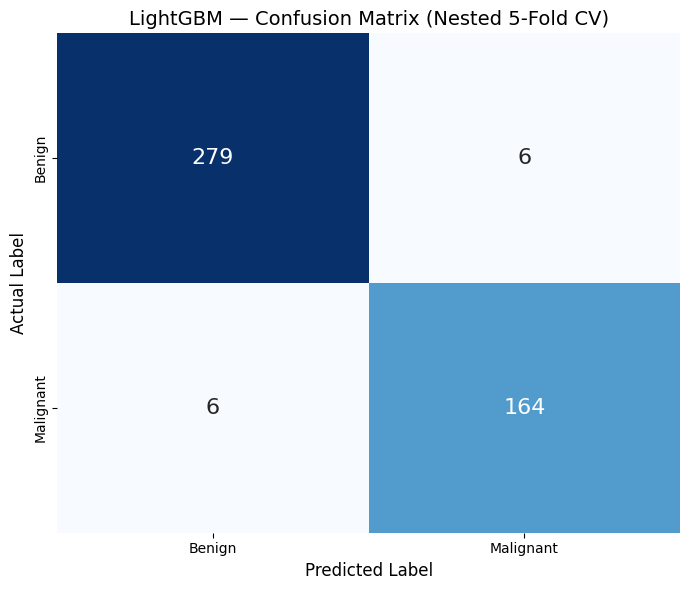


Saved: /kaggle/working/LightGBM_Confusion_Matrix_OOF.png


In [58]:

# ============================================================
# LIGHTGBM — ONE COMBINED CONFUSION MATRIX
# NESTED 5-FOLD CROSS-VALIDATION
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# 1. RECREATE THE SAME OUTER-FOLD SPLITS
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = list(outer_cv.split(X_train, y_train))

# ------------------------------------------------------------
# 2. CHECK FITTED OUTER-FOLD MODELS
# ------------------------------------------------------------

if len(lgbm_searches) != 5:
    raise ValueError(
        f"Expected 5 fitted LightGBM models, found "
        f"{len(lgbm_searches)}. "
        "Run the LightGBM nested CV code first."
    )

if set(lgbm_searches.keys()) != {1, 2, 3, 4, 5}:
    raise ValueError(
        "lgbm_searches must contain outer folds 1, 2, 3, 4, and 5."
    )

# ------------------------------------------------------------
# 3. COLLECT OUTER-FOLD PREDICTIONS
# ------------------------------------------------------------

y_true_all = []
y_pred_all = []

for fold, search in lgbm_searches.items():

    # Get this fold's validation data
    _, val_idx = splits[fold - 1]

    X_outer_val = X_train.iloc[val_idx]
    y_outer_val = y_train.iloc[val_idx]

    # Best model selected using inner CV
    best_model = search.best_estimator_

    # Predict outer validation samples
    y_pred = best_model.predict(X_outer_val)

    y_true_all.extend(
        np.asarray(y_outer_val).ravel()
    )

    y_pred_all.extend(
        np.asarray(y_pred).ravel()
    )

# ------------------------------------------------------------
# 4. COMBINED OUT-OF-FOLD CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_true_all,
    y_pred_all,
    labels=[0, 1]
)

print("Combined out-of-fold confusion matrix:")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nConfusion Matrix Values:")
print("True Negative (TN):", tn)
print("False Positive (FP):", fp)
print("False Negative (FN):", fn)
print("True Positive (TP):", tp)

# ------------------------------------------------------------
# 5. PLOT CONFUSION MATRIX
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
    annot_kws={"size": 16}
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.title(
    "LightGBM — Confusion Matrix (Nested 5-Fold CV)",
    fontsize=14
)

plt.tight_layout()

# ------------------------------------------------------------
# 6. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    "/kaggle/working/LightGBM_Confusion_Matrix_OOF.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved: "
    "/kaggle/working/LightGBM_Confusion_Matrix_OOF.png"
)


Number of selected features: 28
Selected features: ['perimeter_worst', 'radius_worst', 'area_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'perimeter_mean', 'concavity_worst', 'area_se', 'area_mean', 'radius_mean', 'radius_se', 'perimeter_se', 'compactness_worst', 'compactness_mean', 'concavity_se', 'texture_worst', 'texture_mean', 'concave points_se', 'smoothness_worst', 'compactness_se', 'symmetry_worst', 'smoothness_mean', 'fractal_dimension_worst', 'symmetry_mean', 'fractal_dimension_se', 'texture_se', 'fractal_dimension_mean']

LightGBM — SHAP Feature Importance
                Feature  Mean |SHAP Value|
             area_worst           2.245689
    concave points_mean           1.927814
          texture_worst           1.653832
        perimeter_worst           1.394261
   concave points_worst           1.259138
           radius_worst           1.192618
           texture_mean           1.133836
                area_se           0.686449
        conc

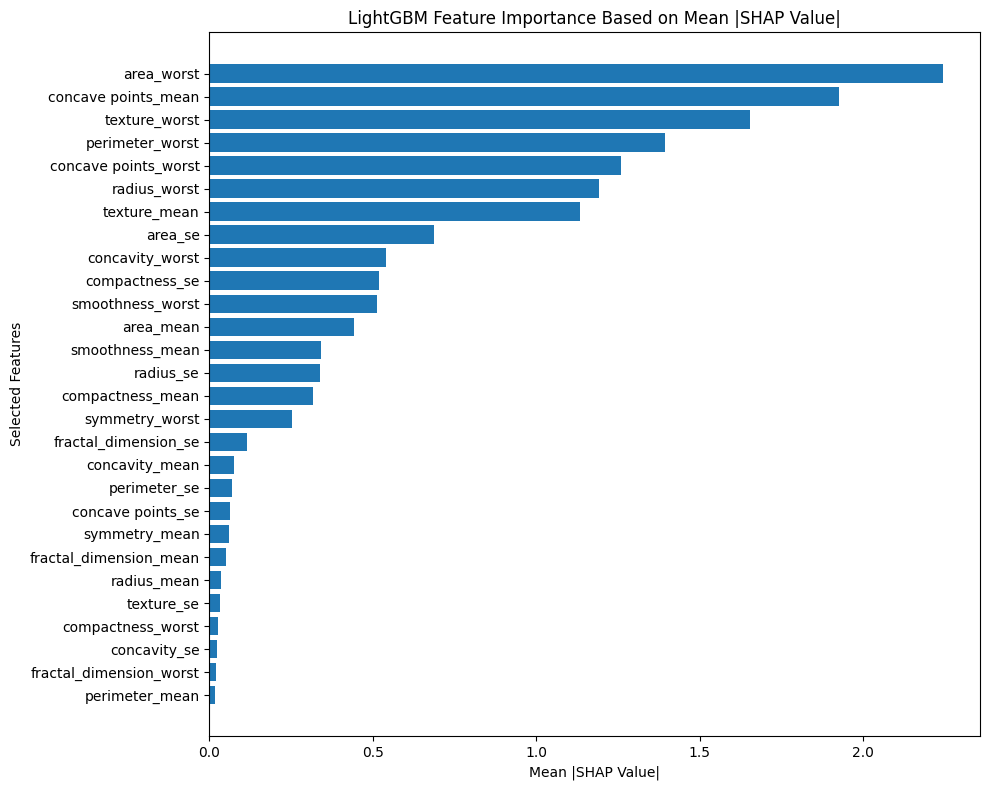


Saved: /kaggle/working/LightGBM_Mean_SHAP_Importance.png


In [60]:

# ============================================================
# MEAN |SHAP VALUE| PLOT — LIGHTGBM
# SELECTED FEATURES FROM OUTER FOLD 1
# ============================================================

import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold

# ------------------------------------------------------------
# 1. CHOOSE OUTER FOLD 1
# ------------------------------------------------------------

fold = 1

# Get fitted LightGBM model and selector
best_model = lgbm_searches[fold].best_estimator_

selector = best_model.named_steps["selector"]

# Get selected feature names
selected_features = list(selector.selected_features_)

print("Number of selected features:", len(selected_features))
print("Selected features:", selected_features)

# ------------------------------------------------------------
# 2. RECREATE OUTER-FOLD SPLITS
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

splits = list(outer_cv.split(X_train, y_train))

_, val_idx = splits[fold - 1]

X_outer_val = X_train.iloc[val_idx].copy()

# ------------------------------------------------------------
# 3. APPLY FITTED SCALER AND FEATURE SELECTOR
# ------------------------------------------------------------

X_scaled = best_model.named_steps["scaler"].transform(
    X_outer_val
)

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X_train.columns,
    index=X_outer_val.index
)

X_selected = selector.transform(X_scaled_df)

X_selected = pd.DataFrame(
    X_selected,
    columns=selected_features,
    index=X_outer_val.index
)

# ------------------------------------------------------------
# 4. EXPLAIN LIGHTGBM CLASSIFIER
# ------------------------------------------------------------

lgbm_model = best_model.named_steps["classifier"]

# TreeExplainer is suitable for LightGBM
explainer = shap.TreeExplainer(lgbm_model)

shap_values = explainer.shap_values(X_selected)

# ------------------------------------------------------------
# 5. HANDLE SHAP OUTPUT
# ------------------------------------------------------------

if isinstance(shap_values, list):

    # Binary classification: malignant class (class 1)
    shap_matrix = np.asarray(shap_values[1])

else:

    shap_matrix = np.asarray(shap_values)

    # Handle possible 3-dimensional output
    if shap_matrix.ndim == 3:

        if shap_matrix.shape[-1] == 2:
            shap_matrix = shap_matrix[:, :, 1]

        elif shap_matrix.shape[0] == 2:
            shap_matrix = shap_matrix[1, :, :]

# Ensure correct dimensions
if shap_matrix.shape != X_selected.shape:
    raise ValueError(
        f"Unexpected SHAP shape: {shap_matrix.shape}; "
        f"expected {X_selected.shape}"
    )

# ------------------------------------------------------------
# 6. CALCULATE MEAN ABSOLUTE SHAP VALUES
# ------------------------------------------------------------

mean_abs_shap = np.mean(
    np.abs(shap_matrix),
    axis=0
)

shap_importance = pd.DataFrame({
    "Feature": selected_features,
    "Mean |SHAP Value|": mean_abs_shap
}).sort_values(
    "Mean |SHAP Value|",
    ascending=False
)

print("\nLightGBM — SHAP Feature Importance")
print(shap_importance.to_string(index=False))

# ------------------------------------------------------------
# 7. PLOT MEAN |SHAP VALUE|
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

plt.barh(
    shap_importance["Feature"][::-1],
    shap_importance["Mean |SHAP Value|"][::-1]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Selected Features")

plt.title(
    "LightGBM Feature Importance Based on Mean |SHAP Value|"
)

plt.tight_layout()

# ------------------------------------------------------------
# 8. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    "/kaggle/working/LightGBM_Mean_SHAP_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved: "
    "/kaggle/working/LightGBM_Mean_SHAP_Importance.png"
)


Original SHAP shape: (91, 28)
X_selected shape: (91, 28)
Number of selected features: 28

Dimension validation successful.
Final SHAP shape: (91, 28)
Final feature shape: (91, 28)


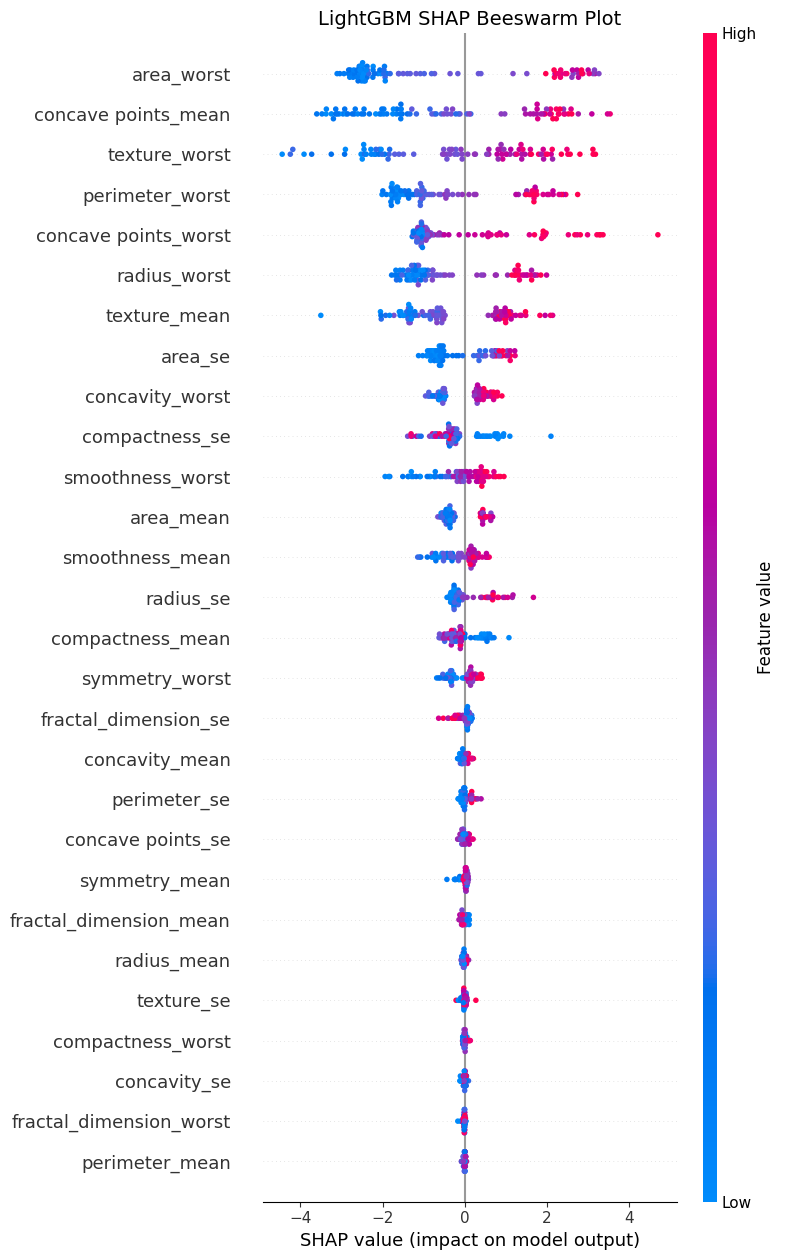


Saved as: /kaggle/working/LightGBM_SHAP_Beeswarm.png


In [61]:

# ============================================================
# SAVE LIGHTGBM SHAP BEESWARM PLOT — CORRECTED
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# ------------------------------------------------------------
# 1. CHECK FEATURE AND SHAP DIMENSIONS
# ------------------------------------------------------------

print("Original SHAP shape:", np.asarray(shap_matrix).shape)
print("X_selected shape:", X_selected.shape)
print("Number of selected features:", len(selected_features))

# ------------------------------------------------------------
# 2. EXTRACT CORRECT BINARY CLASS SHAP VALUES
# ------------------------------------------------------------

if isinstance(shap_matrix, list):

    # Binary classification: malignant class (class 1)
    shap_matrix = np.asarray(shap_matrix[1])

else:

    shap_matrix = np.asarray(shap_matrix)

    if shap_matrix.ndim == 3:

        if shap_matrix.shape[-1] == 2:
            shap_matrix = shap_matrix[:, :, 1]

        elif shap_matrix.shape[0] == 2:
            shap_matrix = shap_matrix[1, :, :]

# ------------------------------------------------------------
# 3. CONVERT FEATURES INTO DATAFRAME
# ------------------------------------------------------------

X_selected = pd.DataFrame(
    X_selected,
    columns=selected_features
)

# ------------------------------------------------------------
# 4. VALIDATE DIMENSIONS
# ------------------------------------------------------------

if shap_matrix.ndim != 2:
    raise ValueError(
        f"SHAP values must be 2-dimensional. "
        f"Current shape: {shap_matrix.shape}"
    )

if shap_matrix.shape[0] != X_selected.shape[0]:
    raise ValueError(
        "Mismatch in number of samples between SHAP values "
        "and selected features."
    )

if shap_matrix.shape[1] != X_selected.shape[1]:
    raise ValueError(
        "Mismatch in number of features between SHAP values "
        "and selected features."
    )

if shap_matrix.shape[1] != len(selected_features):
    raise ValueError(
        "Mismatch between SHAP columns and feature names."
    )

print("\nDimension validation successful.")
print("Final SHAP shape:", shap_matrix.shape)
print("Final feature shape:", X_selected.shape)

# ------------------------------------------------------------
# 5. SAVE LIGHTGBM SHAP BEESWARM PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_matrix,
    X_selected,
    feature_names=selected_features,
    plot_type="dot",
    max_display=len(selected_features),
    show=False
)

plt.title(
    "LightGBM SHAP Beeswarm Plot",
    fontsize=14
)

plt.tight_layout()

# ------------------------------------------------------------
# 6. SAVE FIGURE
# ------------------------------------------------------------

plt.savefig(
    "/kaggle/working/LightGBM_SHAP_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved as: "
    "/kaggle/working/LightGBM_SHAP_Beeswarm.png"
)


In [46]:

# ============================================================
# ADABOOST + N-mRMR + BORDERLINE-SMOTE
# NESTED 5-FOLD CROSS-VALIDATION
# Feature counts: 1 to 30
# Mean ± SD + 95% t-based CI
# ============================================================

import numpy as np
import pandas as pd
import io

from contextlib import redirect_stdout

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import AdaBoostClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score,
    confusion_matrix
)

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from scipy.stats import t


# ============================================================
# 1. VALIDATE INPUT DATA
# ============================================================

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

assert len(X_train) == len(y_train)
assert set(y_train.unique()) == {0, 1}

feature_names = list(X_train.columns)

if len(feature_names) != 30:
    raise ValueError(
        f"Expected 30 input features, but found {len(feature_names)}."
    )

print("Dataset shape:", X_train.shape)
print("Class distribution:")
print(y_train.value_counts())


# ============================================================
# 2. N-mRMR FEATURE SELECTION TRANSFORMER
# Requires existing:
# calculate_TIF_fold()
# neutrosophic_mrmr()
# ============================================================

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=1, feature_names=None):

        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        if not 1 <= self.n_features <= X_df.shape[1]:
            raise ValueError("Invalid feature count.")

        self.feature_names_in_ = list(X_df.columns)

        with redirect_stdout(io.StringIO()):

            T, I, F, _ = calculate_TIF_fold(X_df, y)

            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        self.selected_features_ = list(selected)
        self.selection_log_ = selection_log

        return self

    def transform(self, X):

        if isinstance(X, pd.DataFrame):
            X_df = X.copy()
        else:
            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:
            raise ValueError("Feature columns/order changed.")

        return X_df.loc[:, self.selected_features_].copy()


# ============================================================
# 3. ADABOOST PIPELINE
# ============================================================

adaboost_pipeline = Pipeline([

    ("scaler", StandardScaler()),

    ("selector", FoldNMRMRSelector(
        n_features=1,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42,
        k_neighbors=5,
        m_neighbors=10
    )),

    ("classifier", AdaBoostClassifier(
        random_state=42
    ))

])


# ============================================================
# 4. ADABOOST HYPERPARAMETER GRID
# ============================================================

param_grid = {

    # Feature selection
    "selector__n_features": list(range(1, 31)),

    # Number of weak learners
    "classifier__n_estimators": [50, 100],

    # Learning rate
    "classifier__learning_rate": [0.1]

}


# ============================================================
# 5. OUTER CROSS-VALIDATION
# ============================================================

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

adaboost_searches = {}
adaboost_results = []


# ============================================================
# 6. NESTED 5-FOLD CROSS-VALIDATION
# ============================================================

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 70)
    print(f"ADABOOST: OUTER FOLD {fold}/5")
    print("=" * 70)

    # --------------------------------------------------------
    # OUTER TRAINING AND VALIDATION DATA
    # --------------------------------------------------------

    X_fold_train = X_train.iloc[train_idx].copy()
    y_fold_train = y_train.iloc[train_idx].copy()

    X_val = X_train.iloc[val_idx].copy()
    y_val = y_train.iloc[val_idx].copy()

    # --------------------------------------------------------
    # INNER 5-FOLD CROSS-VALIDATION
    # --------------------------------------------------------

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    # --------------------------------------------------------
    # GRID SEARCH
    # --------------------------------------------------------

    search = GridSearchCV(

        estimator=adaboost_pipeline,

        param_grid=param_grid,

        scoring="roc_auc",

        cv=inner_cv,

        n_jobs=-1,

        refit=True,

        verbose=1,

        error_score="raise",

        return_train_score=True
    )

    # Fit using outer training data only
    search.fit(X_fold_train, y_fold_train)

    adaboost_searches[fold] = search

    # --------------------------------------------------------
    # BEST MODEL
    # --------------------------------------------------------

    model = search.best_estimator_

    selected_features = (
        model.named_steps["selector"].selected_features_
    )

    selected_count = len(selected_features)

    print("\nBest parameters:")
    print(search.best_params_)

    print("\nBest inner CV ROC-AUC:")
    print(round(search.best_score_, 4))

    print("\nSelected feature count:", selected_count)

    print("\nSelected features:")
    print(selected_features)

    # --------------------------------------------------------
    # OUTER VALIDATION PREDICTION
    # --------------------------------------------------------

    y_pred = model.predict(X_val)

    y_prob = model.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    # --------------------------------------------------------
    # PERFORMANCE METRICS
    # --------------------------------------------------------

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_val,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_val,
        y_pred
    )

    auc = roc_auc_score(
        y_val,
        y_prob
    )

    # --------------------------------------------------------
    # STORE OUTER-FOLD RESULTS
    # --------------------------------------------------------

    adaboost_results.append({

        "Fold": fold,

        "Classifier": "AdaBoost",

        "Number of Selected Features": selected_count,

        "Selected Features": ", ".join(selected_features),

        "Accuracy (%)": accuracy * 100,

        "Precision (%)": precision * 100,

        "Recall (%)": recall * 100,

        "Specificity (%)": specificity * 100,

        "F1-score (%)": f1 * 100,

        "Balanced accuracy (%)": balanced_acc * 100,

        "MCC": mcc,

        "ROC-AUC (%)": auc * 100,

        "Best parameters": str(search.best_params_)

    })

    # --------------------------------------------------------
    # DISPLAY FOLD RESULTS
    # --------------------------------------------------------

    print("\nOuter-fold performance:")

    print(f"Accuracy      : {accuracy * 100:.4f}%")
    print(f"Precision     : {precision * 100:.4f}%")
    print(f"Recall        : {recall * 100:.4f}%")
    print(f"Specificity   : {specificity * 100:.4f}%")
    print(f"F1-score      : {f1 * 100:.4f}%")
    print(f"Balanced Acc. : {balanced_acc * 100:.4f}%")
    print(f"MCC           : {mcc:.4f}")
    print(f"ROC-AUC       : {auc * 100:.4f}%")


# ============================================================
# 7. OUTER-FOLD RESULTS
# ============================================================

adaboost_results_df = pd.DataFrame(adaboost_results)

if len(adaboost_results_df) != 5:
    raise ValueError(
        f"Expected 5 outer-fold results, "
        f"but obtained {len(adaboost_results_df)}."
    )

print("\n" + "=" * 80)
print("ADABOOST: OUTER-FOLD RESULTS")
print("=" * 80)

display(adaboost_results_df.round(4))

adaboost_results_df.to_csv(
    "/kaggle/working/WBCD_AdaBoost_NmRMR_SMOTE_5Fold_Results.csv",
    index=False
)


# ============================================================
# 8. MEAN ± SD AND 95% t-BASED CONFIDENCE INTERVAL
# ============================================================

metrics = [

    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"

]

n = len(adaboost_results_df)

t_critical = t.ppf(
    0.975,
    df=n - 1
)

summary_rows = []

for metric in metrics:

    values = adaboost_results_df[metric].to_numpy(dtype=float)

    mean_value = np.mean(values)

    sd_value = np.std(
        values,
        ddof=1
    )

    se_value = sd_value / np.sqrt(n)

    ci_lower = mean_value - t_critical * se_value

    ci_upper = mean_value + t_critical * se_value

    if metric == "MCC":

        ci_lower = max(-1.0, ci_lower)
        ci_upper = min(1.0, ci_upper)

    else:

        ci_lower = max(0.0, ci_lower)
        ci_upper = min(100.0, ci_upper)

    summary_rows.append({

        "Classifier": "AdaBoost",

        "Metric": metric,

        "Mean": mean_value,

        "SD": sd_value,

        "95% CI Lower": ci_lower,

        "95% CI Upper": ci_upper,

        "Mean ± SD": (
            f"{mean_value:.4f} ± {sd_value:.4f}"
        ),

        "95% CI": (
            f"[{ci_lower:.4f}, {ci_upper:.4f}]"
        )

    })


adaboost_summary_df = pd.DataFrame(summary_rows)

print("\n" + "=" * 80)
print("ADABOOST: MEAN ± SD AND 95% CI")
print("=" * 80)

display(adaboost_summary_df.round(4))

adaboost_summary_df.to_csv(
    "/kaggle/working/WBCD_AdaBoost_NmRMR_SMOTE_Mean_SD_95CI.csv",
    index=False
)


# ============================================================
# 9. SELECTED FEATURES SUMMARY
# ============================================================

adaboost_selected_features_df = adaboost_results_df[

    [
        "Fold",
        "Number of Selected Features",
        "Selected Features"
    ]

].copy()

print("\nSelected features in each outer fold:")

display(adaboost_selected_features_df)

adaboost_selected_features_df.to_csv(
    "/kaggle/working/WBCD_AdaBoost_NmRMR_Selected_Features.csv",
    index=False
)


# ============================================================
# 10. COMPLETION
# ============================================================

print("\nAdaBoost nested CV completed.")

print("\nFiles saved:")

print(
    "/kaggle/working/WBCD_AdaBoost_NmRMR_SMOTE_5Fold_Results.csv"
)

print(
    "/kaggle/working/WBCD_AdaBoost_NmRMR_SMOTE_Mean_SD_95CI.csv"
)

print(
    "/kaggle/working/WBCD_AdaBoost_NmRMR_Selected_Features.csv"
)

print("\nNumber of outer folds:", len(adaboost_searches))


Dataset shape: (455, 30)
Class distribution:
0    285
1    170
Name: count, dtype: int64

ADABOOST: OUTER FOLD 1/5
Fitting 5 folds for each of 60 candidates, totalling 300 fits

Best parameters:
{'classifier__learning_rate': 0.1, 'classifier__n_estimators': 100, 'selector__n_features': 24}

Best inner CV ROC-AUC:
0.9887

Selected feature count: 24

Selected features:
['perimeter_worst', 'radius_worst', 'area_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'perimeter_mean', 'concavity_worst', 'area_se', 'area_mean', 'radius_mean', 'radius_se', 'compactness_worst', 'perimeter_se', 'compactness_mean', 'concavity_se', 'texture_worst', 'texture_mean', 'concave points_se', 'smoothness_worst', 'symmetry_worst', 'compactness_se', 'smoothness_mean', 'fractal_dimension_worst']

Outer-fold performance:
Accuracy      : 94.5055%
Precision     : 91.4286%
Recall        : 94.1176%
Specificity   : 94.7368%
F1-score      : 92.7536%
Balanced Acc. : 94.4272%
MCC           : 0.8835

,Fold,Classifier,Number of Selected Features,Selected Features,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%),Best parameters
0,1,AdaBoost,24,"perimeter_worst, radius_worst, area_worst, con...",94.5055,91.4286,94.1176,94.7368,92.7536,94.4272,0.8835,98.6068,"{'classifier__learning_rate': 0.1, 'classifier..."
1,2,AdaBoost,18,"perimeter_worst, radius_worst, area_worst, con...",95.6044,94.1176,94.1176,96.4912,94.1176,95.3044,0.9061,99.2260,"{'classifier__learning_rate': 0.1, 'classifier..."
2,3,AdaBoost,20,"perimeter_worst, radius_worst, area_worst, con...",94.5055,91.4286,94.1176,94.7368,92.7536,94.4272,0.8835,98.6068,"{'classifier__learning_rate': 0.1, 'classifier..."
3,4,AdaBoost,30,"perimeter_worst, concave points_worst, radius_...",94.5055,89.1892,97.0588,92.9825,92.9577,95.0206,0.8868,97.5232,"{'classifier__learning_rate': 0.1, 'classifier..."
4,5,AdaBoost,19,"perimeter_worst, concave points_worst, radius_...",96.7033,94.2857,97.0588,96.4912,95.6522,96.7750,0.9302,99.3292,"{'classifier__learning_rate': 0.1, 'classifier..."



ADABOOST: MEAN ± SD AND 95% CI


,Classifier,Metric,Mean,SD,95% CI Lower,95% CI Upper,Mean ± SD,95% CI
0,AdaBoost,Accuracy (%),95.1648,0.9829,93.9444,96.3853,95.1648 ± 0.9829,"[93.9444, 96.3853]"
1,AdaBoost,Precision (%),92.0899,2.1344,89.4398,94.7401,92.0899 ± 2.1344,"[89.4398, 94.7401]"
2,AdaBoost,Recall (%),95.2941,1.6109,93.2939,97.2944,95.2941 ± 1.6109,"[93.2939, 97.2944]"
3,AdaBoost,Specificity (%),95.0877,1.4678,93.2652,96.9103,95.0877 ± 1.4678,"[93.2652, 96.9103]"
4,AdaBoost,F1-score (%),93.6470,1.2563,92.0870,95.2069,93.6470 ± 1.2563,"[92.0870, 95.2069]"
5,AdaBoost,Balanced accuracy (%),95.1909,0.9641,93.9939,96.3880,95.1909 ± 0.9641,"[93.9939, 96.3880]"
6,AdaBoost,MCC,0.8980,0.0203,0.8728,0.9232,0.8980 ± 0.0203,"[0.8728, 0.9232]"
7,AdaBoost,ROC-AUC (%),98.6584,0.7187,97.7660,99.5508,98.6584 ± 0.7187,"[97.7660, 99.5508]"



Selected features in each outer fold:


,Fold,Number of Selected Features,Selected Features
0,1,24,"perimeter_worst, radius_worst, area_worst, con..."
1,2,18,"perimeter_worst, radius_worst, area_worst, con..."
2,3,20,"perimeter_worst, radius_worst, area_worst, con..."
3,4,30,"perimeter_worst, concave points_worst, radius_..."
4,5,19,"perimeter_worst, concave points_worst, radius_..."



AdaBoost nested CV completed.

Files saved:
/kaggle/working/WBCD_AdaBoost_NmRMR_SMOTE_5Fold_Results.csv
/kaggle/working/WBCD_AdaBoost_NmRMR_SMOTE_Mean_SD_95CI.csv
/kaggle/working/WBCD_AdaBoost_NmRMR_Selected_Features.csv

Number of outer folds: 5


In [47]:
# ============================================================
# ADABOOST — NESTED 5-FOLD CV SUMMARY TABLE
# ALL METRICS: MEAN ± SD + APPROXIMATE 95% CI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score
)
from scipy.stats import t

# ------------------------------------------------------------
# CHECK THAT THE FIVE FOLD MODELS ARE AVAILABLE
# ------------------------------------------------------------
if len(adaboost_searches) != 5:
    raise ValueError(
        f"Expected 5 fitted AdaBoost models, found "
        f"{len(adaboost_searches)}. Run the nested CV code first."
    )

# Recreate the same outer splits used during model evaluation
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

all_fold_results = []

# ------------------------------------------------------------
# CALCULATE METRICS ON EACH OUTER VALIDATION FOLD
# ------------------------------------------------------------
for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):

    X_outer_val = X_train.iloc[val_idx].copy()
    y_outer_val = y_train.iloc[val_idx].copy()

    best_model = adaboost_searches[fold].best_estimator_

    y_pred = np.asarray(
        best_model.predict(X_outer_val)
    ).ravel()

    # Probability of positive class (label 1)
    if not hasattr(best_model, "predict_proba"):
        raise AttributeError(
            "The fitted AdaBoost model does not support predict_proba."
        )

    probabilities = best_model.predict_proba(X_outer_val)
    classes = np.asarray(best_model.classes_)
    positive_idx = np.where(classes == 1)[0]

    if len(positive_idx) != 1:
        raise ValueError(
            f"Positive class 1 not found uniquely: {classes}"
        )

    y_prob = probabilities[:, positive_idx[0]]

    # Confusion matrix: 0 = negative, 1 = positive
    tn, fp, fn, tp = confusion_matrix(
        y_outer_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        100 * tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    fold_result = {
        "Classifier": "AdaBoost",
        "Outer Fold": fold,
        "Accuracy (%)": 100 * accuracy_score(
            y_outer_val, y_pred
        ),
        "Precision (%)": 100 * precision_score(
            y_outer_val, y_pred,
            pos_label=1, zero_division=0
        ),
        "Recall (%)": 100 * recall_score(
            y_outer_val, y_pred,
            pos_label=1, zero_division=0
        ),
        "Specificity (%)": specificity,
        "F1-score (%)": 100 * f1_score(
            y_outer_val, y_pred,
            pos_label=1, zero_division=0
        ),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(
            y_outer_val, y_pred
        ),
        "MCC": matthews_corrcoef(
            y_outer_val, y_pred
        ),
        "ROC-AUC (%)": 100 * roc_auc_score(
            y_outer_val, y_prob
        )
    }

    all_fold_results.append(fold_result)

# ------------------------------------------------------------
# OUTER-FOLD METRICS TABLE
# ------------------------------------------------------------
adaboost_results_df = pd.DataFrame(all_fold_results)

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

# ------------------------------------------------------------
# MEAN, SAMPLE SD, AND APPROXIMATE 95% t-CONFIDENCE INTERVAL
# ------------------------------------------------------------
summary_rows = []

for metric in metric_columns:

    values = pd.to_numeric(
        adaboost_results_df[metric],
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        mean_value = sd_value = ci_lower = ci_upper = np.nan
    else:
        mean_value = np.mean(values)
        sd_value = np.std(values, ddof=1) if n > 1 else np.nan

        if n > 1:
            se = sd_value / np.sqrt(n)
            t_critical = t.ppf(0.975, df=n - 1)

            ci_lower = mean_value - t_critical * se
            ci_upper = mean_value + t_critical * se

            # Respect each metric's theoretical bounds
            if metric == "MCC":
                ci_lower = max(-1.0, ci_lower)
                ci_upper = min(1.0, ci_upper)
            else:
                ci_lower = max(0.0, ci_lower)
                ci_upper = min(100.0, ci_upper)
        else:
            ci_lower = ci_upper = np.nan

    summary_rows.append({
        "Metric": metric,
        "N folds": n,
        "Mean": mean_value,
        "SD": sd_value,
        "Mean ± SD": (
            f"{mean_value:.2f} ± {sd_value:.2f}"
            if np.isfinite(sd_value)
            else f"{mean_value:.2f} ± NA"
        ),
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "95% CI": (
            f"[{ci_lower:.2f}, {ci_upper:.2f}]"
            if np.isfinite(ci_lower) and np.isfinite(ci_upper)
            else "NA"
        )
    })

summary_table = pd.DataFrame(summary_rows).set_index("Metric")

# ------------------------------------------------------------
# DISPLAY SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("ADABOOST — NESTED 5-FOLD CV SUMMARY: MEAN ± SD")
print("=" * 70)
display(summary_table[["Mean ± SD"]])

print("\nADABOOST — APPROXIMATE 95% CONFIDENCE INTERVALS")
display(summary_table[[
    "Mean", "SD", "95% CI Lower", "95% CI Upper"
]])

print("\nOUTER-FOLD METRICS")
display(adaboost_results_df)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------
fold_path = (
    "/kaggle/working/AdaBoost_NestedCV_OuterFold_Metrics.csv"
)
summary_path = (
    "/kaggle/working/AdaBoost_NestedCV_Summary_With_CI.csv"
)

adaboost_results_df.to_csv(fold_path, index=False)
summary_table.to_csv(summary_path)

print("\nSaved files:")
print(fold_path)
print(summary_path)



ADABOOST — NESTED 5-FOLD CV SUMMARY: MEAN ± SD


,Mean ± SD
Metric,
Accuracy (%),95.16 ± 0.98
Precision (%),92.09 ± 2.13
Recall (%),95.29 ± 1.61
Specificity (%),95.09 ± 1.47
F1-score (%),93.65 ± 1.26
Balanced accuracy (%),95.19 ± 0.96
MCC,0.90 ± 0.02
ROC-AUC (%),98.66 ± 0.72



ADABOOST — APPROXIMATE 95% CONFIDENCE INTERVALS


,Mean,SD,95% CI Lower,95% CI Upper
Metric,,,,
Accuracy (%),95.164835,0.982887,93.944420,96.385251
Precision (%),92.089939,2.134373,89.439765,94.740113
Recall (%),95.294118,1.610949,93.293861,97.294375
Specificity (%),95.087719,1.467825,93.265174,96.910264
F1-score (%),93.646963,1.256339,92.087012,95.206913
Balanced accuracy (%),95.190918,0.964063,93.993876,96.387961
MCC,0.898040,0.020299,0.872836,0.923245
ROC-AUC (%),98.658411,0.718699,97.766028,99.550794



OUTER-FOLD METRICS


,Classifier,Outer Fold,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%)
0,AdaBoost,1,94.505495,91.428571,94.117647,94.736842,92.753623,94.427245,0.883544,98.606811
1,AdaBoost,2,95.604396,94.117647,94.117647,96.491228,94.117647,95.304438,0.906089,99.226006
2,AdaBoost,3,94.505495,91.428571,94.117647,94.736842,92.753623,94.427245,0.883544,98.606811
3,AdaBoost,4,94.505495,89.189189,97.058824,92.982456,92.957746,95.020640,0.886790,97.523220
4,AdaBoost,5,96.703297,94.285714,97.058824,96.491228,95.652174,96.775026,0.930235,99.329205



Saved files:
/kaggle/working/AdaBoost_NestedCV_OuterFold_Metrics.csv
/kaggle/working/AdaBoost_NestedCV_Summary_With_CI.csv


In [48]:
# ============================================================
# XGBOOST + N-mRMR + BORDERLINE-SMOTE
# NESTED 5-FOLD CROSS-VALIDATION
# FEATURE SELECTION: 1 TO 30 FEATURES
# ============================================================

import os
import io
import warnings
import numpy as np
import pandas as pd

from contextlib import redirect_stdout

from xgboost import XGBClassifier

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score
)

from scipy.stats import t
from IPython.display import display

warnings.filterwarnings("ignore")


# ------------------------------------------------------------
# 1. CHECK INPUT DATA AND REQUIRED FUNCTIONS
# ------------------------------------------------------------

if "X_train" not in globals() or "y_train" not in globals():
    raise ValueError("Please define X_train and y_train first.")

if "calculate_TIF_fold" not in globals():
    raise ValueError("Please define calculate_TIF_fold() first.")

if "neutrosophic_mrmr" not in globals():
    raise ValueError("Please define neutrosophic_mrmr() first.")


X_data = X_train.copy()
y_data = np.asarray(y_train).ravel()

if len(X_data) != len(y_data):
    raise ValueError("X_train and y_train have different sample counts.")

if X_data.shape[1] != 30:
    raise ValueError("Expected exactly 30 input features.")

if set(np.unique(y_data)) != {0, 1}:
    raise ValueError("Expected labels 0 and 1.")

# Preserve the original feature names.
if isinstance(X_data, pd.DataFrame):

    feature_names = list(X_data.columns)

else:

    feature_names = [
        f"Feature_{i+1}" for i in range(X_data.shape[1])
    ]

if len(feature_names) != 30:
    raise ValueError("Exactly 30 feature names are required.")

if len(set(feature_names)) != len(feature_names):
    raise ValueError("Feature names must be unique.")


print("Training data shape:", X_data.shape)

print(
    "Training labels:",
    pd.Series(y_data).value_counts().sort_index().to_dict()
)

print("Number of original features:", len(feature_names))


# ------------------------------------------------------------
# 2. CORRECTED FOLD N-mRMR SELECTOR
# ------------------------------------------------------------

class FoldNMRMRSelector(BaseEstimator, TransformerMixin):

    def __init__(self, n_features=1, feature_names=None):

        self.n_features = n_features
        self.feature_names = feature_names

    def fit(self, X, y):

        # Convert input into a DataFrame.
        if isinstance(X, pd.DataFrame):

            X_df = X.copy()

        else:

            if self.feature_names is None:
                raise ValueError(
                    "feature_names must be supplied when "
                    "the selector receives a NumPy array."
                )

            X_df = pd.DataFrame(
                np.asarray(X),
                columns=list(self.feature_names)
            )

        # Check requested feature count.
        if not 1 <= self.n_features <= X_df.shape[1]:

            raise ValueError(
                f"n_features must be between 1 and {X_df.shape[1]}."
            )

        self.feature_names_in_ = list(X_df.columns)

        # Calculate neutrosophic T, I and F values.
        with redirect_stdout(io.StringIO()):

            T, I, F, _ = calculate_TIF_fold(X_df, y)

            selected, selection_log = neutrosophic_mrmr(
                X_df,
                y,
                T,
                I,
                F,
                T_select=self.n_features
            )

        if selected is None:
            raise ValueError(
                "neutrosophic_mrmr() returned None. "
                "Check the feature-selection function."
            )

        self.selected_features_ = list(selected)

        if len(self.selected_features_) != self.n_features:
            raise ValueError(
                "The number of selected features does not match "
                "the requested n_features."
            )

        self.selection_log_ = selection_log

        return self

    def transform(self, X):

        if isinstance(X, pd.DataFrame):

            X_df = X.copy()

        else:

            X_df = pd.DataFrame(
                np.asarray(X),
                columns=self.feature_names_in_
            )

        if list(X_df.columns) != self.feature_names_in_:

            raise ValueError(
                "Feature columns or their order have changed."
            )

        return X_df.loc[:, self.selected_features_].copy()


# ------------------------------------------------------------
# 3. OUTER 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ------------------------------------------------------------
# 4. XGBOOST PIPELINE
# ------------------------------------------------------------

xgb_pipeline = Pipeline([

    ("scaler", StandardScaler()),

    # IMPORTANT: Pass original feature names.
    ("selector", FoldNMRMRSelector(
        n_features=30,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42,
        k_neighbors=5,
        m_neighbors=10
    )),

    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,
        verbosity=0
    ))

])


# ------------------------------------------------------------
# 5. HYPERPARAMETER GRID
# FEATURE SELECTION: 1, 2, 3, ..., 30
# ------------------------------------------------------------

param_grid = {

    # Evaluate every feature count
    "selector__n_features": list(range(1, 31)),

    # Fixed XGBoost parameters
    "xgb__n_estimators": [100],

    "xgb__max_depth": [3],

    "xgb__learning_rate": [0.05],

    "xgb__subsample": [0.8],

    "xgb__colsample_bytree": [0.8],

    "xgb__min_child_weight": [1]

}

n_combinations = (

    len(param_grid["selector__n_features"])
    * len(param_grid["xgb__n_estimators"])
    * len(param_grid["xgb__max_depth"])
    * len(param_grid["xgb__learning_rate"])
    * len(param_grid["xgb__subsample"])
    * len(param_grid["xgb__colsample_bytree"])
    * len(param_grid["xgb__min_child_weight"])

)

print("\nTotal hyperparameter combinations:", n_combinations)

print("Feature counts evaluated: 1 to 30")

print(
    "Total inner-CV candidate fits:",
    n_combinations * 5 * 5
)


# ------------------------------------------------------------
# 6. NESTED 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

xgb_searches = {}

results = []

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_data, y_data),
    start=1
):

    print("\n" + "=" * 65)
    print(f"XGBOOST — OUTER FOLD {fold}/5")
    print("=" * 65)

    # Outer training and validation partitions.
    if hasattr(X_data, "iloc"):

        X_outer_train = X_data.iloc[train_idx].copy()
        X_outer_val = X_data.iloc[val_idx].copy()

    else:

        X_outer_train = X_data[train_idx]
        X_outer_val = X_data[val_idx]

    y_outer_train = y_data[train_idx]
    y_outer_val = y_data[val_idx]

    # Inner 5-fold CV.
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    # Grid search.
    search = GridSearchCV(
        estimator=xgb_pipeline,
        param_grid=param_grid,
        scoring="roc_auc",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
        verbose=1,
        error_score="raise"
    )

    # Hyperparameter tuning on outer training data only.
    search.fit(
        X_outer_train,
        y_outer_train
    )

    xgb_searches[fold] = search

    # Best fitted pipeline.
    best_model = search.best_estimator_

    # Outer validation predictions.
    y_pred = np.asarray(
        best_model.predict(X_outer_val)
    ).ravel()

    y_prob = best_model.predict_proba(X_outer_val)[:, 1]

    # Confusion matrix.
    tn, fp, fn, tp = confusion_matrix(
        y_outer_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp) * 100
        if (tn + fp) > 0 else np.nan
    )

    # Selected feature count.
    selected_feature_count = search.best_params_[
        "selector__n_features"
    ]

    # Actual selected feature names.
    selected_feature_names = (
        best_model.named_steps["selector"].selected_features_
    )

    # Fold-wise metrics.
    row = {

        "Classifier": "XGBoost",

        "Outer Fold": fold,

        "Selected Features": selected_feature_count,

        "Selected Feature Names": ", ".join(
            map(str, selected_feature_names)
        ),

        "Accuracy (%)": accuracy_score(
            y_outer_val,
            y_pred
        ) * 100,

        "Precision (%)": precision_score(
            y_outer_val,
            y_pred,
            pos_label=1,
            zero_division=0
        ) * 100,

        "Recall (%)": recall_score(
            y_outer_val,
            y_pred,
            pos_label=1,
            zero_division=0
        ) * 100,

        "Specificity (%)": specificity,

        "F1-score (%)": f1_score(
            y_outer_val,
            y_pred,
            pos_label=1,
            zero_division=0
        ) * 100,

        "Balanced accuracy (%)": balanced_accuracy_score(
            y_outer_val,
            y_pred
        ) * 100,

        "MCC": matthews_corrcoef(
            y_outer_val,
            y_pred
        ),

        "ROC-AUC (%)": roc_auc_score(
            y_outer_val,
            y_prob
        ) * 100,

        "Best inner CV ROC-AUC (%)": search.best_score_ * 100,

        "Best parameters": str(search.best_params_)

    }

    results.append(row)

    print("\nBest parameters:", search.best_params_)

    print("Selected features:", selected_feature_count)

    print("Selected feature names:", selected_feature_names)

    print(
        f"Inner CV ROC-AUC: "
        f"{search.best_score_ * 100:.2f}%"
    )

    print(
        f"Outer validation accuracy: "
        f"{row['Accuracy (%)']:.2f}%"
    )

    print(
        f"Outer validation F1-score: "
        f"{row['F1-score (%)']:.2f}%"
    )

    print(
        f"Outer validation ROC-AUC: "
        f"{row['ROC-AUC (%)']:.2f}%"
    )


# ------------------------------------------------------------
# 7. OUTER-FOLD RESULTS
# ------------------------------------------------------------

xgb_results_df = pd.DataFrame(results)

metric_columns = [

    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"

]

print("\nXGBOOST — OUTER-FOLD RESULTS")

display(xgb_results_df.round(4))


# ------------------------------------------------------------
# 8. MEAN, SD AND APPROXIMATE 95% t-CONFIDENCE INTERVAL
# ------------------------------------------------------------

summary_rows = []

for metric in metric_columns:

    values = xgb_results_df[metric].dropna().to_numpy(
        dtype=float
    )

    n = len(values)

    mean_value = np.mean(values) if n else np.nan

    sd_value = (
        np.std(values, ddof=1)
        if n > 1 else np.nan
    )

    if n > 1:

        standard_error = sd_value / np.sqrt(n)

        critical_value = t.ppf(
            0.975,
            df=n - 1
        )

        ci_lower = (
            mean_value - critical_value * standard_error
        )

        ci_upper = (
            mean_value + critical_value * standard_error
        )

        if metric == "MCC":

            ci_lower = max(-1.0, ci_lower)
            ci_upper = min(1.0, ci_upper)

        else:

            ci_lower = max(0.0, ci_lower)
            ci_upper = min(100.0, ci_upper)

    else:

        ci_lower = np.nan
        ci_upper = np.nan

    summary_rows.append({

        "Metric": metric,

        "N folds": n,

        "Mean": mean_value,

        "SD": sd_value,

        "Mean ± SD": (
            f"{mean_value:.2f} ± {sd_value:.2f}"
            if np.isfinite(sd_value) else "NA"
        ),

        "95% CI Lower": ci_lower,

        "95% CI Upper": ci_upper

    })


xgb_summary_df = pd.DataFrame(
    summary_rows
).set_index("Metric")


print("\nXGBOOST — MEAN ± SD")

display(
    xgb_summary_df[["N folds", "Mean ± SD"]]
)


print("\nXGBOOST — APPROXIMATE 95% CONFIDENCE INTERVAL")

display(
    xgb_summary_df[
        ["Mean", "SD", "95% CI Lower", "95% CI Upper"]
    ].round(4)
)


# ------------------------------------------------------------
# 9. SELECTED FEATURE COUNT SUMMARY
# ------------------------------------------------------------

print("\nSELECTED FEATURE COUNTS ACROSS OUTER FOLDS")

display(
    xgb_results_df[
        ["Outer Fold", "Selected Features"]
    ]
)


print("\nSELECTED FEATURES ACROSS OUTER FOLDS")

display(
    xgb_results_df[
        ["Outer Fold", "Selected Features", "Selected Feature Names"]
    ]
)


# ------------------------------------------------------------
# 10. SAVE RESULTS
# ------------------------------------------------------------

output_dir = "/kaggle/working"

os.makedirs(output_dir, exist_ok=True)

fold_path = os.path.join(
    output_dir,
    "XGBoost_NMRMR_BorderlineSMOTE_OuterFold_Metrics.csv"
)

summary_path = os.path.join(
    output_dir,
    "XGBoost_NMRMR_Mean_SD_95CI.csv"
)

params_path = os.path.join(
    output_dir,
    "XGBoost_NMRMR_BestParameters.csv"
)


xgb_results_df.to_csv(
    fold_path,
    index=False
)

xgb_summary_df.to_csv(
    summary_path
)

xgb_results_df[
    [
        "Outer Fold",
        "Selected Features",
        "Selected Feature Names",
        "Best inner CV ROC-AUC (%)",
        "Best parameters"
    ]
].to_csv(
    params_path,
    index=False
)


print("\nSaved files:")

print(fold_path)

print(summary_path)

print(params_path)


# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\nCompleted nested 5-fold XGBoost evaluation.")

print(
    "Mean outer-fold accuracy:",
    f"{xgb_results_df['Accuracy (%)'].mean():.2f}%"
)

print(
    "Mean selected feature count:",
    f"{xgb_results_df['Selected Features'].mean():.2f}"
)

Training data shape: (455, 30)
Training labels: {0: 285, 1: 170}
Number of original features: 30

Total hyperparameter combinations: 30
Feature counts evaluated: 1 to 30
Total inner-CV candidate fits: 750

XGBOOST — OUTER FOLD 1/5
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best parameters: {'selector__n_features': 26, 'xgb__colsample_bytree': 0.8, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 3, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 100, 'xgb__subsample': 0.8}
Selected features: 26
Selected feature names: ['perimeter_worst', 'radius_worst', 'area_worst', 'concave points_mean', 'concave points_worst', 'concavity_mean', 'perimeter_mean', 'concavity_worst', 'area_se', 'area_mean', 'radius_mean', 'radius_se', 'perimeter_se', 'compactness_worst', 'compactness_mean', 'concavity_se', 'texture_worst', 'texture_mean', 'concave points_se', 'smoothness_worst', 'symmetry_worst', 'compactness_se', 'smoothness_mean', 'fractal_dimension_worst', 'symmetry_mean', 'fractal

,Classifier,Outer Fold,Selected Features,Selected Feature Names,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%),Best inner CV ROC-AUC (%),Best parameters
0,XGBoost,1,26,"perimeter_worst, radius_worst, area_worst, con...",96.7033,96.9697,94.1176,98.2456,95.5224,96.1816,0.9294,99.4324,99.4508,"{'selector__n_features': 26, 'xgb__colsample_b..."
1,XGBoost,2,23,"perimeter_worst, radius_worst, area_worst, con...",96.7033,94.2857,97.0588,96.4912,95.6522,96.7750,0.9302,99.1744,99.2785,"{'selector__n_features': 23, 'xgb__colsample_b..."
2,XGBoost,3,29,"perimeter_worst, radius_worst, area_worst, con...",96.7033,96.9697,94.1176,98.2456,95.5224,96.1816,0.9294,99.3292,98.9460,"{'selector__n_features': 29, 'xgb__colsample_b..."
3,XGBoost,4,18,"perimeter_worst, concave points_worst, radius_...",93.4066,86.8421,97.0588,91.2281,91.6667,94.1434,0.8661,98.6068,99.1295,"{'selector__n_features': 18, 'xgb__colsample_b..."
4,XGBoost,5,26,"perimeter_worst, concave points_worst, radius_...",97.8022,97.0588,97.0588,98.2456,97.0588,97.6522,0.9530,99.6388,98.4958,"{'selector__n_features': 26, 'xgb__colsample_b..."



XGBOOST — MEAN ± SD


,N folds,Mean ± SD
Metric,,
Accuracy (%),5,96.26 ± 1.67
Precision (%),5,94.43 ± 4.40
Recall (%),5,95.88 ± 1.61
Specificity (%),5,96.49 ± 3.04
F1-score (%),5,95.08 ± 2.02
Balanced accuracy (%),5,96.19 ± 1.29
MCC,5,0.92 ± 0.03
ROC-AUC (%),5,99.24 ± 0.39



XGBOOST — APPROXIMATE 95% CONFIDENCE INTERVAL


,Mean,SD,95% CI Lower,95% CI Upper
Metric,,,,
Accuracy (%),96.2637,1.6666,94.1944,98.3331
Precision (%),94.4252,4.3991,88.9630,99.8874
Recall (%),95.8824,1.6109,93.8821,97.8826
Specificity (%),96.4912,3.0387,92.7182,100.0000
F1-score (%),95.0845,2.0178,92.5791,97.5899
Balanced accuracy (%),96.1868,1.2912,94.5836,97.7900
MCC,0.9216,0.0327,0.8811,0.9622
ROC-AUC (%),99.2363,0.3903,98.7518,99.7209



SELECTED FEATURE COUNTS ACROSS OUTER FOLDS


,Outer Fold,Selected Features
0,1,26
1,2,23
2,3,29
3,4,18
4,5,26



SELECTED FEATURES ACROSS OUTER FOLDS


,Outer Fold,Selected Features,Selected Feature Names
0,1,26,"perimeter_worst, radius_worst, area_worst, con..."
1,2,23,"perimeter_worst, radius_worst, area_worst, con..."
2,3,29,"perimeter_worst, radius_worst, area_worst, con..."
3,4,18,"perimeter_worst, concave points_worst, radius_..."
4,5,26,"perimeter_worst, concave points_worst, radius_..."



Saved files:
/kaggle/working/XGBoost_NMRMR_BorderlineSMOTE_OuterFold_Metrics.csv
/kaggle/working/XGBoost_NMRMR_Mean_SD_95CI.csv
/kaggle/working/XGBoost_NMRMR_BestParameters.csv

Completed nested 5-fold XGBoost evaluation.
Mean outer-fold accuracy: 96.26%
Mean selected feature count: 24.40


In [49]:

# ============================================================
# WBCD | KNN + N-mRMR — NESTED 5-FOLD CROSS-VALIDATION
# Feature selection: 1, 2, 3, ..., 30
# OUTER-FOLD ACCURACY + MEAN ± SD + APPROXIMATE 95% CI
# ============================================================

import numpy as np
import pandas as pd

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import BorderlineSMOTE

from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

from scipy.stats import t

# ------------------------------------------------------------
# 1. VALIDATE INPUT DATA
# ------------------------------------------------------------

if not isinstance(X_train, pd.DataFrame):
    X_train = pd.DataFrame(X_train)

if isinstance(y_train, pd.DataFrame):
    y_train = y_train.squeeze()

y_train = pd.Series(
    np.asarray(y_train).ravel(),
    index=X_train.index
)

feature_names = list(X_train.columns)

assert X_train.shape[1] == 30
assert len(X_train) == len(y_train)

# ------------------------------------------------------------
# 2. OUTER CROSS-VALIDATION
# ------------------------------------------------------------

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# ------------------------------------------------------------
# 3. KNN PIPELINE
# ------------------------------------------------------------

knn_pipeline = Pipeline([

    ("scaler", StandardScaler()),

    ("selector", FoldNMRMRSelector(
        n_features=10,
        feature_names=feature_names
    )),

    ("smote", BorderlineSMOTE(
        sampling_strategy="auto",
        kind="borderline-1",
        random_state=42
    )),

    ("classifier", KNeighborsClassifier(
        n_jobs=-1
    ))
])

# ------------------------------------------------------------
# 4. HYPERPARAMETER GRID
# ------------------------------------------------------------

param_grid = {

    # Evaluate all 30 feature counts
    "selector__n_features": list(range(1, 31)),

    # Reduced KNN parameters
    "classifier__n_neighbors": [3, 5, 7],

    "classifier__weights": [
        "uniform",
        "distance"
    ],

    # Fixed Euclidean distance
    "classifier__metric": ["euclidean"]

}

n_combinations = 30 * 3 * 2

print("Total parameter combinations:", n_combinations)
print("Inner CV fits per outer fold:", n_combinations * 3)
print("Total candidate fits:", n_combinations * 3 * 5)
# ------------------------------------------------------------
# 5. STORE RESULTS
# ------------------------------------------------------------

knn_searches = {}
knn_fold_accuracies = []
knn_fold_results = []

# ------------------------------------------------------------
# 6. NESTED 5-FOLD CROSS-VALIDATION
# ------------------------------------------------------------

for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train),
    start=1
):

    print("\n" + "=" * 65)
    print(f"KNN + N-mRMR — OUTER FOLD {fold}/5")
    print("=" * 65)

    X_outer_train = X_train.iloc[train_idx].copy()
    X_outer_val = X_train.iloc[val_idx].copy()

    y_outer_train = y_train.iloc[train_idx].copy()
    y_outer_val = y_train.iloc[val_idx].copy()

    # Inner 5-fold CV
    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=100 + fold
    )

    # Hyperparameter tuning
    knn_search = GridSearchCV(

        estimator=knn_pipeline,

        param_grid=param_grid,

        scoring="accuracy",

        cv=inner_cv,

        n_jobs=-1,

        refit=True,

        error_score="raise",

        verbose=1
    )

    # Fit only on outer training data
    knn_search.fit(
        X_outer_train,
        y_outer_train
    )

    # Store fitted search
    knn_searches[fold] = knn_search

    # Best model
    best_model = knn_search.best_estimator_

    # Outer validation prediction
    y_outer_pred = best_model.predict(X_outer_val)

    fold_accuracy = accuracy_score(
        y_outer_val,
        y_outer_pred
    ) * 100

    knn_fold_accuracies.append(fold_accuracy)

    # Best selected feature count
    selected_feature_count = (
        knn_search.best_params_["selector__n_features"]
    )

    # Store fold results
    knn_fold_results.append({

        "Outer Fold": fold,

        "Classifier": "KNN",

        "Accuracy (%)": fold_accuracy,

        "Selected Feature Count": selected_feature_count,

        "Inner CV Accuracy (%)":
            knn_search.best_score_ * 100,

        "Best Parameters": str(knn_search.best_params_)
    })

    print("\nBest parameters:")
    print(knn_search.best_params_)

    print(
        "Selected feature count:",
        selected_feature_count
    )

    print(
        f"Best inner-CV accuracy: "
        f"{knn_search.best_score_ * 100:.2f}%"
    )

    print(
        f"Outer-fold accuracy: {fold_accuracy:.2f}%"
    )

print("\nKNN nested cross-validation completed.")
print("Number of outer folds:", len(knn_searches))

# ------------------------------------------------------------
# 7. MEAN ± SD AND APPROXIMATE 95% CI
# ------------------------------------------------------------

scores = np.asarray(
    knn_fold_accuracies,
    dtype=float
)

n = len(scores)

mean_accuracy = np.mean(scores)

sd_accuracy = (
    np.std(scores, ddof=1)
    if n > 1 else np.nan
)

if n > 1:

    standard_error = sd_accuracy / np.sqrt(n)

    t_critical = t.ppf(
        0.975,
        df=n - 1
    )

    ci_lower = mean_accuracy - t_critical * standard_error

    ci_upper = mean_accuracy + t_critical * standard_error

    ci_lower = max(0.0, ci_lower)
    ci_upper = min(100.0, ci_upper)

else:

    ci_lower = np.nan
    ci_upper = np.nan

# ------------------------------------------------------------
# 8. DISPLAY SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("KNN — NESTED 5-FOLD CV ACCURACY SUMMARY")
print("=" * 65)

print(
    "Outer-fold accuracies (%):",
    [round(value, 2) for value in scores]
)

print(f"Mean accuracy      : {mean_accuracy:.2f}%")

print(f"Standard deviation : {sd_accuracy:.2f}")

print(
    f"Mean ± SD          : "
    f"{mean_accuracy:.2f} ± {sd_accuracy:.2f}%"
)

print(
    f"Approximate 95% CI : "
    f"[{ci_lower:.2f}%, {ci_upper:.2f}%]"
)

# ------------------------------------------------------------
# 9. CREATE RESULT DATAFRAMES
# ------------------------------------------------------------

fold_results_df = pd.DataFrame(knn_fold_results)

summary_df = pd.DataFrame([{

    "Classifier": "KNN",

    "Number of Outer Folds": n,

    "Mean Accuracy (%)": mean_accuracy,

    "SD (%)": sd_accuracy,

    "Mean ± SD":
        f"{mean_accuracy:.2f} ± {sd_accuracy:.2f}%",

    "95% CI Lower (%)": ci_lower,

    "95% CI Upper (%)": ci_upper,

    "95% CI":
        f"[{ci_lower:.2f}%, {ci_upper:.2f}%]"
}])

# ------------------------------------------------------------
# 10. VERIFY RESULTS
# ------------------------------------------------------------

assert len(fold_results_df) == 5

assert fold_results_df["Outer Fold"].is_unique

assert set(fold_results_df["Outer Fold"]) == {
    1, 2, 3, 4, 5
}

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

fold_results_df.to_csv(
    "/kaggle/working/KNN_NmRMR_NestedCV_OuterFold_Results.csv",
    index=False
)

summary_df.to_csv(
    "/kaggle/working/KNN_NmRMR_NestedCV_Accuracy_Summary_CI.csv",
    index=False
)

print("\nSaved files:")

print(
    "/kaggle/working/"
    "KNN_NmRMR_NestedCV_OuterFold_Results.csv"
)

print(
    "/kaggle/working/"
    "KNN_NmRMR_NestedCV_Accuracy_Summary_CI.csv"
)

display(fold_results_df.round(4))

display(summary_df.round(4))


Total parameter combinations: 180
Inner CV fits per outer fold: 540
Total candidate fits: 2700

KNN + N-mRMR — OUTER FOLD 1/5
Fitting 5 folds for each of 180 candidates, totalling 900 fits

Best parameters:
{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 7, 'classifier__weights': 'uniform', 'selector__n_features': 30}
Selected feature count: 30
Best inner-CV accuracy: 96.16%
Outer-fold accuracy: 93.41%

KNN + N-mRMR — OUTER FOLD 2/5
Fitting 5 folds for each of 180 candidates, totalling 900 fits

Best parameters:
{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 7, 'classifier__weights': 'uniform', 'selector__n_features': 30}
Selected feature count: 30
Best inner-CV accuracy: 94.79%
Outer-fold accuracy: 94.51%

KNN + N-mRMR — OUTER FOLD 3/5
Fitting 5 folds for each of 180 candidates, totalling 900 fits

Best parameters:
{'classifier__metric': 'euclidean', 'classifier__n_neighbors': 3, 'classifier__weights': 'distance', 'selector__n_features': 6}
Selected feat

,Outer Fold,Classifier,Accuracy (%),Selected Feature Count,Inner CV Accuracy (%),Best Parameters
0,1,KNN,93.4066,30,96.1568,"{'classifier__metric': 'euclidean', 'classifie..."
1,2,KNN,94.5055,30,94.7869,"{'classifier__metric': 'euclidean', 'classifie..."
2,3,KNN,92.3077,6,94.7831,"{'classifier__metric': 'euclidean', 'classifie..."
3,4,KNN,94.5055,21,95.6126,"{'classifier__metric': 'euclidean', 'classifie..."
4,5,KNN,95.6044,30,95.0457,"{'classifier__metric': 'euclidean', 'classifie..."


,Classifier,Number of Outer Folds,Mean Accuracy (%),SD (%),Mean ± SD,95% CI Lower (%),95% CI Upper (%),95% CI
0,KNN,5,94.0659,1.2529,94.07 ± 1.25%,92.5102,95.6217,"[92.51%, 95.62%]"


In [50]:
# ============================================================
# KNN — NESTED 5-FOLD CV SUMMARY TABLE
# ALL METRICS: MEAN ± SD + APPROXIMATE 95% CI
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    f1_score,
    balanced_accuracy_score,
    matthews_corrcoef,
    roc_auc_score
)
from scipy.stats import t

# ------------------------------------------------------------
# CHECK FITTED OUTER-FOLD MODELS
# ------------------------------------------------------------
if len(knn_searches) != 5:
    raise ValueError(
        f"Expected 5 fitted KNN models, found {len(knn_searches)}. "
        "Run the KNN nested CV code first."
    )

# Recreate the same outer-fold splits
outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_fold_results = []

# ------------------------------------------------------------
# CALCULATE METRICS FOR EACH OUTER VALIDATION FOLD
# ------------------------------------------------------------
for fold, (train_idx, val_idx) in enumerate(
    outer_cv.split(X_train, y_train), start=1
):

    X_outer_val = X_train.iloc[val_idx].copy()
    y_outer_val = y_train.iloc[val_idx].copy()

    # Best model selected using inner CV
    best_model = knn_searches[fold].best_estimator_

    # Outer validation predictions
    y_pred = np.asarray(
        best_model.predict(X_outer_val)
    ).ravel()

    # Positive-class probabilities for ROC-AUC
    if not hasattr(best_model, "predict_proba"):
        raise AttributeError(
            "The fitted KNN pipeline does not support predict_proba."
        )

    probabilities = best_model.predict_proba(X_outer_val)
    classes = np.asarray(best_model.classes_)
    positive_idx = np.where(classes == 1)[0]

    if len(positive_idx) != 1:
        raise ValueError(
            f"Positive class 1 not found uniquely: {classes}"
        )

    y_prob = probabilities[:, positive_idx[0]]

    # Confusion matrix: label 0 = negative, label 1 = positive
    tn, fp, fn, tp = confusion_matrix(
        y_outer_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        100 * tn / (tn + fp)
        if (tn + fp) > 0 else np.nan
    )

    knn_fold_results.append({
        "Classifier": "KNN",
        "Outer Fold": fold,
        "Accuracy (%)": 100 * accuracy_score(
            y_outer_val, y_pred
        ),
        "Precision (%)": 100 * precision_score(
            y_outer_val, y_pred,
            pos_label=1, zero_division=0
        ),
        "Recall (%)": 100 * recall_score(
            y_outer_val, y_pred,
            pos_label=1, zero_division=0
        ),
        "Specificity (%)": specificity,
        "F1-score (%)": 100 * f1_score(
            y_outer_val, y_pred,
            pos_label=1, zero_division=0
        ),
        "Balanced accuracy (%)": 100 * balanced_accuracy_score(
            y_outer_val, y_pred
        ),
        "MCC": matthews_corrcoef(
            y_outer_val, y_pred
        ),
        "ROC-AUC (%)": 100 * roc_auc_score(
            y_outer_val, y_prob
        )
    })

    print(
        f"Fold {fold}: "
        f"Accuracy = {knn_fold_results[-1]['Accuracy (%)']:.2f}%, "
        f"F1 = {knn_fold_results[-1]['F1-score (%)']:.2f}%, "
        f"ROC-AUC = {knn_fold_results[-1]['ROC-AUC (%)']:.2f}%"
    )

# ------------------------------------------------------------
# OUTER-FOLD RESULTS
# ------------------------------------------------------------
knn_results_df = pd.DataFrame(knn_fold_results)

metric_columns = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

# ------------------------------------------------------------
# SUMMARY: MEAN, SAMPLE SD, APPROXIMATE 95% t-CI
# ------------------------------------------------------------
summary_rows = []

for metric in metric_columns:

    values = pd.to_numeric(
        knn_results_df[metric],
        errors="coerce"
    ).dropna().to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        mean_value = sd_value = ci_lower = ci_upper = np.nan
    else:
        mean_value = np.mean(values)
        sd_value = np.std(values, ddof=1) if n > 1 else np.nan

        if n > 1:
            standard_error = sd_value / np.sqrt(n)
            t_critical = t.ppf(0.975, df=n - 1)

            ci_lower = mean_value - t_critical * standard_error
            ci_upper = mean_value + t_critical * standard_error

            # Apply theoretical metric bounds
            if metric == "MCC":
                ci_lower = max(-1.0, ci_lower)
                ci_upper = min(1.0, ci_upper)
            else:
                ci_lower = max(0.0, ci_lower)
                ci_upper = min(100.0, ci_upper)
        else:
            ci_lower = ci_upper = np.nan

    summary_rows.append({
        "Metric": metric,
        "N folds": n,
        "Mean": mean_value,
        "SD": sd_value,
        "Mean ± SD": (
            f"{mean_value:.2f} ± {sd_value:.2f}"
            if np.isfinite(sd_value)
            else f"{mean_value:.2f} ± NA"
        ),
        "95% CI Lower": ci_lower,
        "95% CI Upper": ci_upper,
        "95% CI": (
            f"[{ci_lower:.2f}, {ci_upper:.2f}]"
            if np.isfinite(ci_lower) and np.isfinite(ci_upper)
            else "NA"
        )
    })

summary_table = pd.DataFrame(summary_rows).set_index("Metric")

# ------------------------------------------------------------
# DISPLAY SUMMARY
# ------------------------------------------------------------
print("\n" + "=" * 70)
print("KNN — NESTED 5-FOLD CV SUMMARY: MEAN ± SD")
print("=" * 70)
display(summary_table[["Mean ± SD"]])

print("\nKNN — APPROXIMATE 95% CONFIDENCE INTERVALS")
display(summary_table[
    ["Mean", "SD", "95% CI Lower", "95% CI Upper"]
])

print("\nKNN — OUTER-FOLD METRICS")
display(knn_results_df)

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------
fold_path = (
    "/kaggle/working/KNN_NestedCV_OuterFold_Metrics.csv"
)
summary_path = (
    "/kaggle/working/KNN_NestedCV_Summary_With_CI.csv"
)

knn_results_df.to_csv(fold_path, index=False)
summary_table.to_csv(summary_path)

print("\nSaved files:")
print(fold_path)
print(summary_path)


Fold 1: Accuracy = 93.41%, F1 = 91.67%, ROC-AUC = 99.25%
Fold 2: Accuracy = 94.51%, F1 = 92.96%, ROC-AUC = 99.46%
Fold 3: Accuracy = 92.31%, F1 = 90.14%, ROC-AUC = 94.38%
Fold 4: Accuracy = 94.51%, F1 = 92.96%, ROC-AUC = 96.54%
Fold 5: Accuracy = 95.60%, F1 = 94.12%, ROC-AUC = 98.07%

KNN — NESTED 5-FOLD CV SUMMARY: MEAN ± SD


,Mean ± SD
Metric,
Accuracy (%),94.07 ± 1.25
Precision (%),89.16 ± 3.05
Recall (%),95.88 ± 1.61
Specificity (%),92.98 ± 2.15
F1-score (%),92.37 ± 1.52
Balanced accuracy (%),94.43 ± 1.08
MCC,0.88 ± 0.02
ROC-AUC (%),97.54 ± 2.12



KNN — APPROXIMATE 95% CONFIDENCE INTERVALS


,Mean,SD,95% CI Lower,95% CI Upper
Metric,,,,
Accuracy (%),94.065934,1.252940,92.510204,95.621665
Precision (%),89.164923,3.045495,85.383442,92.946405
Recall (%),95.882353,1.610949,93.882096,97.882610
Specificity (%),92.982456,2.148675,90.314523,95.650389
F1-score (%),92.368130,1.517313,90.484138,94.252123
Balanced accuracy (%),94.432405,1.076102,93.096248,95.768562
MCC,0.877253,0.024932,0.846296,0.908210
ROC-AUC (%),97.538700,2.115001,94.912579,100.000000



KNN — OUTER-FOLD METRICS


,Classifier,Outer Fold,Accuracy (%),Precision (%),Recall (%),Specificity (%),F1-score (%),Balanced accuracy (%),MCC,ROC-AUC (%)
0,KNN,1,93.406593,86.842105,97.058824,91.228070,91.666667,94.143447,0.866051,99.251806
1,KNN,2,94.505495,89.189189,97.058824,92.982456,92.957746,95.020640,0.886790,99.458204
2,KNN,3,92.307692,86.486486,94.117647,91.228070,90.140845,92.672859,0.840545,94.375645
3,KNN,4,94.505495,89.189189,97.058824,92.982456,92.957746,95.020640,0.886790,96.542828
4,KNN,5,95.604396,94.117647,94.117647,96.491228,94.117647,95.304438,0.906089,98.065015



Saved files:
/kaggle/working/KNN_NestedCV_OuterFold_Metrics.csv
/kaggle/working/KNN_NestedCV_Summary_With_CI.csv


**Comparision of standard mRMar and N-mRMR**

In [62]:
import pandas as pd
import matplotlib.pyplot as plt

classifiers = [
    "SVM", "RF", "KNN", "LR",
    "XGBoost", "LightGBM", "AdaBoost"
]

base = pd.DataFrame({
    "Classifier": classifiers,
    "Accuracy": [96.26, 95.82, 95.38, 96.04, 95.82, 96.04, 97.14],
    "Precision": [93.83, 94.15, 92.81, 93.28, 94.18, 94.18, 97.68],
    "Recall": [96.47, 94.71, 95.29, 96.47, 94.71, 95.29, 94.71],
    "Specificity": [96.14, 96.49, 95.44, 95.79, 96.49, 96.49, 98.60],
    "F1-score": [95.09, 94.42, 93.88, 94.80, 94.43, 94.71, 96.10],
    "Balanced accuracy": [96.31, 95.60, 95.37, 96.13, 95.60, 95.89, 96.65],
    "MCC": [0.92, 0.91, 0.90, 0.92, 0.91, 0.92, 0.94],
    "ROC-AUC": [99.49, 98.86, 98.73, 99.30, 99.01, 99.02, 99.54]
})

nmrmr = pd.DataFrame({
    "Classifier": classifiers,
    "Accuracy": [96.70, 94.95, 94.07, 97.14, 96.26, 97.36, 95.16],
    "Precision": [94.31,92.55, 89.16, 95.43, 94.43, 96.53, 92.09 ],
    "Recall": [97.06,94.12, 95.88,97.06,95.88,96.47, 95.29],
    "Specificity": [96.49, 95.44, 92.98, 97.19, 96.49, 97.89, 95.09],
    "F1-score": [95.63, 93.28, 92.37, 96.21, 95.08, 96.46, 93.65],
    "Balanced accuracy": [96.78, 94.78, 94.43, 97.13, 96.12, 97.18, 95.19],
    "MCC": [0.93, 0.89, 0.89, 0.94, 0.92, 0.94, 0.90],
    "ROC-AUC": [99.39, 98.93, 97.54, 99.41, 99.24, 99.40, 98.66]
})

print("Base model and N-mRMR data loaded successfully.")


Base model and N-mRMR data loaded successfully.


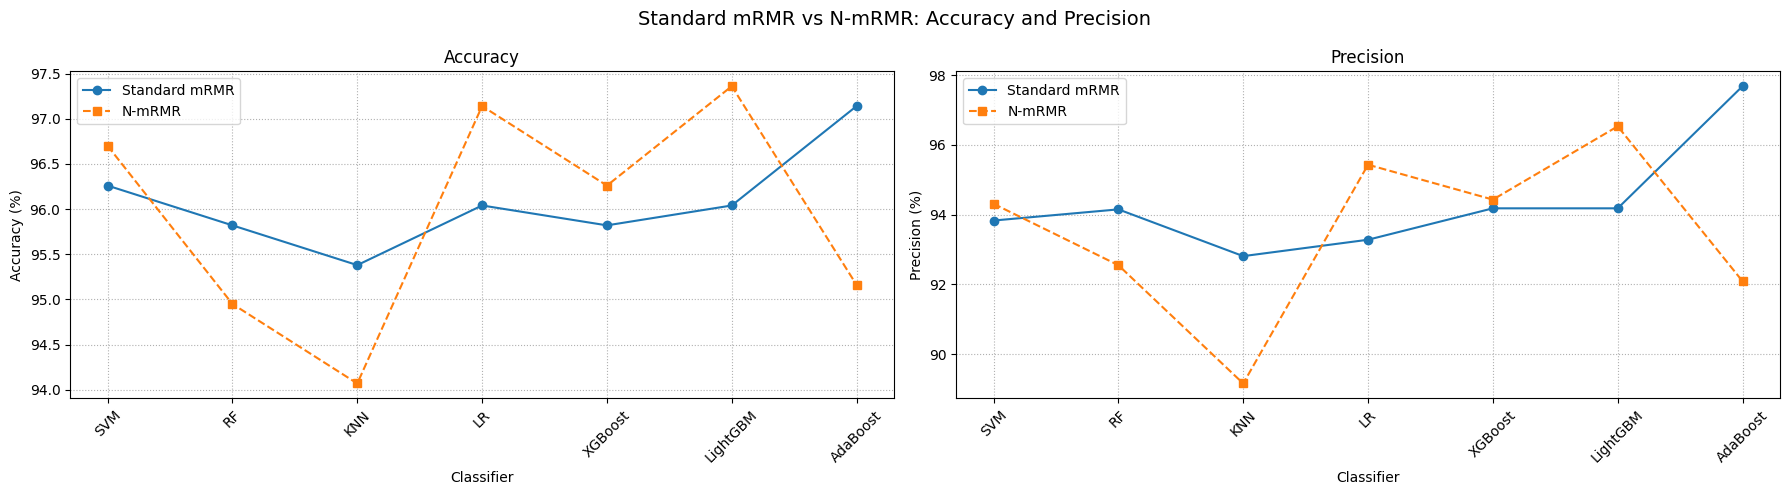

In [63]:
metrics = ["Accuracy", "Precision"]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

for ax, metric in zip(axes, metrics):
    ax.plot(
        base["Classifier"], base[metric],
        marker="o", linestyle="-", label="Standard mRMR"
    )
    ax.plot(
        nmrmr["Classifier"], nmrmr[metric],
        marker="s", linestyle="--", label="N-mRMR"
    )

    ax.set_title(metric)
    ax.set_xlabel("Classifier")
    ax.set_ylabel(f"{metric} (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle=":")
    ax.legend()

fig.suptitle(
    "Standard mRMR vs N-mRMR: Accuracy and Precision",
    fontsize=14
)
plt.tight_layout()
plt.savefig(
    "/kaggle/working/Accuracy_Precision_Comparison.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


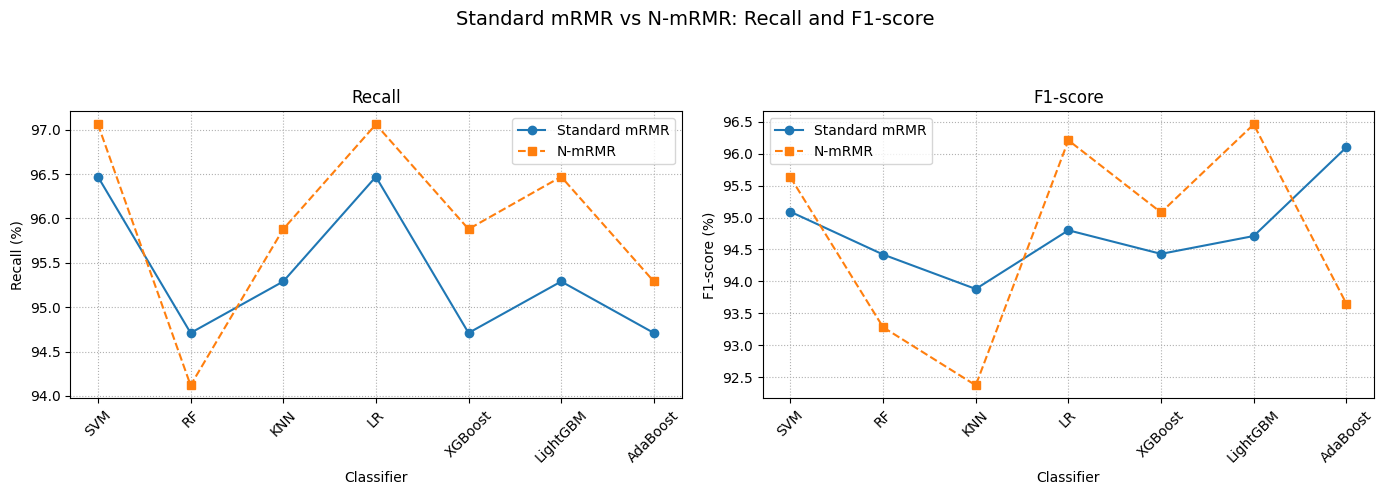

Figure saved to: /kaggle/working/Recall_F1_Comparison.png


In [64]:

import os
import matplotlib.pyplot as plt

# Only two metrics
metrics = ["Recall", "F1-score"]

# Check required columns
for name, df in [("base", base), ("nmrmr", nmrmr)]:
    required = ["Classifier"] + metrics
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Align classifier order
classifier_order = base["Classifier"].tolist()

if set(classifier_order) != set(nmrmr["Classifier"].tolist()):
    raise ValueError("Classifier names do not match between base and nmrmr.")

base_plot = base.set_index("Classifier").loc[classifier_order].reset_index()
nmrmr_plot = nmrmr.set_index("Classifier").loc[classifier_order].reset_index()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, metrics):
    ax.plot(
        base_plot["Classifier"],
        base_plot[metric],
        marker="o",
        linestyle="-",
        label="Standard mRMR"
    )

    ax.plot(
        nmrmr_plot["Classifier"],
        nmrmr_plot[metric],
        marker="s",
        linestyle="--",
        label="N-mRMR"
    )

    ax.set_title(metric)
    ax.set_xlabel("Classifier")
    ax.set_ylabel(f"{metric} (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle=":")
    ax.legend()

fig.suptitle(
    "Standard mRMR vs N-mRMR: Recall and F1-score",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

output_path = "/kaggle/working/Recall_F1_Comparison.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", output_path)


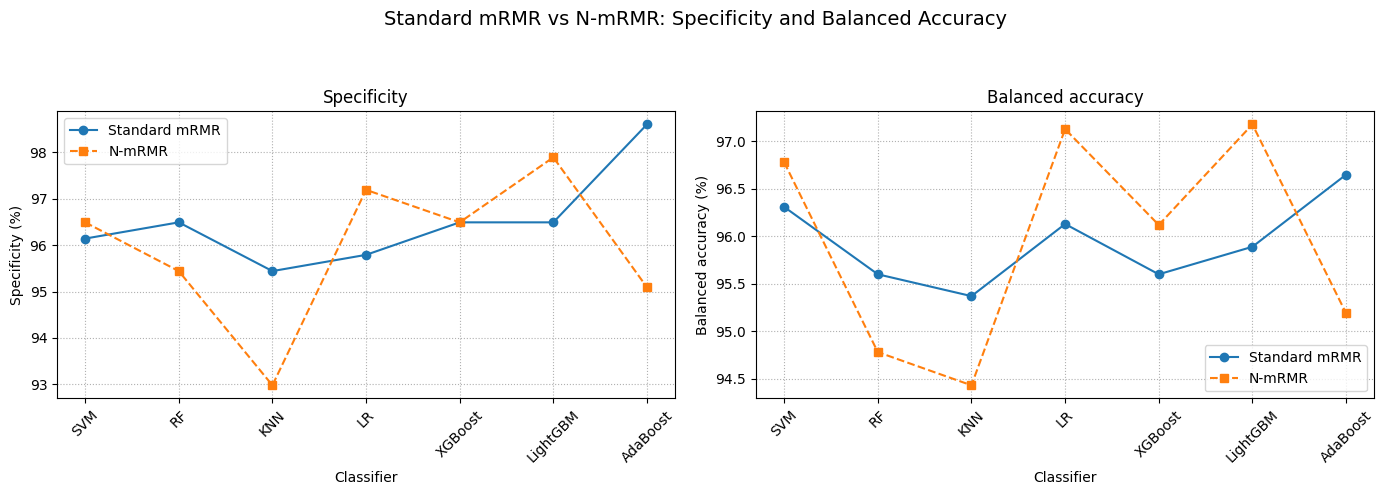

Figure saved to: /kaggle/working/Specificity_BalancedAccuracy_Comparison.png


In [65]:

import os
import matplotlib.pyplot as plt

# Only two metrics
metrics = ["Specificity", "Balanced accuracy"]

# Check required columns
for name, df in [("base", base), ("nmrmr", nmrmr)]:
    required = ["Classifier"] + metrics
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Align classifier order
classifier_order = base["Classifier"].tolist()

if set(classifier_order) != set(nmrmr["Classifier"].tolist()):
    raise ValueError("Classifier names do not match between base and nmrmr.")

base_plot = base.set_index("Classifier").loc[classifier_order].reset_index()
nmrmr_plot = nmrmr.set_index("Classifier").loc[classifier_order].reset_index()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, metrics):
    ax.plot(
        base_plot["Classifier"],
        base_plot[metric],
        marker="o",
        linestyle="-",
        label="Standard mRMR"
    )

    ax.plot(
        nmrmr_plot["Classifier"],
        nmrmr_plot[metric],
        marker="s",
        linestyle="--",
        label="N-mRMR"
    )

    ax.set_title(metric)
    ax.set_xlabel("Classifier")
    ax.set_ylabel(f"{metric} (%)")
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle=":")
    ax.legend()

fig.suptitle(
    "Standard mRMR vs N-mRMR: Specificity and Balanced Accuracy",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

output_path = "/kaggle/working/Specificity_BalancedAccuracy_Comparison.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", output_path)


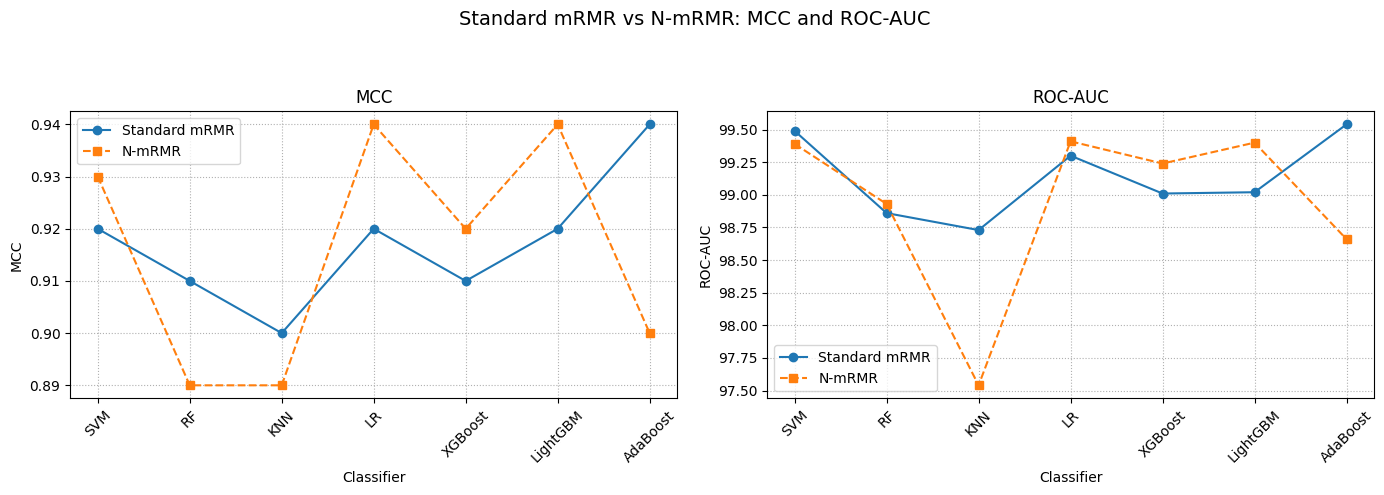

Figure saved to: /kaggle/working/MCC_ROC_AUC_Comparison.png


In [66]:

import os
import matplotlib.pyplot as plt

# Only two metrics
metrics = ["MCC", "ROC-AUC"]

# Check required columns
for name, df in [("base", base), ("nmrmr", nmrmr)]:
    required = ["Classifier"] + metrics
    missing = [col for col in required if col not in df.columns]
    if missing:
        raise ValueError(f"{name} is missing columns: {missing}")

# Align classifier order
classifier_order = base["Classifier"].tolist()

if set(classifier_order) != set(nmrmr["Classifier"].tolist()):
    raise ValueError("Classifier names do not match between base and nmrmr.")

base_plot = base.set_index("Classifier").loc[classifier_order].reset_index()
nmrmr_plot = nmrmr.set_index("Classifier").loc[classifier_order].reset_index()

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, metrics):
    ax.plot(
        base_plot["Classifier"],
        base_plot[metric],
        marker="o",
        linestyle="-",
        label="Standard mRMR"
    )

    ax.plot(
        nmrmr_plot["Classifier"],
        nmrmr_plot[metric],
        marker="s",
        linestyle="--",
        label="N-mRMR"
    )

    ax.set_title(metric)
    ax.set_xlabel("Classifier")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(True, linestyle=":")
    ax.legend()

fig.suptitle(
    "Standard mRMR vs N-mRMR: MCC and ROC-AUC",
    fontsize=14
)

plt.tight_layout(rect=[0, 0, 1, 0.92])

output_path = "/kaggle/working/MCC_ROC_AUC_Comparison.png"
plt.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", output_path)


STATISTICAL COMPARISON OF SEVEN CLASSIFIERS

In [68]:
# ============================================================
# WBCD: FRIEDMAN TEST FOR SEVEN CLASSIFIERS
# Eight evaluation metrics
# Holm correction across the eight metric-level tests
# ============================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import friedmanchisquare
from statsmodels.stats.multitest import multipletests
from IPython.display import display

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

CLASSIFIERS = [
    "SVM",
    "RF",
    "LightGBM",
    "XGBoost",
    "AdaBoost",
    "KNN",
    "Logistic Regression"
]

METRIC_RENAME = {
    "Accuracy (%)": "Accuracy (%)",
    "Precision (%)": "Precision (%)",
    "Recall (%)": "Recall (%)",
    "Specificity (%)": "Specificity (%)",
    "F1-score (%)": "F1-score (%)",
    "Balanced accuracy (%)": "Balanced accuracy (%)",
    "Balanced Accuracy (%)": "Balanced accuracy (%)",
    "MCC": "MCC",
    "ROC-AUC (%)": "ROC-AUC (%)"
}

METRICS = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

ALPHA = 0.05
EXPECTED_FOLDS = [1, 2, 3, 4, 5]

# ------------------------------------------------------------
# 2. INPUT FILES
# ------------------------------------------------------------

FILE_PATHS = {
    "SVM":
        "/kaggle/working/SVM_Nested_CV_Outer_Fold_Metrics.csv",

    "RF":
        "/kaggle/working/RF_Nested_CV_Outer_Fold_Metrics.csv",

    "LightGBM":
        "/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_5Fold_Results.csv",

    "XGBoost":
        "/kaggle/working/XGBoost_NMRMR_BorderlineSMOTE_OuterFold_Metrics.csv",

    "AdaBoost":
        "/kaggle/working/AdaBoost_NestedCV_OuterFold_Metrics.csv",

    "KNN":
        "/kaggle/working/KNN_NestedCV_OuterFold_Metrics.csv",

    "Logistic Regression":
        "/kaggle/working/WBCD_LogisticRegression_Clean_5Fold_Results.csv"
}

# ------------------------------------------------------------
# 3. LOAD AND VALIDATE EACH FILE
# ------------------------------------------------------------

all_frames = []

for classifier, path in FILE_PATHS.items():

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"\nFile not found for {classifier}:\n{path}\n"
            "Check the filename in the FILE_PATHS dictionary."
        )

    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    df = df.rename(columns=METRIC_RENAME)

    # Accept either Fold or Outer Fold as the fold column
    if "Fold" not in df.columns:
        if "Outer Fold" in df.columns:
            df = df.rename(columns={"Outer Fold": "Fold"})
        else:
            raise ValueError(
                f"{classifier}: no 'Fold' or 'Outer Fold' column "
                f"in {path}. Columns found: {df.columns.tolist()}"
            )

    df["Classifier"] = classifier

    missing_metrics = [
        metric for metric in METRICS
        if metric not in df.columns
    ]

    if missing_metrics:
        raise ValueError(
            f"{classifier}: missing metrics {missing_metrics}\n"
            f"Columns found: {df.columns.tolist()}"
        )

    df["Fold"] = pd.to_numeric(df["Fold"], errors="coerce")

    for metric in METRICS:
        df[metric] = pd.to_numeric(
            df[metric], errors="coerce"
        )

    if df["Fold"].isna().any():
        raise ValueError(
            f"{classifier}: invalid fold values found."
        )

    if df.duplicated(["Classifier", "Fold"]).any():
        raise ValueError(
            f"{classifier}: duplicate fold records in {path}."
        )

    if sorted(df["Fold"].astype(int).tolist()) != EXPECTED_FOLDS:
        raise ValueError(
            f"{classifier}: expected exactly folds "
            f"{EXPECTED_FOLDS}, but found "
            f"{sorted(df['Fold'].astype(int).tolist())}."
        )

    if df[METRICS].isna().any().any():
        raise ValueError(
            f"{classifier}: missing/non-numeric metric values."
        )

    all_frames.append(
        df[["Fold", "Classifier"] + METRICS].copy()
    )

# ------------------------------------------------------------
# 4. COMBINE DATA
# ------------------------------------------------------------

results_df = pd.concat(all_frames, ignore_index=True)

assert len(results_df) == 35
assert not results_df.duplicated(
    ["Classifier", "Fold"]
).any()

print("Dataset: WBCD")
print("Classifiers:", len(CLASSIFIERS))
print("Outer folds per classifier:", len(EXPECTED_FOLDS))
print("Total records:", len(results_df))

display(
    results_df.groupby("Classifier")["Fold"]
    .agg(["count", "nunique"])
)

results_df.to_csv(
    "/kaggle/working/WBCD_Statistical_Test_Input_35_Rows.csv",
    index=False
)

# ------------------------------------------------------------
# 5. FRIEDMAN TEST
# One overall test for each metric
# ------------------------------------------------------------

friedman_rows = []

for metric in METRICS:

    wide = results_df.pivot(
        index="Fold",
        columns="Classifier",
        values=metric
    ).reindex(
        index=EXPECTED_FOLDS,
        columns=CLASSIFIERS
    )

    if wide.isna().any().any():
        raise ValueError(
            f"Missing paired values for {metric}."
        )

    # Handle identical values across all classifiers
    if np.allclose(
        wide.to_numpy() - wide.iloc[:, [0]].to_numpy(),
        0
    ):
        statistic, p_value = 0.0, 1.0

    else:
        statistic, p_value = friedmanchisquare(
            *[
                wide[c].to_numpy(dtype=float)
                for c in CLASSIFIERS
            ]
        )

    friedman_rows.append({
        "Metric": metric,
        "Number of classifiers": len(CLASSIFIERS),
        "Number of folds": len(EXPECTED_FOLDS),
        "Friedman statistic": statistic,
        "p-value": p_value,
        "Significant at 0.05": p_value < ALPHA
    })

# ------------------------------------------------------------
# 6. HOLM CORRECTION
# Across the eight metric-level Friedman tests
# ------------------------------------------------------------

friedman_df = pd.DataFrame(friedman_rows)

friedman_df["Holm-adjusted p-value"] = multipletests(
    friedman_df["p-value"].to_numpy(),
    alpha=ALPHA,
    method="holm"
)[1]

friedman_df["Significant after Holm"] = (
    friedman_df["Holm-adjusted p-value"] < ALPHA
)

# ------------------------------------------------------------
# 7. DISPLAY AND SAVE RESULTS
# ------------------------------------------------------------

print("\nFRIEDMAN TEST RESULTS")
display(friedman_df.round(6))

friedman_df.to_csv(
    "/kaggle/working/WBCD_Friedman_Test_Results.csv",
    index=False
)

print("\nFriedman test results saved successfully.")
print("Files saved in /kaggle/working/:")
print("1. WBCD_Statistical_Test_Input_35_Rows.csv")
print("2. WBCD_Friedman_Test_Results.csv")

Dataset: WBCD
Classifiers: 7
Outer folds per classifier: 5
Total records: 35


,count,nunique
Classifier,,
AdaBoost,5,5
KNN,5,5
LightGBM,5,5
Logistic Regression,5,5
RF,5,5
SVM,5,5
XGBoost,5,5



FRIEDMAN TEST RESULTS


,Metric,Number of classifiers,Number of folds,Friedman statistic,p-value,Significant at 0.05,Holm-adjusted p-value,Significant after Holm
0,Accuracy (%),7,5,14.783270,0.022011,True,0.146109,False
1,Precision (%),7,5,14.921933,0.020873,True,0.146109,False
2,Recall (%),7,5,6.375000,0.382519,False,0.382519,False
3,Specificity (%),7,5,12.341463,0.054771,False,0.146109,False
4,F1-score (%),7,5,14.520446,0.024333,True,0.146109,False
5,Balanced accuracy (%),7,5,12.914498,0.044414,True,0.146109,False
6,MCC,7,5,14.520446,0.024333,True,0.146109,False
7,ROC-AUC (%),7,5,16.446043,0.011550,True,0.092399,False



Friedman test results saved successfully.
Files saved in /kaggle/working/:
1. WBCD_Statistical_Test_Input_35_Rows.csv
2. WBCD_Friedman_Test_Results.csv


In [72]:
# ============================================================
# WBCD: PEARSON'S CORRELATION BETWEEN PERFORMANCE METRICS
# Eight performance metrics
# Pearson correlation + Holm correction
# ============================================================

import os
import numpy as np
import pandas as pd

from itertools import combinations
from scipy.stats import pearsonr
from statsmodels.stats.multitest import multipletests
from IPython.display import display

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

METRICS = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

ALPHA = 0.05

# ------------------------------------------------------------
# 2. USE EXISTING RESULTS_DF OR LOAD CLASSIFIER FILES
# ------------------------------------------------------------

if (
    "results_df" in globals()
    and isinstance(results_df, pd.DataFrame)
    and not results_df.empty
):

    results_df = results_df.copy()
    print("Using existing results_df.")

else:

    FILE_PATHS = {
        "SVM":
            "/kaggle/working/SVM_Nested_CV_Outer_Fold_Metrics.csv",

        "RF":
            "/kaggle/working/RF_Nested_CV_Outer_Fold_Metrics.csv",

        "LightGBM":
            "/kaggle/working/WBCD_LightGBM_NmRMR_SMOTE_5Fold_Results.csv",

        "XGBoost":
            "/kaggle/working/XGBoost_NMRMR_BorderlineSMOTE_OuterFold_Metrics.csv",

        "AdaBoost":
            "/kaggle/working/AdaBoost_NestedCV_OuterFold_Metrics.csv",

        "KNN":
            "/kaggle/working/KNN_NestedCV_OuterFold_Metrics.csv",

        "Logistic Regression":
            "/kaggle/working/WBCD_LogisticRegression_Clean_5Fold_Results.csv"
    }

    all_frames = []

    for classifier, path in FILE_PATHS.items():

        if not os.path.exists(path):
            raise FileNotFoundError(
                f"File not found for {classifier}: {path}"
            )

        df = pd.read_csv(path)
        df.columns = df.columns.str.strip()

        if "Fold" not in df.columns:
            if "Outer Fold" in df.columns:
                df = df.rename(
                    columns={"Outer Fold": "Fold"}
                )
            else:
                raise ValueError(
                    f"{classifier}: Fold column not found."
                )

        df["Classifier"] = classifier

        all_frames.append(df)

    results_df = pd.concat(
        all_frames,
        ignore_index=True
    )

    print("Loaded results from seven classifier CSV files.")

# ------------------------------------------------------------
# 3. STANDARDIZE METRIC COLUMN NAMES
# ------------------------------------------------------------

COLUMN_ALIASES = {
    "Accuracy": "Accuracy (%)",
    "Precision": "Precision (%)",
    "Recall": "Recall (%)",
    "Specificity": "Specificity (%)",
    "F1-score": "F1-score (%)",
    "F1 Score": "F1-score (%)",
    "Balanced Accuracy": "Balanced accuracy (%)",
    "Balanced accuracy": "Balanced accuracy (%)",
    "Balanced Accuracy (%)": "Balanced accuracy (%)",
    "MCC": "MCC",
    "ROC-AUC": "ROC-AUC (%)",
    "ROC AUC": "ROC-AUC (%)"
}

rename_columns = {}

for col in results_df.columns:

    if col in COLUMN_ALIASES:
        target = COLUMN_ALIASES[col]

        if target not in results_df.columns:
            rename_columns[col] = target

results_df = results_df.rename(
    columns=rename_columns
)

# ------------------------------------------------------------
# 4. VALIDATE METRIC COLUMNS
# ------------------------------------------------------------

missing_metrics = [
    metric for metric in METRICS
    if metric not in results_df.columns
]

if missing_metrics:
    raise ValueError(
        f"Missing metric columns: {missing_metrics}\n"
        f"Available columns: {results_df.columns.tolist()}"
    )

for metric in METRICS:

    results_df[metric] = pd.to_numeric(
        results_df[metric],
        errors="coerce"
    )

print("\nResults DataFrame shape:", results_df.shape)
print("Number of observations:", len(results_df))
print("Metrics used:", METRICS)

# ------------------------------------------------------------
# 5. CALCULATE PEARSON CORRELATIONS
# ------------------------------------------------------------

correlation_rows = []

for metric_a, metric_b in combinations(METRICS, 2):

    x = results_df[metric_a]
    y = results_df[metric_b]

    valid = x.notna() & y.notna()

    x_valid = x.loc[valid]
    y_valid = y.loc[valid]

    n = len(x_valid)

    if (
        n >= 3
        and x_valid.nunique() > 1
        and y_valid.nunique() > 1
    ):

        r, p_value = pearsonr(
            x_valid,
            y_valid
        )

    else:
        r, p_value = np.nan, np.nan

    correlation_rows.append({
        "Metric 1": metric_a,
        "Metric 2": metric_b,
        "Pearson r": r,
        "p-value": p_value,
        "Number of observations": n
    })

pearson_df = pd.DataFrame(correlation_rows)

# ------------------------------------------------------------
# 6. HOLM MULTIPLE-TEST CORRECTION
# ------------------------------------------------------------

pearson_df["Holm-adjusted p-value"] = np.nan

valid_p = (
    pearson_df["p-value"].notna()
    & np.isfinite(pearson_df["p-value"])
)

if valid_p.any():

    adjusted_p = multipletests(
        pearson_df.loc[
            valid_p, "p-value"
        ].to_numpy(),
        method="holm"
    )[1]

    pearson_df.loc[
        valid_p, "Holm-adjusted p-value"
    ] = adjusted_p

pearson_df["Significant"] = (
    pearson_df["Holm-adjusted p-value"] < ALPHA
).fillna(False).astype(bool)

pearson_df["Absolute Pearson r"] = (
    pearson_df["Pearson r"].abs()
)

pearson_df = pearson_df.sort_values(
    by="Absolute Pearson r",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

# ------------------------------------------------------------
# 7. SAVE RESULTS
# ------------------------------------------------------------

OUTPUT_DIR = "/kaggle/working"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

pearson_path = os.path.join(
    OUTPUT_DIR,
    "WBCD_Pearson_Correlation_Results.csv"
)

pearson_df.to_csv(
    pearson_path,
    index=False
)

# ------------------------------------------------------------
# 8. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PEARSON CORRELATION RESULTS")
print("=" * 70)

display(
    pearson_df.round(6)
)

print("\nSignificance summary after Holm correction:")
print(pearson_df["Significant"].value_counts())

print("\nTotal metric pairs:", len(pearson_df))
print(
    "Valid correlations:",
    pearson_df["Pearson r"].notna().sum()
)
print(
    "Significant correlations:",
    pearson_df["Significant"].sum()
)

print("\nSaved:", pearson_path)

Using existing results_df.

Results DataFrame shape: (35, 10)
Number of observations: 35
Metrics used: ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'Specificity (%)', 'F1-score (%)', 'Balanced accuracy (%)', 'MCC', 'ROC-AUC (%)']

PEARSON CORRELATION RESULTS


,Metric 1,Metric 2,Pearson r,p-value,Number of observations,Holm-adjusted p-value,Significant,Absolute Pearson r
0,F1-score (%),MCC,0.999784,0.000000,35,0.000000,True,0.999784
1,Accuracy (%),MCC,0.998808,0.000000,35,0.000000,True,0.998808
2,Accuracy (%),F1-score (%),0.997888,0.000000,35,0.000000,True,0.997888
3,Precision (%),Specificity (%),0.997545,0.000000,35,0.000000,True,0.997545
4,F1-score (%),Balanced accuracy (%),0.981192,0.000000,35,0.000000,True,0.981192
5,Balanced accuracy (%),MCC,0.978044,0.000000,35,0.000000,True,0.978044
6,Accuracy (%),Balanced accuracy (%),0.968108,0.000000,35,0.000000,True,0.968108
7,Accuracy (%),Precision (%),0.860051,0.000000,35,0.000000,True,0.860051
8,Precision (%),MCC,0.837474,0.000000,35,0.000000,True,0.837474
9,Accuracy (%),Specificity (%),0.833100,0.000000,35,0.000000,True,0.833100



Significance summary after Holm correction:
Significant
True     25
False     3
Name: count, dtype: int64

Total metric pairs: 28
Valid correlations: 28
Significant correlations: 25

Saved: /kaggle/working/WBCD_Pearson_Correlation_Results.csv


Normality Test 

Dataset shape: (35, 10)
Number of metrics: 8

SHAPIRO-WILK TEST RESULTS


,Metric,Sample size,Shapiro-Wilk W,p-value,Decision
0,Accuracy (%),35,0.940204,0.056765,Normal distribution
1,Precision (%),35,0.935943,0.042154,Not normally distributed
2,Recall (%),35,0.849259,0.000222,Not normally distributed
3,Specificity (%),35,0.910873,0.007853,Not normally distributed
4,F1-score (%),35,0.955687,0.169282,Normal distribution
5,Balanced accuracy (%),35,0.959763,0.224942,Normal distribution
6,MCC,35,0.951911,0.129723,Normal distribution
7,ROC-AUC (%),35,0.712721,0.000001,Not normally distributed



ANDERSON-DARLING TEST RESULTS


,Metric,Sample size,Anderson-Darling statistic,Critical value (5%),Decision
0,Accuracy (%),35,0.864522,0.719,Not normally distributed
1,Precision (%),35,0.999516,0.719,Not normally distributed
2,Recall (%),35,2.457859,0.719,Not normally distributed
3,Specificity (%),35,1.402813,0.719,Not normally distributed
4,F1-score (%),35,0.628645,0.719,Normal distribution
5,Balanced accuracy (%),35,0.382482,0.719,Normal distribution
6,MCC,35,0.689422,0.719,Normal distribution
7,ROC-AUC (%),35,2.760631,0.719,Not normally distributed



SKEWNESS AND KURTOSIS RESULTS


,Metric,Sample size,Skewness,Excess kurtosis
0,Accuracy (%),35,-0.318458,-0.594292
1,Precision (%),35,-0.328347,-0.317939
2,Recall (%),35,-0.833465,1.327556
3,Specificity (%),35,-0.508430,-0.218789
4,F1-score (%),35,-0.310374,-0.487211
5,Balanced accuracy (%),35,-0.398440,-0.114202
6,MCC,35,-0.299875,-0.523697
7,ROC-AUC (%),35,-2.734480,9.489069


<Figure size 700x500 with 0 Axes>

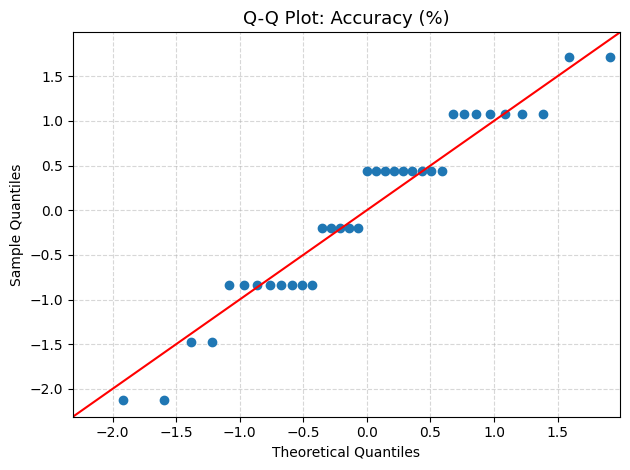

<Figure size 700x500 with 0 Axes>

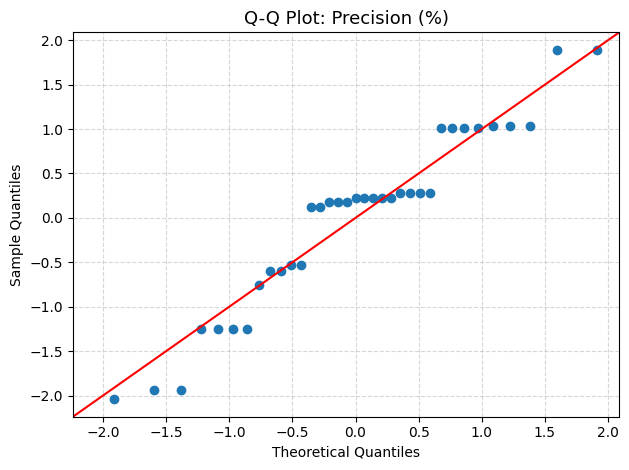

<Figure size 700x500 with 0 Axes>

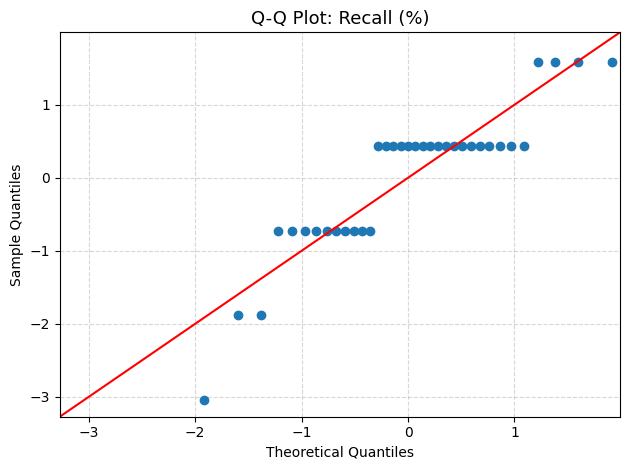

<Figure size 700x500 with 0 Axes>

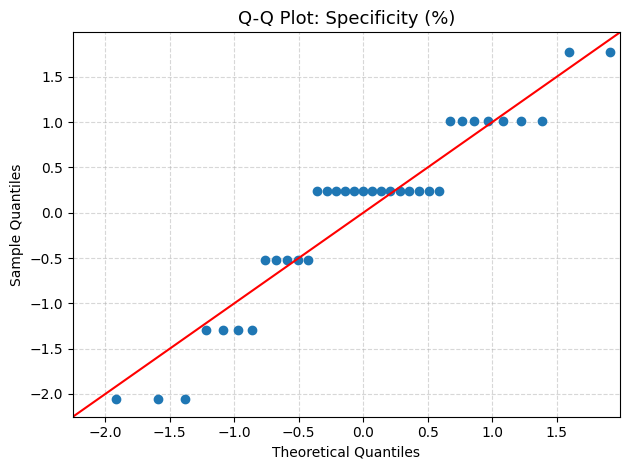

<Figure size 700x500 with 0 Axes>

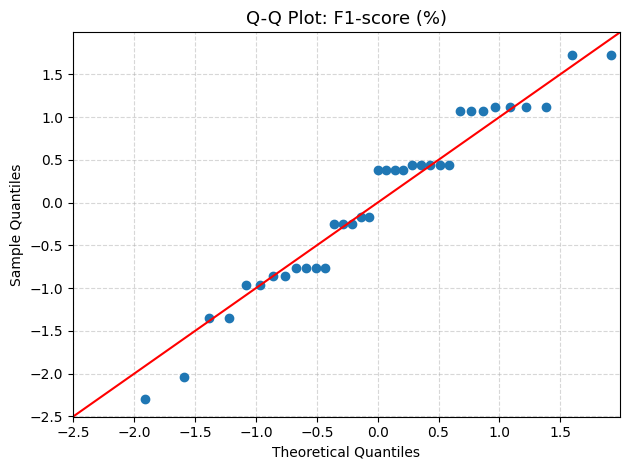

<Figure size 700x500 with 0 Axes>

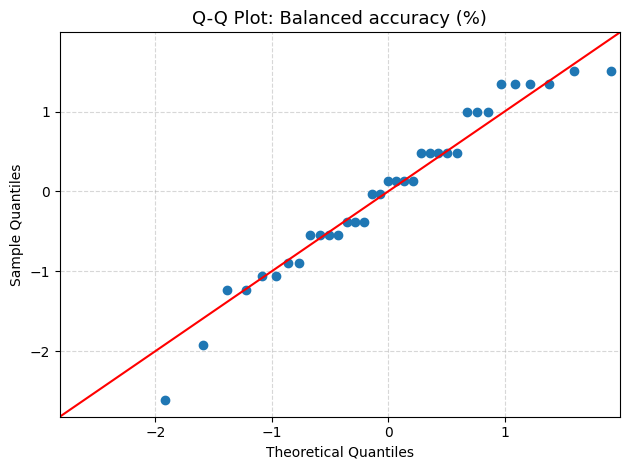

<Figure size 700x500 with 0 Axes>

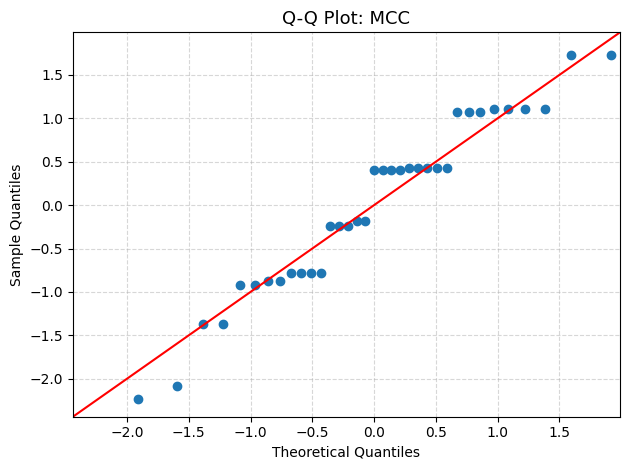

<Figure size 700x500 with 0 Axes>

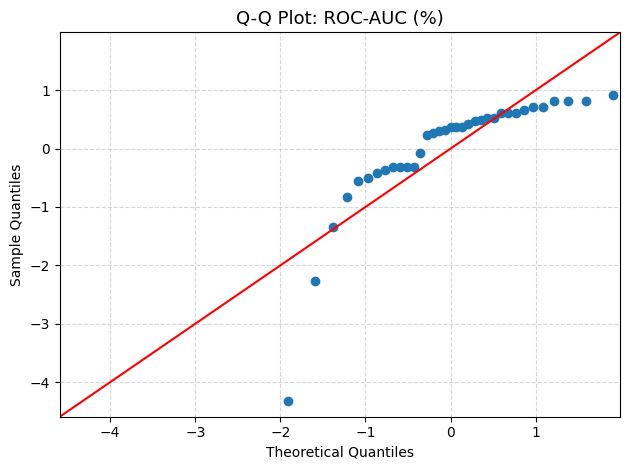


NORMALITY ANALYSIS COMPLETED

Files saved in: /kaggle/working
1. WBCD_Shapiro_Wilk_Test_Results.csv
2. WBCD_Anderson_Darling_Test_Results.csv
3. WBCD_Skewness_Kurtosis_Results.csv
4. Eight individual Q-Q plot PNG files


In [73]:
# ============================================================
# WBCD: NORMALITY TESTS AND DISTRIBUTION ANALYSIS
#
# 1. Shapiro-Wilk test
# 2. Anderson-Darling test
# 3. Q-Q plots
# 4. Skewness
# 5. Kurtosis
#
# Input: results_df (7 classifiers x 5 outer folds)
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

from scipy.stats import (
    shapiro,
    anderson,
    skew,
    kurtosis
)

from statsmodels.graphics.gofplots import qqplot
from IPython.display import display

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

METRICS = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "Specificity (%)",
    "F1-score (%)",
    "Balanced accuracy (%)",
    "MCC",
    "ROC-AUC (%)"
]

ALPHA = 0.05

OUTPUT_DIR = "/kaggle/working"

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# 2. CHECK INPUT DATA
# ------------------------------------------------------------

if (
    "results_df" not in globals()
    or not isinstance(results_df, pd.DataFrame)
    or results_df.empty
):
    raise ValueError(
        "results_df is missing or empty. "
        "Run the classifier results loading code first."
    )

results_df = results_df.copy()

missing_metrics = [
    metric for metric in METRICS
    if metric not in results_df.columns
]

if missing_metrics:
    raise ValueError(
        f"Missing metric columns: {missing_metrics}"
    )

for metric in METRICS:
    results_df[metric] = pd.to_numeric(
        results_df[metric],
        errors="coerce"
    )

print("Dataset shape:", results_df.shape)
print("Number of metrics:", len(METRICS))

# ------------------------------------------------------------
# 3. SHAPIRO-WILK TEST
# ------------------------------------------------------------

shapiro_rows = []

for metric in METRICS:

    values = results_df[metric].dropna().to_numpy()

    if len(values) >= 3:

        W_statistic, p_value = shapiro(values)

        decision = (
            "Normal distribution"
            if p_value >= ALPHA
            else "Not normally distributed"
        )

    else:
        W_statistic = np.nan
        p_value = np.nan
        decision = "Insufficient observations"

    shapiro_rows.append({
        "Metric": metric,
        "Sample size": len(values),
        "Shapiro-Wilk W": W_statistic,
        "p-value": p_value,
        "Decision": decision
    })

shapiro_df = pd.DataFrame(shapiro_rows)

print("\nSHAPIRO-WILK TEST RESULTS")
display(shapiro_df.round(6))

shapiro_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "WBCD_Shapiro_Wilk_Test_Results.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 4. ANDERSON-DARLING TEST
# ------------------------------------------------------------

anderson_rows = []

for metric in METRICS:

    values = results_df[metric].dropna().to_numpy()

    if len(values) >= 3:

        result = anderson(
            values,
            dist="norm"
        )

        statistic = result.statistic

        # Critical value corresponding to 5% significance
        index_5 = np.where(
            np.isclose(
                result.significance_level,
                5.0
            )
        )[0]

        if len(index_5) > 0:

            critical_value = result.critical_values[index_5[0]]

            decision = (
                "Normal distribution"
                if statistic < critical_value
                else "Not normally distributed"
            )

        else:
            critical_value = np.nan
            decision = "5% critical value unavailable"

    else:
        statistic = np.nan
        critical_value = np.nan
        decision = "Insufficient observations"

    anderson_rows.append({
        "Metric": metric,
        "Sample size": len(values),
        "Anderson-Darling statistic": statistic,
        "Critical value (5%)": critical_value,
        "Decision": decision
    })

anderson_df = pd.DataFrame(anderson_rows)

print("\nANDERSON-DARLING TEST RESULTS")
display(anderson_df.round(6))

anderson_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "WBCD_Anderson_Darling_Test_Results.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 5. SKEWNESS AND KURTOSIS
# ------------------------------------------------------------

distribution_rows = []

for metric in METRICS:

    values = results_df[metric].dropna().to_numpy()

    if len(values) >= 3:

        skewness_value = skew(
            values,
            bias=False
        )

        kurtosis_value = kurtosis(
            values,
            fisher=True,
            bias=False
        )

    else:
        skewness_value = np.nan
        kurtosis_value = np.nan

    distribution_rows.append({
        "Metric": metric,
        "Sample size": len(values),
        "Skewness": skewness_value,
        "Excess kurtosis": kurtosis_value
    })

distribution_df = pd.DataFrame(distribution_rows)

print("\nSKEWNESS AND KURTOSIS RESULTS")
display(distribution_df.round(6))

distribution_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "WBCD_Skewness_Kurtosis_Results.csv"
    ),
    index=False
)

# ------------------------------------------------------------
# 6. Q-Q PLOTS
# One Q-Q plot for each performance metric
# ------------------------------------------------------------

for metric in METRICS:

    values = results_df[metric].dropna().to_numpy()

    if len(values) < 3:
        print(f"Skipping Q-Q plot for {metric}: insufficient data.")
        continue

    plt.figure(figsize=(7, 5))

    qqplot(
        values,
        line="45",
        fit=True
    )

    plt.title(
        f"Q-Q Plot: {metric}",
        fontsize=13
    )

    plt.xlabel("Theoretical Quantiles")
    plt.ylabel("Sample Quantiles")

    plt.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    plt.tight_layout()

    filename = (
        metric.replace(" ", "_")
        .replace("(", "")
        .replace(")", "")
        .replace("%", "percent")
        .replace("-", "_")
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"WBCD_QQ_Plot_{filename}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\nNORMALITY ANALYSIS COMPLETED")

print("\nFiles saved in:", OUTPUT_DIR)

print("1. WBCD_Shapiro_Wilk_Test_Results.csv")
print("2. WBCD_Anderson_Darling_Test_Results.csv")
print("3. WBCD_Skewness_Kurtosis_Results.csv")
print("4. Eight individual Q-Q plot PNG files")